<div style="
border:3px solid #2c3e50;
border-radius:20px;
padding:28px;
margin:20px auto;
background:#f8fafc;
box-shadow:0 6px 18px rgba(0,0,0,0.15);
max-width:95%;
">

<div align="center">

<h1 style="font-size:36px; color:#2c3e50; margin-bottom:10px;">Projet Visualisation des données</h1>

<h4 style="font-size:19px; color:#34495e; margin-top:16px;">
<b>Module :</b> Visualisation des données &nbsp;|&nbsp;
<b>Filière :</b> Big Data et Intelligence Artificielle  <br>
<b>Prof :</b> Ikhlass Boukrouh &nbsp;
</h3>


</div>
</div>

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="seaborn")

# Data info

In [3]:
data = pd.read_csv("ds_salaries.csv")
data.head()

,Unnamed: 0,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,0,2020,MI,FT,Data Scientist,70000,EUR,79833,DE,0,DE,L
1,1,2020,SE,FT,Machine Learning Scientist,260000,USD,260000,JP,0,JP,S
2,2,2020,SE,FT,Big Data Engineer,85000,GBP,109024,GB,50,GB,M
3,3,2020,MI,FT,Product Data Analyst,20000,USD,20000,HN,0,HN,S
4,4,2020,SE,FT,Machine Learning Engineer,150000,USD,150000,US,50,US,L


In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 607 entries, 0 to 606
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Unnamed: 0          607 non-null    int64
 1   work_year           607 non-null    int64
 2   experience_level    607 non-null    str  
 3   employment_type     607 non-null    str  
 4   job_title           607 non-null    str  
 5   salary              607 non-null    int64
 6   salary_currency     607 non-null    str  
 7   salary_in_usd       607 non-null    int64
 8   employee_residence  607 non-null    str  
 9   remote_ratio        607 non-null    int64
 10  company_location    607 non-null    str  
 11  company_size        607 non-null    str  
dtypes: int64(5), str(7)
memory usage: 57.0 KB


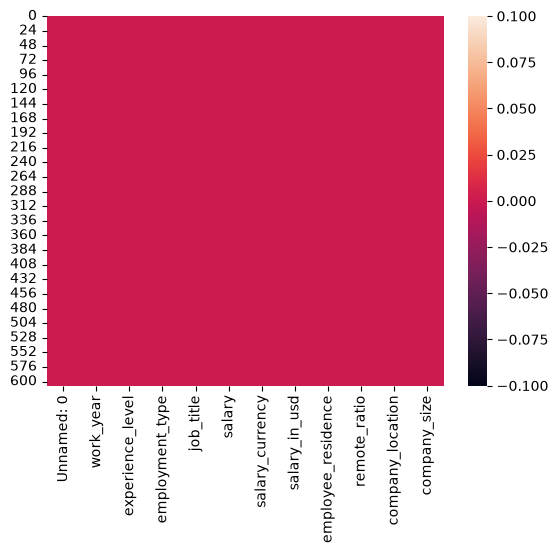

In [5]:
sns.heatmap(data.isnull())
plt.show()

In [6]:
data.dtypes

Unnamed: 0            int64
work_year             int64
experience_level        str
employment_type         str
job_title               str
salary                int64
salary_currency         str
salary_in_usd         int64
employee_residence      str
remote_ratio          int64
company_location        str
company_size            str
dtype: object

In [7]:
data.nunique()

Unnamed: 0            607
work_year               3
experience_level        4
employment_type         4
job_title              50
salary                272
salary_currency        17
salary_in_usd         369
employee_residence     57
remote_ratio            3
company_location       50
company_size            3
dtype: int64

# 2. Analyse univarieé

## 2.1 Variables Numériques

### 2.1.1 Salaire en USD/an

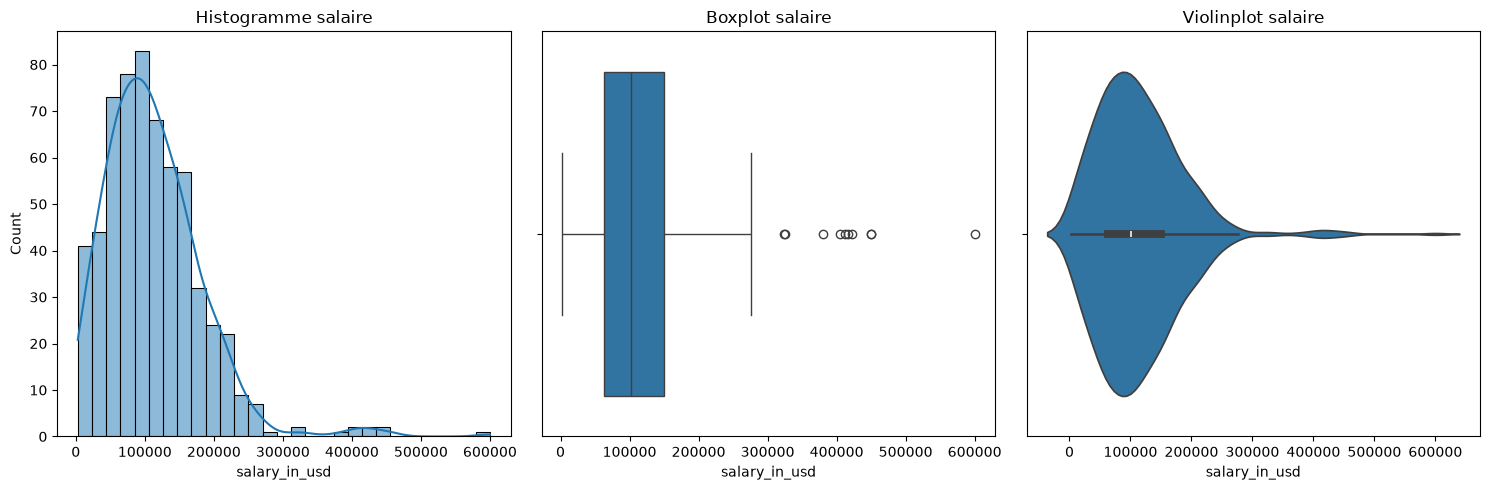

In [8]:
plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
sns.histplot(data["salary_in_usd"], kde=True)
plt.title("Histogramme salaire")

plt.subplot(1,3,2)
sns.boxplot(x=data["salary_in_usd"])
plt.title("Boxplot salaire")

plt.subplot(1,3,3)
sns.violinplot(x=data["salary_in_usd"])
plt.title("Violinplot salaire")

plt.tight_layout()
plt.show()

- La boîte est concentrée entre environ 80 000 et 150 000 USD, avec une médiane située autour de 100 000 USD. Les moustaches s’étendent vers des valeurs plus faibles et plus élevées.
On observe plusieurs points isolés à droite du graphique, correspondant à des valeurs élevées de salaire.
- La majorité des observations est concentrée entre environ 50 000 et 150 000 USD, où les barres sont les plus hautes.
La fréquence diminue progressivement lorsque le salaire augmente, et on observe quelques valeurs élevées au-delà de 300 000 USD, ce qui crée une longue queue vers la droite du graphique.
- La partie la plus large du violon se situe autour de 80 000 à 150 000 USD, ce qui indique que la majorité des salaires est concentrée dans cette zone.
La forme s’étend davantage vers les valeurs élevées, avec une longue partie fine à droite, montrant la présence de salaires élevés mais peu fréquents.
- Les trois graphiques montrent que la majorité des salaires est concentrée entre 80 000 et 150 000 USD.
Cependant, la distribution est asymétrique à droite, avec quelques salaires très élevés qui augmentent la dispersion.
Cela indique une concentration des revenus moyens et la présence de valeurs élevées peu fréquentes.

### 2.1.2 Type de travail

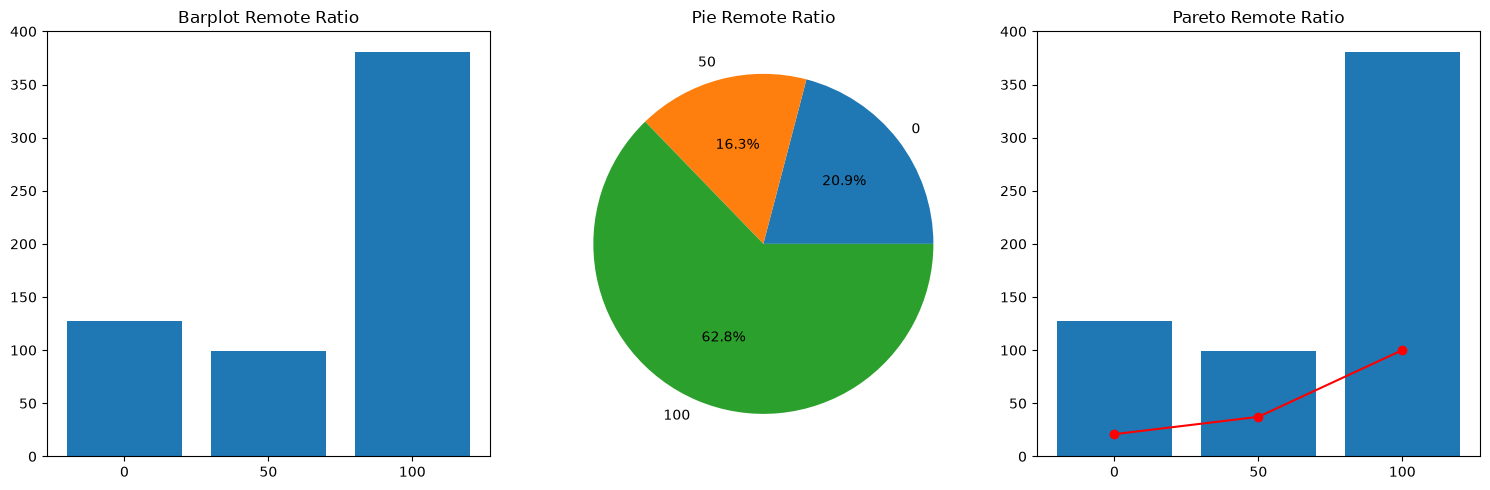

In [9]:
#Même si cette colonne est numérique , elle a seulement 3 valeurs.

counts = data['remote_ratio'].value_counts().sort_index()
cum = counts.cumsum() / counts.sum() * 100

plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.bar(counts.index.astype(str), counts.values)
plt.title("Barplot Remote Ratio")

plt.subplot(1,3,2)
plt.pie(counts.values, labels=counts.index, autopct='%1.1f%%')
plt.title("Pie Remote Ratio")

plt.subplot(1,3,3)
plt.bar(counts.index.astype(str), counts.values)
plt.plot(counts.index.astype(str), cum, color='red', marker='o')
plt.title("Pareto Remote Ratio")

plt.tight_layout()
plt.show()

- La catégorie 100 (Remote) est la plus élevée. Ensuite vient 0 (On-site). Enfin 50 (Hybrid).
- La majorité des employés travaillent 100% à distance.
- Le travail sur site et hybride représentent une part beaucoup plus faible.

Cela montre que : Le secteur de la Data Science est fortement orienté vers le télétravail.

- Le diagramme circulaire montre que la majorité des employés travaillent entièrement à distance.
- Le travail sur site et hybride représentent une proportion plus faible.
- Cela confirme que le télétravail domine dans le domaine de la Data Science.


- Le diagramme de Pareto montre que la catégorie Remote Ratio = 100 est largement dominante, avec plus de 60 % des observations, ce qui indique que la majorité des cas correspondent à un travail totalement à distance.
- La courbe cumulée confirme que cette seule catégorie contribue de manière significative au total global.
- En ajoutant la catégorie Remote Ratio = 0, le pourcentage cumulé atteint environ 85 %, ce qui signifie que ces deux catégories expliquent l’essentiel du phénomène étudié.
- La catégorie Remote Ratio = 50 présente une fréquence nettement plus faible et a donc un impact marginal sur le résultat global.
- Ainsi, selon le principe de Pareto, l’analyse et la prise de décision doivent se concentrer principalement sur les catégories les plus contributives, en particulier le Remote Ratio = 100.


- La majorité des employés travaillent 100 % à distance (≈63 %).
- Le travail sur site (≈21 %) et hybride (≈16 %) sont moins représentés.
- Globalement, le secteur est fortement orienté vers le télétravail.

## 2.2 Variables Qualitatives

### 2.2.1 Nom de spécialité

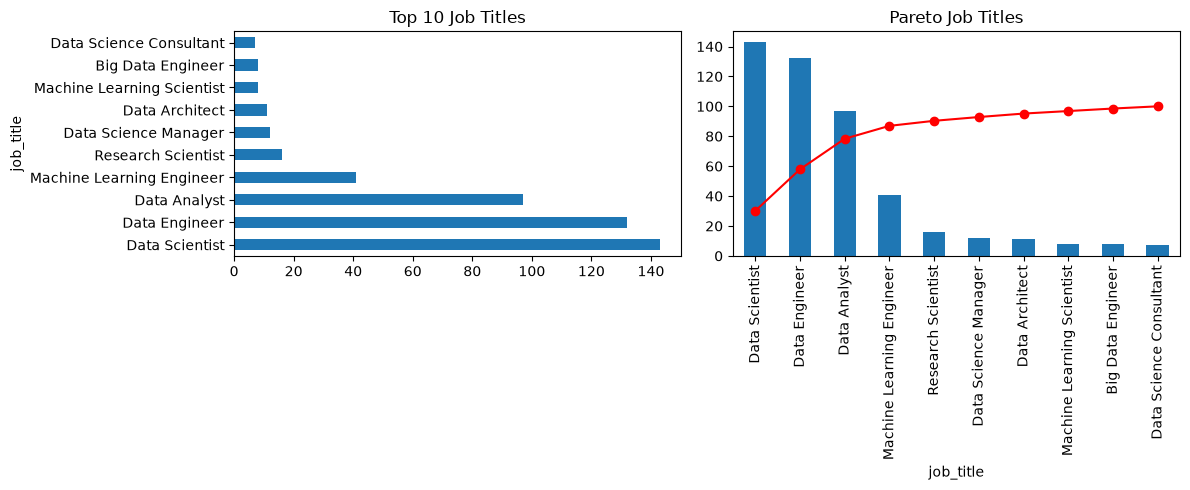

In [10]:
freq = data['job_title'].value_counts().head(10)
cum = freq.cumsum() / freq.sum() * 100
#il existe dans je jeu de données 50 différent postes mais on affiche les 10 plus fréquents

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
freq.plot(kind='barh')
plt.title("Top 10 Job Titles")

plt.subplot(1,2,2)
freq.plot(kind='bar')
plt.plot(cum.values, color='red', marker='o')
plt.title("Pareto Job Titles")

plt.tight_layout()
plt.show()

- Le graphique montre les 10 postes les plus fréquents dans le dataset.
Les postes Data Scientist, Data Engineer et Data Analyst sont les plus représentés.
Les autres postes apparaissent avec des effectifs nettement plus faibles.
- Le diagramme de Pareto montre que quelques postes seulement concentrent la majorité des observations.
La courbe cumulée augmente rapidement et atteint un pourcentage élevé après les trois premiers postes.
Cela indique que la distribution des intitulés de poste est dominée par un petit nombre de catégories.
- Les postes Data Scientist, Data Engineer et Data Analyst dominent largement le dataset.
- La majorité des observations est concentrée dans quelques métiers seulement.

### 2.2.2 Pays de résidence

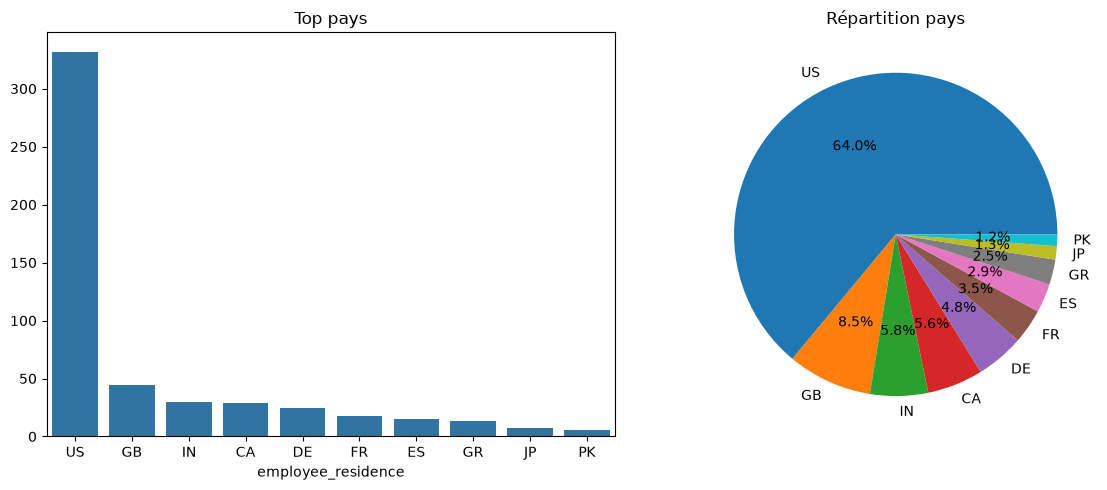

In [11]:
top_pays = data['employee_residence'].value_counts().head(10)

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.barplot(x=top_pays.index, y=top_pays.values)
plt.title("Top pays")

plt.subplot(1,2,2)
plt.pie(top_pays.values, labels=top_pays.index, autopct='%1.1f%%')
plt.title("Répartition pays")

plt.tight_layout()
plt.show()

Analyse de la variable employee_residence (pays de résidence)
Le diagramme en barres montre que les États-Unis (US) dominent très largement le jeu de données, suivis par le Royaume-Uni (GB) 
et les Pays-Bas (NL).
On observe une forte concentration géographique : la majorité des employés résident dans des pays occidentaux,
avec une présence notable de pays européens (France, Allemagne, Espagne, Grèce, Portugal).
Cela indique que le jeu de données reflète principalement le marché de l'emploi data aux États-Unis et en Europe de l'Ouest.

### 2.2.3   Niveau d'expérience

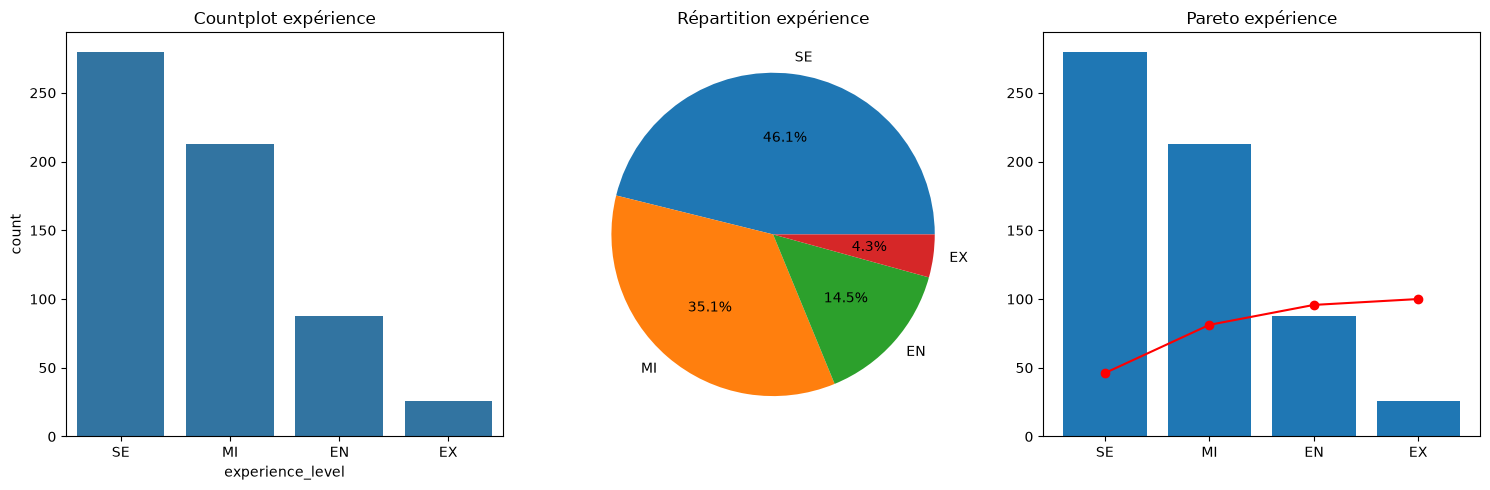

In [12]:
counts = data['experience_level'].value_counts()
cum = counts.cumsum() / counts.sum() * 100

plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
sns.countplot(x=data["experience_level"], order=counts.index)
plt.title("Countplot expérience")

plt.subplot(1,3,2)
plt.pie(counts.values, labels=counts.index, autopct='%1.1f%%')
plt.title("Répartition expérience")

plt.subplot(1,3,3)
plt.bar(counts.index, counts.values)
plt.plot(counts.index, cum, color='red', marker='o')
plt.title("Pareto expérience")

plt.tight_layout()
plt.show()

- Le graphique montre que le niveau SE (Senior) est le plus représenté, suivi du niveau MI (Mid-level).
Les niveaux EN (Entry) et surtout EX (Executive) sont moins fréquents.
- La majorité des professionnels du dataset sont des profils expérimentés, avec 46,1 % de Seniors et 35,1 % de Mid-level. Les débutants représentent seulement 14,5 %, tandis que les Executive ne constituent que 4,3 %.
Cela montre que le secteur est dominé par des profils expérimentés, ce qui indique un marché mature où l’expérience joue un rôle important.
- Le diagramme de Pareto confirme que les niveaux SE et MI concentrent la majorité des observations.
- La courbe cumulée augmente rapidement après ces deux catégories, montrant que la distribution est dominée par ces niveaux d’expérience.
- La variable experience_level montre que la majorité des professionnels sont de niveau Senior (≈46%), suivis des Mid-level (≈35%).
- Les niveaux Entry (≈15%) et surtout Executive (≈4%) sont minoritaires.

Globalement, le dataset est dominé par des profils expérimentés.

## 2.2  Décisions

- L’analyse des salaires montre une forte variation selon l’experience. Les entreprises
doivent proposer des salaires competitifs pour rester attractives.
- Nous avons observe que le teletravail domine largement. Il est donc strategique pour
l’entreprise de investir davantage dans les infrastructures numeriques, les outils
collaboratifs et la gestion a distance. Cela permettrait d’ameliorer la productivite
et d’attirer des talents internationaux.
- La concentration des effectifs sur Data Scientist, Data Engineer et Data Analyst
montre que le marche est structure autour de ces metiers centraux.
- Les entreprises doivent donc aligner leur strategie RH sur ces profils a forte de
mande, en proposant des parcours attractifs et competitifs.
- De leur cote, les candidats ont interet a developper des competences dans ces
specialites dominantes pour maximiser leur employabilite et leur valeur sur le
marche.

- Les entreprises doivent continuer a valoriser les profils seniors, tout en investissant
dans la formation et le recrutement de debutants pour assurer un equilibre et
preparer les futurs talents.

- La concentration des employes aux Etats-Unis et en Europe indique que ces regions
representent les marches les plus dynamiques

# 3. Analyse Bivariée

## 3.1 Quantitative – Quantitative 

### Cas 1 : salary_in_usd vs remote_ratio 

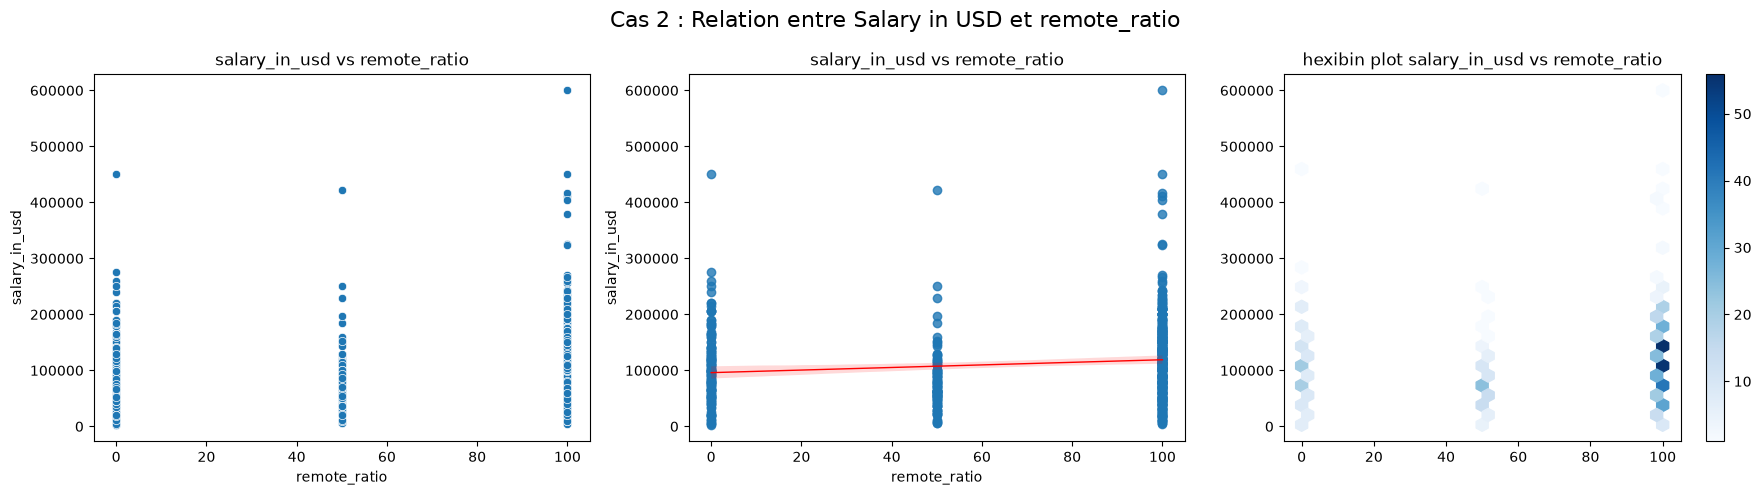

In [13]:
fig, axes = plt.subplots(1,3, figsize=(18,5))

sns.scatterplot(y='salary_in_usd',x='remote_ratio',data=data,ax=axes[0])
axes[0].set_title("salary_in_usd vs remote_ratio")

sns.regplot(x='remote_ratio', y='salary_in_usd', data=data, scatter_kws={"alpha":0.8}, line_kws={"color": "red", "linewidth": 1},ax=axes[1])
axes[1].set_title("salary_in_usd vs remote_ratio")

plt.hexbin(data['remote_ratio'], data['salary_in_usd'], gridsize=30 , cmap='Blues', mincnt=1)
plt.colorbar()
plt.title("hexibin plot salary_in_usd vs remote_ratio")

plt.suptitle("Cas 2 : Relation entre Salary in USD et remote_ratio", fontsize=16)

plt.tight_layout()
plt.show()

- Le nuage de points montre que les salaires varient fortement quel que soit le niveau de travail à distance. On ne remarque pas de relation claire entre le pourcentage de travail remote et le salaire.
- La ligne de régression indique une relation très faible entre le remote ratio et le salaire. Cela suggère que le niveau de travail à distance n’a pas d’impact significatif sur le salaire des employés dans ce dataset.
- Le hexbin plot met en évidence les zones où les observations sont les plus concentrées. La majorité des employés ont un salaire situé dans une plage moyenne, indépendamment du niveau de travail à distance.

> _*Décisions*_

Le travail à distance n’a pas d’influence claire sur le salaire selon les données analysées.

### Cas 2 : salary_in_usd vs work_year 

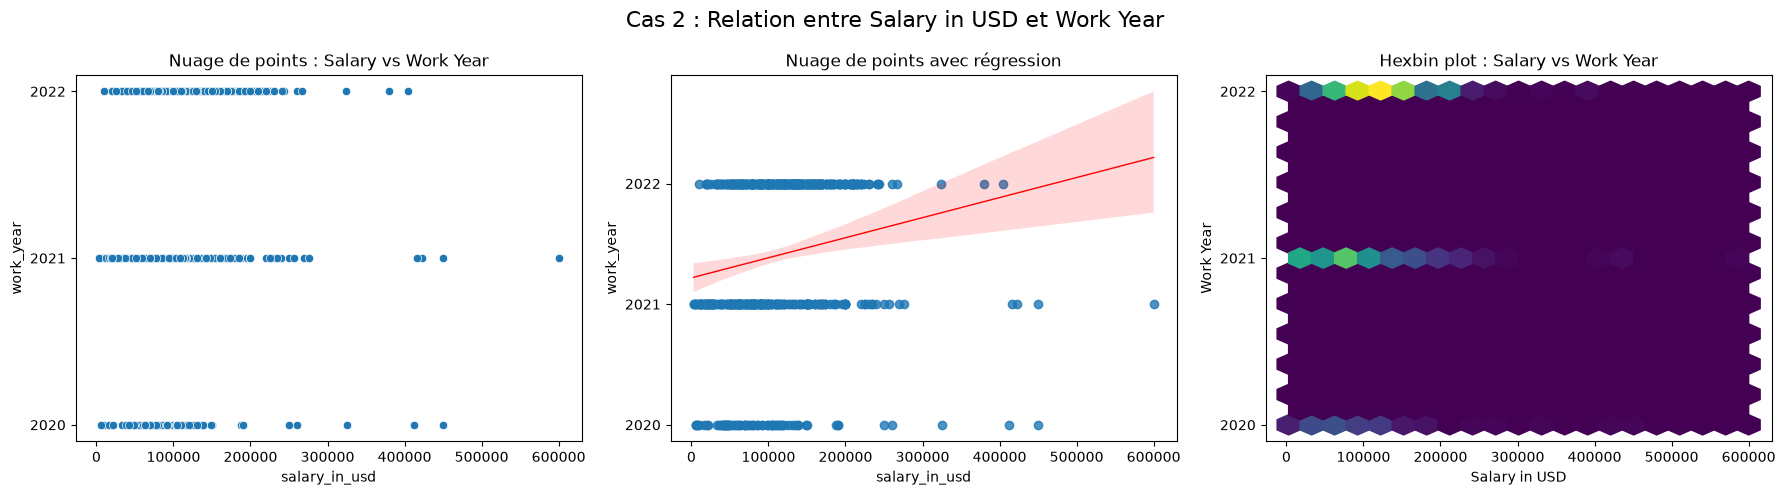

In [14]:
fig, axes = plt.subplots(1,3, figsize=(18,5))

sns.scatterplot(data=data, x="salary_in_usd", y="work_year", ax=axes[0])
axes[0].set_title("Nuage de points : Salary vs Work Year")
axes[0].set_yticks([2020, 2021, 2022])

sns.regplot(data=data, x="salary_in_usd", y="work_year",line_kws={"color": "red", "linewidth": 1}, ax=axes[1])
axes[1].set_title("Nuage de points avec régression")
axes[1].set_yticks([2020, 2021, 2022])

axes[2].hexbin(data["salary_in_usd"], data["work_year"], gridsize=20)
axes[2].set_title("Hexbin plot : Salary vs Work Year")
axes[2].set_xlabel("Salary in USD")
axes[2].set_ylabel("Work Year")
axes[2].set_yticks([2020, 2021, 2022])

plt.suptitle("Cas 2 : Relation entre Salary in USD et Work Year", fontsize=16)

plt.tight_layout()
plt.show()

- Le nuage de points montre que les salaires varient fortement d’une année à l’autre. On observe également une tendance à l’augmentation des salaires dans les années les plus récentes.
- La ligne de régression suggère une tendance à la hausse des salaires au fil des années, ce qui peut indiquer une augmentation de la demande pour les métiers liés à la data.
- Le hexbin plot met en évidence que la majorité des salaires se situe dans une plage moyenne, avec une tendance à des salaires plus élevés dans les années récentes.

> _*Décisions*_

L’analyse des graphiques montre une tendance générale à l’augmentation des salaires entre 2020 et 2022. Cette évolution peut s’expliquer par la croissance du marché de la data et la demande croissante pour les métiers liés à l’intelligence artificielle et à l’analyse de données.

## 3.2 Qualitative – Quantitative

### Cas 3 : experience_level vs salary_in_usd 

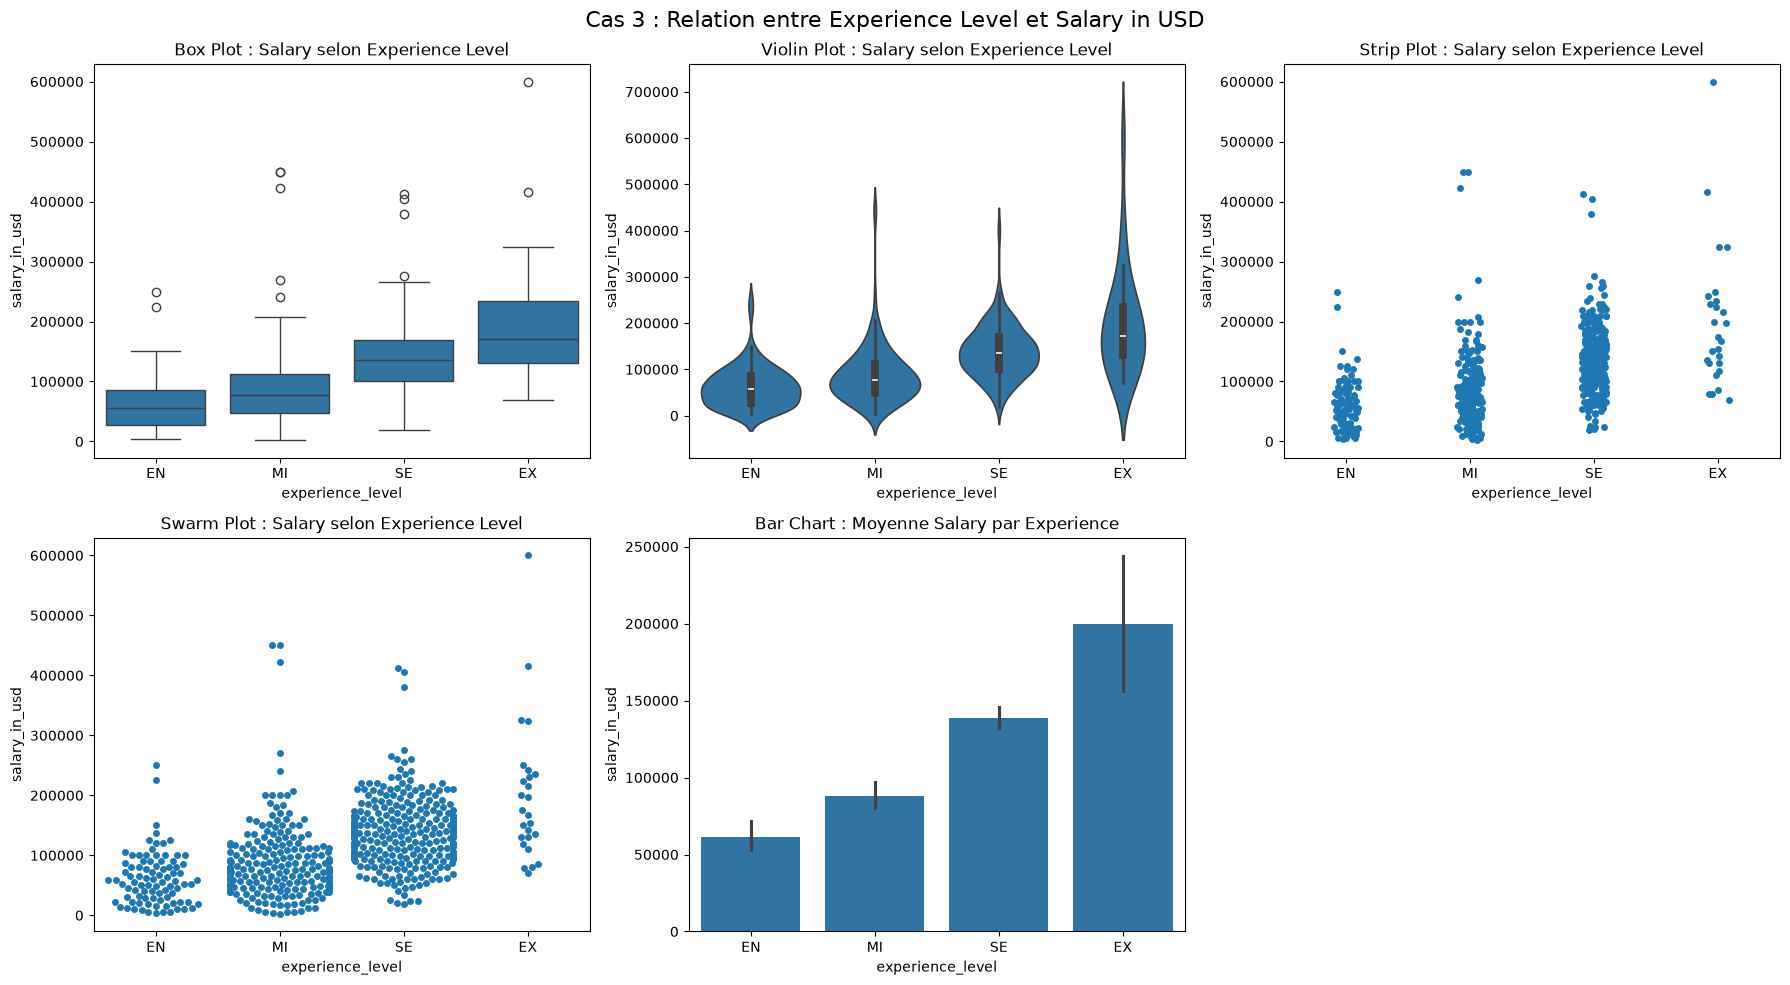

In [15]:
fig, axes = plt.subplots(2,3, figsize=(18,10))

order = ["EN","MI","SE","EX"]

sns.boxplot(data=data, x="experience_level", y="salary_in_usd",order=order, ax=axes[0,0])
axes[0,0].set_title("Box Plot : Salary selon Experience Level")

sns.violinplot(data=data, x="experience_level", y="salary_in_usd",order=order,  ax=axes[0,1])
axes[0,1].set_title("Violin Plot : Salary selon Experience Level")

sns.stripplot(data=data, x="experience_level", y="salary_in_usd",order=order,  ax=axes[0,2])
axes[0,2].set_title("Strip Plot : Salary selon Experience Level")

sns.swarmplot(data=data, x="experience_level", y="salary_in_usd",order=order,  ax=axes[1,0])
axes[1,0].set_title("Swarm Plot : Salary selon Experience Level")

sns.barplot(data=data, x="experience_level", y="salary_in_usd",order=order,  ax=axes[1,1])
axes[1,1].set_title("Bar Chart : Moyenne Salary par Experience")

axes[1,2].axis("off")

plt.suptitle("Cas 3 : Relation entre Experience Level et Salary in USD", fontsize=16)

plt.tight_layout()
plt.show()

- Le box plot montre que le salaire augmente généralement avec le niveau d’expérience. Les employés ayant plus d’expérience ont tendance à recevoir des salaires plus élevés.
- Le violin plot montre la distribution des salaires pour chaque niveau d’expérience. On observe que les niveaux d’expérience élevés présentent une plus grande dispersion et des salaires généralement plus élevés.
- Le strip plot permet d’observer les valeurs individuelles des salaires. On remarque que les salaires les plus élevés sont principalement associés aux niveaux d’expérience supérieurs.
- Le swarm plot confirme que les salaires augmentent avec l’expérience et montre clairement la répartition des observations dans chaque catégorie.
- Le bar chart montre que la moyenne des salaires augmente avec le niveau d’expérience, ce qui indique une relation positive entre expérience et rémunération.


> _*Décisions*_

Le salaire augmente généralement avec le niveau d’expérience.

### Cas 4 : company_size vs salary_in_usd

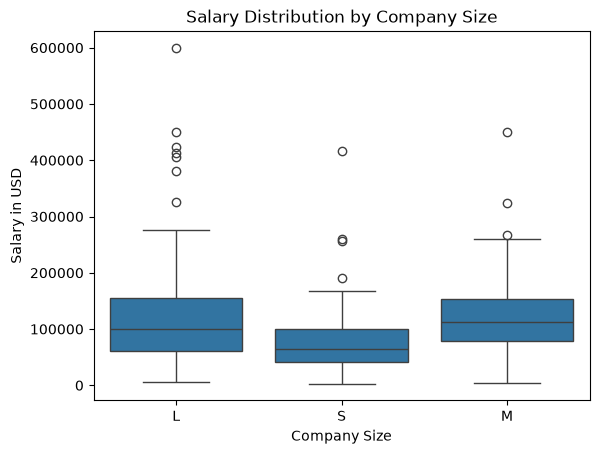

In [16]:
sns.boxplot(x="company_size", y="salary_in_usd", data=data)

plt.title("Salary Distribution by Company Size")
plt.xlabel("Company Size")
plt.ylabel("Salary in USD")

plt.show()

Le boxplot montre que les grandes entreprises (L) offrent les salaires les plus élevés, avec une médiane supérieure et une forte dispersion jusqu'à 600 000 USD. Les entreprises de taille moyenne (M) et petite (S) ont des salaires plus faibles et plus concentrés. Plus l'entreprise est grande, plus les salaires sont compétitifs

Text(0, 0.5, 'Salary in USD')

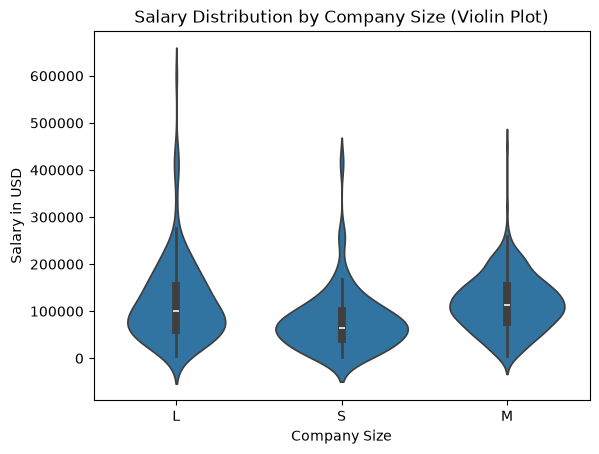

In [17]:
sns.violinplot(x="company_size", y="salary_in_usd", data=data)

plt.title("Salary Distribution by Company Size (Violin Plot)")
plt.xlabel("Company Size")
plt.ylabel("Salary in USD")


Le violon plot confirme que les grandes entreprises (L) présentent une densité de salaires plus étalée vers les valeurs élevées, avec une queue supérieure atteignant 600 000 USD. Les entreprises moyennes (M) et petites (S) ont une forme plus ramassée, indiquant des salaires plus faibles et moins dispersés. La distribution montre que la taille de l’entreprise influence positivement le niveau et la variabilité des salaires.

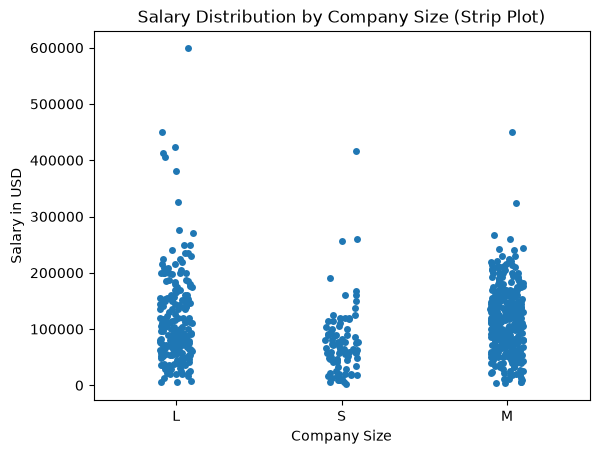

In [18]:
sns.stripplot(x="company_size", y="salary_in_usd", data=data)

plt.title("Salary Distribution by Company Size (Strip Plot)")
plt.xlabel("Company Size")
plt.ylabel("Salary in USD")

plt.show()

Le strip plot montre une dispersion des salaires plus importante dans les grandes entreprises (L), avec une concentration de points jusqu’à 600 000 USD. Les petites (S) et moyennes (M) entreprises présentent des salaires plus bas et plus resserrés. La répartition des points confirme que les grandes entreprises offrent une plus grande diversité de rémunérations, incluant les salaires les plus élevés.

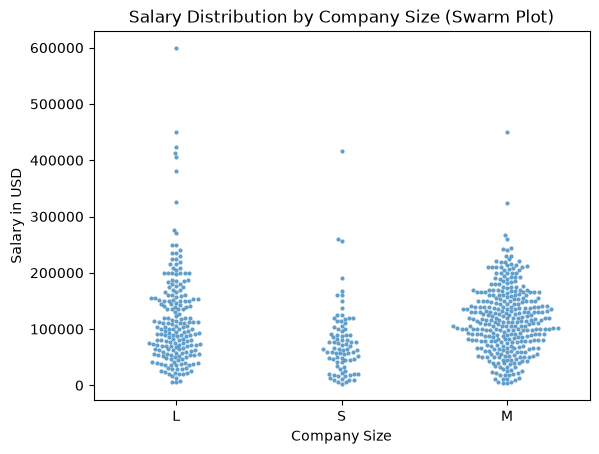

In [19]:
sns.swarmplot(
    x="company_size",
    y="salary_in_usd",
    data=data,
    size=3,
    alpha=0.7
)

plt.title("Salary Distribution by Company Size (Swarm Plot)")
plt.xlabel("Company Size")
plt.ylabel("Salary in USD")

plt.show()

Le swarm plot montre que les grandes entreprises (L) concentrent les salaires les plus élevés, avec une dispersion atteignant 600 000 USD. Les entreprises moyennes (M) et petites (S) affichent des salaires plus bas et une dispersion plus faible. Cela confirme que la taille de l'entreprise influence positivement le niveau et la variabilité des rémunérations.

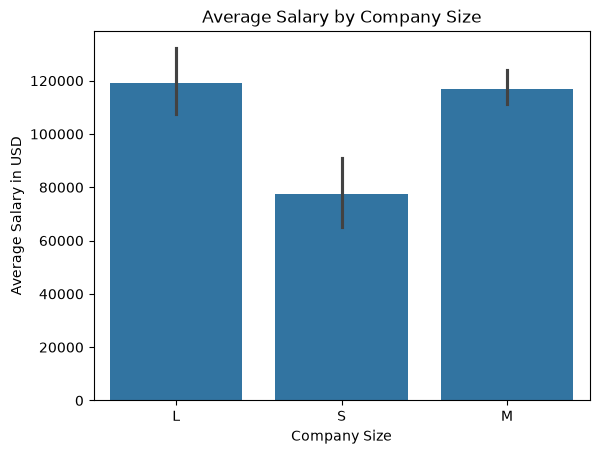

In [20]:
sns.barplot(x="company_size", y="salary_in_usd", data=data)

plt.title("Average Salary by Company Size")
plt.xlabel("Company Size")
plt.ylabel("Average Salary in USD")

plt.show()

Le bar chart montre que les grandes entreprises (L) ont le salaire moyen le plus élevé (120 000 USD), très proche des entreprises moyennes (M) avec 118 000 USD. Les petites entreprises (S) sont loin derrière avec seulement 78 000 USD. Cela confirme que la taille de l’entreprise impacte positivement le salaire moyen, avec un net désavantage pour les petites structures.

> _*Décisions*_

D’après l’analyse des diagrammes, il est conseillé aux professionnels et aux recruteurs de prioriser les grandes entreprises pour des postes nécessitant de l’expérience et une expertise élevée, car elles offrent des salaires plus attractifs et compétitifs. Les entreprises moyennes peuvent être ciblées pour des profils intermédiaires, assurant un bon équilibre entre rémunération et stabilité. Les petites entreprises, quant à elles, restent adaptées pour recruter des profils juniors ou motivés par des opportunités autres que le salaire, comme la polyvalence ou l’apprentissage rapide. Cette approche permet d’optimiser l’attraction et la rétention des talents en fonction des moyens et des besoins réels de chaque segment d’entreprise.

### Cas 5 : employment_type vs salary_in_usd 

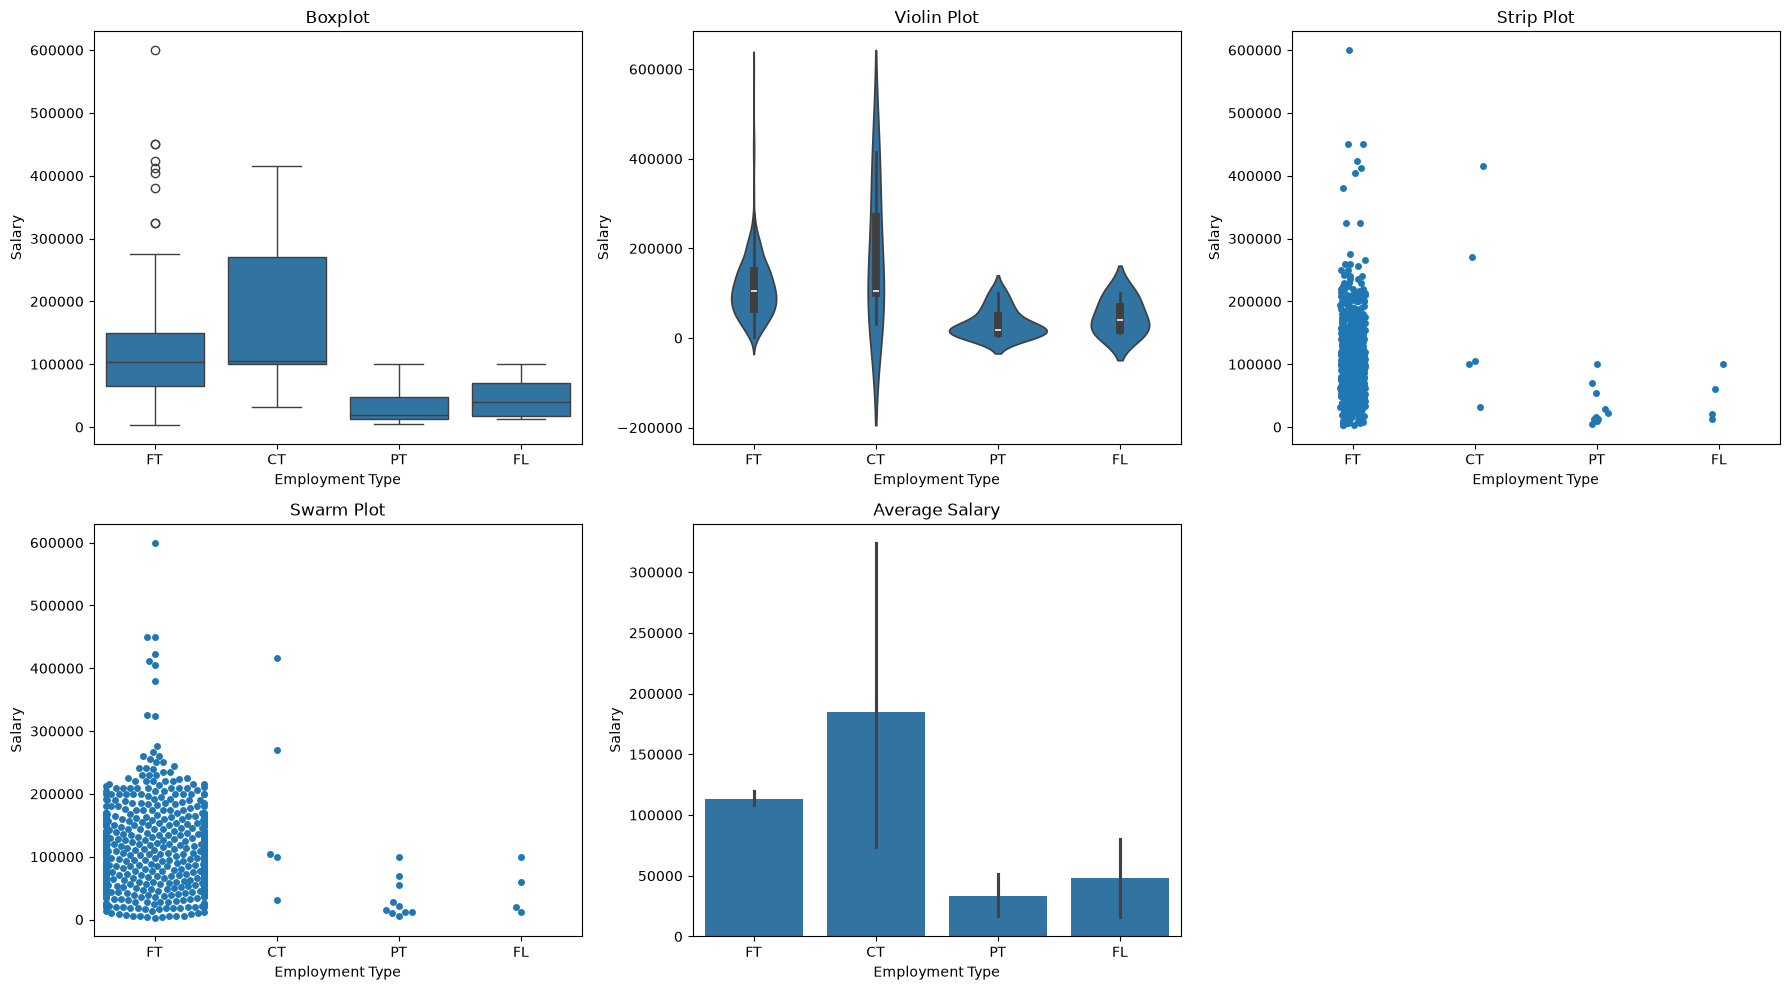

In [21]:
plt.figure(figsize=(18,10))

plt.subplot(2,3,1)
sns.boxplot(x="employment_type", y="salary_in_usd", data=data)
plt.title("Boxplot")
plt.xlabel("Employment Type")
plt.ylabel("Salary")

plt.subplot(2,3,2)
sns.violinplot(x="employment_type", y="salary_in_usd", data=data)
plt.title("Violin Plot")
plt.xlabel("Employment Type")
plt.ylabel("Salary")

plt.subplot(2,3,3)
sns.stripplot(x="employment_type", y="salary_in_usd", data=data)
plt.title("Strip Plot")
plt.xlabel("Employment Type")
plt.ylabel("Salary")

plt.subplot(2,3,4)
sns.swarmplot(x="employment_type", y="salary_in_usd", data=data)
plt.title("Swarm Plot")
plt.xlabel("Employment Type")
plt.ylabel("Salary")

plt.subplot(2,3,5)
sns.barplot(x="employment_type", y="salary_in_usd", data=data)
plt.title("Average Salary")
plt.xlabel("Employment Type")
plt.ylabel("Salary")

plt.tight_layout()
plt.show()

Le box plot montre la distribution des salaires pour chaque type de contrat. On observe que les employés à temps plein (FT) ont généralement des salaires plus élevés et une dispersion plus large. Cela signifie que les salaires varient beaucoup dans cette catégorie. Les contrats part-time (PT) et contract (CT) ont des salaires plus faibles et une distribution plus concentrée.

Le violin plot permet d’observer la forme de la distribution des salaires. On remarque que la distribution est plus large pour les emplois à temps plein, ce qui indique une plus grande diversité de niveaux de salaire. Les autres types de contrats présentent une distribution plus étroite, ce qui signifie que leurs salaires sont généralement plus homogènes et plus faibles.

Le strip plot montre chaque observation individuelle de salaire. On constate que la majorité des salaires élevés correspond aux contrats à temps plein, tandis que les contrats part-time et contract ont moins d’observations avec des salaires élevés.

Le swarm plot permet de visualiser la répartition des salaires sans chevauchement des points. On observe que les points représentant les emplois à temps plein sont plus nombreux et souvent situés à des niveaux de salaire plus élevés.

Le bar chart montre la moyenne des salaires pour chaque type de contrat. Il indique que les employés à temps plein ont la moyenne de salaire la plus élevée, tandis que les autres types de contrats ont des salaires moyens plus faibles.

L’analyse des différents diagrammes montre que le type de contrat influence le niveau de salaire. Les emplois à temps plein offrent généralement les salaires les plus élevés et la plus grande diversité de rémunération, tandis que les contrats part-time ou contract ont des salaires plus faibles et plus stables.

> _*Décisions*_

- Favoriser les contrats à temps plein pour attirer et retenir les talents qualifiés.
- Utiliser les contrats contract ou freelance pour des missions temporaires ou spécifiques.
- Analyser les écarts de salaire afin de garantir une rémunération équitable.
- Adapter la stratégie de recrutement selon les besoins et le budget de l’entreprise.

## 3.3 Qualitative – Qualitative

### Cas 6 : experience_level vs company_size 

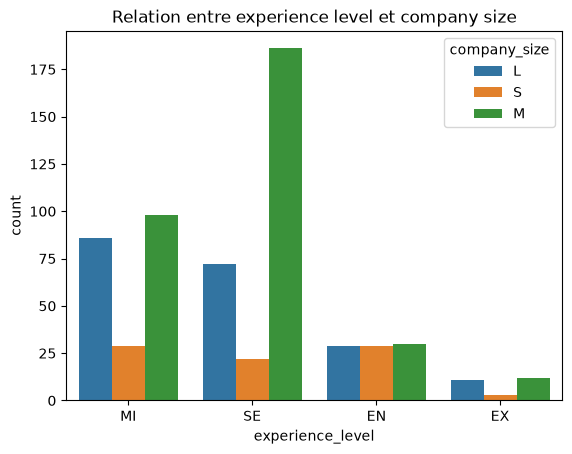

In [22]:
sns.countplot(data=data, x="experience_level", hue="company_size")
plt.title("Relation entre experience level et company size")
plt.show()

Le count plot croisé montre le nombre d’employés pour chaque niveau d’expérience dans les différentes tailles d’entreprises.
On observe généralement que les entreprises moyennes (M) et grandes (L) recrutent davantage d’employés Senior (SE) et Mid-level (MI).
Les Entry-level (EN) sont moins nombreux, surtout dans les grandes entreprises.

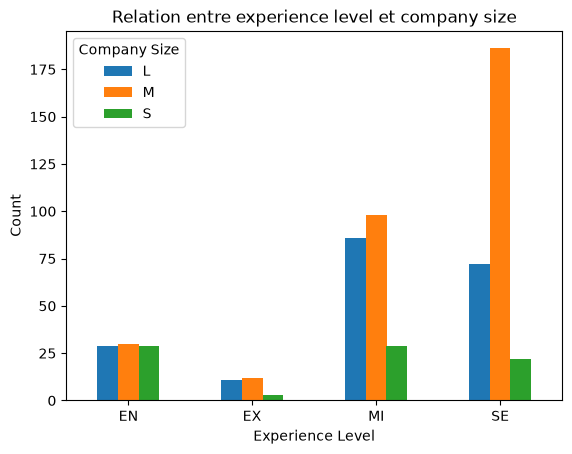

In [23]:
table = pd.crosstab(data['experience_level'], data['company_size'])

table.plot(kind='bar')

plt.title('Relation entre experience level et company size')
plt.xlabel('Experience Level')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.legend(title='Company Size')
plt.show()

Le diagramme en barres groupées permet de comparer directement les niveaux d’expérience dans chaque taille d’entreprise.
On remarque que certaines tailles d’entreprises ont une concentration plus élevée de certains niveaux d’expérience, notamment les Senior dans les grandes entreprises.

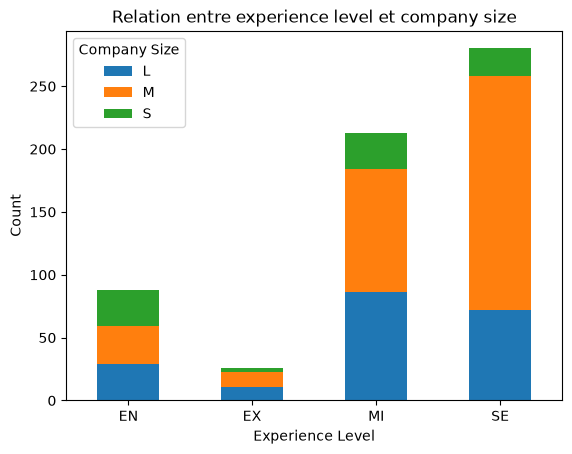

In [24]:
table.plot(
    kind='bar',
    stacked=True
)

plt.title('Relation entre experience level et company size')
plt.xlabel('Experience Level')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.legend(title='Company Size')
plt.show()

Le diagramme empilé montre la proportion des différents niveaux d’expérience dans chaque taille d’entreprise.
On observe que les grandes entreprises ont une proportion importante de profils Senior et Executive, tandis que les entreprises plus petites peuvent avoir une proportion plus variée.

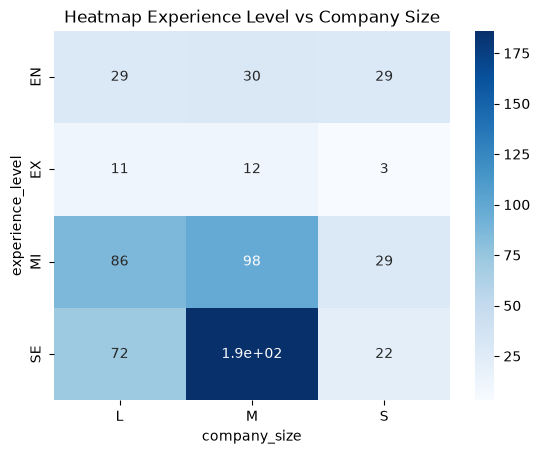

In [25]:
sns.heatmap(table, annot=True, cmap="Blues")
plt.title("Heatmap Experience Level vs Company Size")
plt.show()

La heatmap met en évidence les combinaisons les plus fréquentes grâce aux couleurs.
Les cellules les plus foncées indiquent les combinaisons où il y a le plus d’employés, par exemple Senior dans les entreprises moyennes ou grandes.

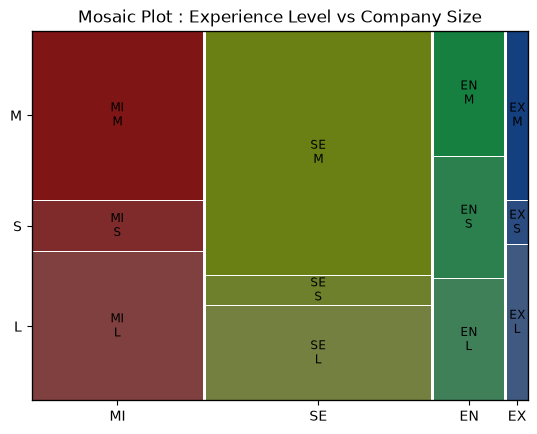

In [26]:
from statsmodels.graphics.mosaicplot import mosaic

mosaic(data, ['experience_level', 'company_size'])

plt.title("Mosaic Plot : Experience Level vs Company Size")
plt.show()

Le mosaic plot montre la relation entre les deux variables en représentant la proportion de chaque combinaison par la surface des rectangles.
Les rectangles les plus grands correspondent aux combinaisons les plus fréquentes, ce qui confirme que les profils expérimentés sont plus présents dans les entreprises moyennes et grandes.


> _*Décisions*_

- Les entreprises, surtout les grandes, privilégient les profils expérimentés.
Cela signifie que les jeunes diplômés doivent d’abord acquérir de l’expérience avant d’accéder aux grandes entreprises.
- Les stratégies de recrutement diffèrent selon la taille de l’entreprise.
Les grandes entreprises devraient continuer à attirer des profils expérimentés, tandis que les petites entreprises pourraient investir davantage dans la formation des débutants.
- Les grandes entreprises semblent fonctionner avec une main-d'œuvre plus qualifiée, ce qui peut améliorer la performance et la gestion des projets complexes.
- Les entreprises devraient adapter leurs stratégies de recrutement selon leurs besoins en expérience, car certains niveaux d’expérience sont clairement plus demandés dans certaines tailles d’entreprises.
- Le marché du travail dans le domaine de la data favorise les profils expérimentés dans les grandes structures, ce qui signifie que les jeunes professionnels doivent développer leurs compétences et accumuler de l’expérience pour accéder à ces entreprises.

### Cas 7 : employment_type vs experience_level 

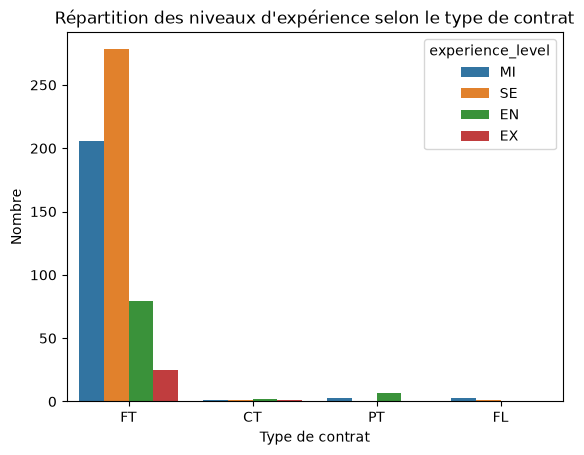

In [27]:
sns.countplot(
    data=data,
    x="employment_type",
    hue="experience_level"
)

plt.title("Répartition des niveaux d'expérience selon le type de contrat")
plt.xlabel("Type de contrat")
plt.ylabel("Nombre")
plt.show()

Le graphique en **count plot croisé** montre la distribution des niveaux d'expérience selon le type de contrat.  
On observe que les contrats **Full-Time (FT)** représentent la majorité des emplois dans le dataset.  
Les profils **Mid-Level (MI)** et **Senior (SE)** sont les plus fréquents dans ces contrats, tandis que les profils **Entry-Level (EN)** apparaissent moins souvent.

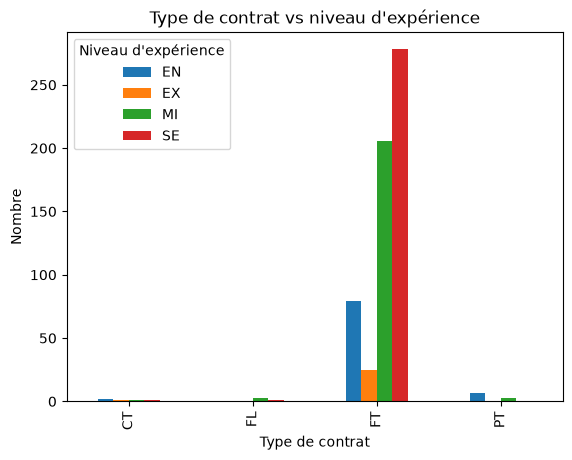

In [28]:
table = pd.crosstab(data['employment_type'], data['experience_level'])

table.plot(kind='bar')

plt.title("Type de contrat vs niveau d'expérience")
plt.xlabel("Type de contrat")
plt.ylabel("Nombre")
plt.legend(title="Niveau d'expérience")
plt.show()

Le diagramme en **barres groupées** permet de comparer les niveaux d'expérience pour chaque type de contrat.  
On remarque que les contrats **Full-Time** contiennent la plus grande proportion de professionnels, notamment des profils **Mid-Level et Senior**.  
Les autres types de contrats comme **Part-Time ou Contract** sont moins représentés dans le dataset.

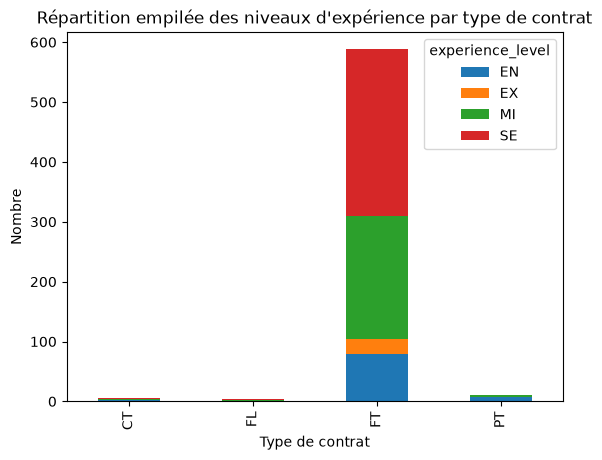

In [29]:
table.plot(
    kind='bar',
    stacked=True
)

plt.title("Répartition empilée des niveaux d'expérience par type de contrat")
plt.xlabel("Type de contrat")
plt.ylabel("Nombre")
plt.show()

Le diagramme en **barres empilées** permet d'observer la proportion des différents niveaux d'expérience au sein de chaque type de contrat.  
Les contrats **Full-Time** présentent une diversité de niveaux d'expérience, mais les profils **Mid-Level et Senior** restent dominants.  
Les contrats temporaires ou partiels montrent une proportion plus faible d'employés.

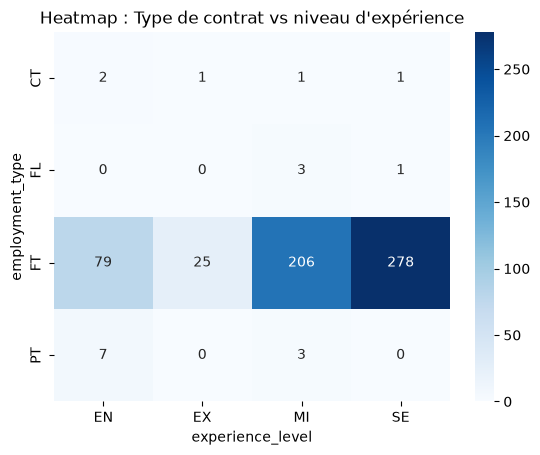

In [30]:
table = pd.crosstab(data['employment_type'], data['experience_level'])

sns.heatmap(
    table,
    annot=True,
    cmap="Blues",
    fmt="d"
)

plt.title("Heatmap : Type de contrat vs niveau d'expérience")
plt.show()

La **heatmap du tableau de contingence** met en évidence les combinaisons les plus fréquentes entre type de contrat et niveau d'expérience.  
Les couleurs plus foncées indiquent un nombre plus élevé d'observations.  
On constate que certaines combinaisons comme **Full-Time avec Mid-Level ou Senior** sont particulièrement fréquentes.

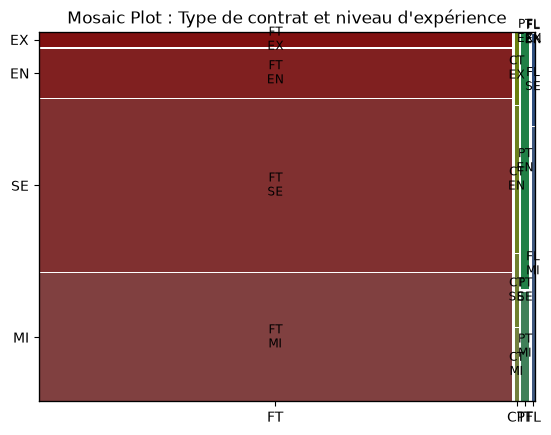

In [31]:
from statsmodels.graphics.mosaicplot import mosaic

mosaic(data, ['employment_type','experience_level'])

plt.title("Mosaic Plot : Type de contrat et niveau d'expérience")
plt.show()

Le **Mosaic Plot** représente visuellement la proportion de chaque combinaison entre type de contrat et niveau d'expérience.  
La taille des rectangles indique la fréquence relative de chaque catégorie.  
Les rectangles les plus grands correspondent aux combinaisons les plus présentes dans le dataset.

> _*Décisions*_

- L'analyse des différents graphiques montre que les **contrats Full-Time (FT)** dominent largement dans le dataset.  
Les profils **Mid-Level (MI)** et **Senior (SE)** sont les plus représentés, ce qui indique que les entreprises privilégient des candidats ayant déjà une expérience professionnelle solide.
- Ces résultats suggèrent que le marché du travail dans le domaine de la **Data Science** est orienté vers des **profils qualifiés et expérimentés**, en particulier pour les postes à temps plein.
- Ainsi, pour améliorer l'accès aux opportunités professionnelles, il est important pour les profils débutants de **développer leurs compétences techniques et leur expérience pratique** afin d'atteindre les niveaux intermédiaires ou avancés.

# 4. Analyse multivariée

## 4.1 Visualiser les relations entre plusieurs variables

### 4.1.1 Scatter plot

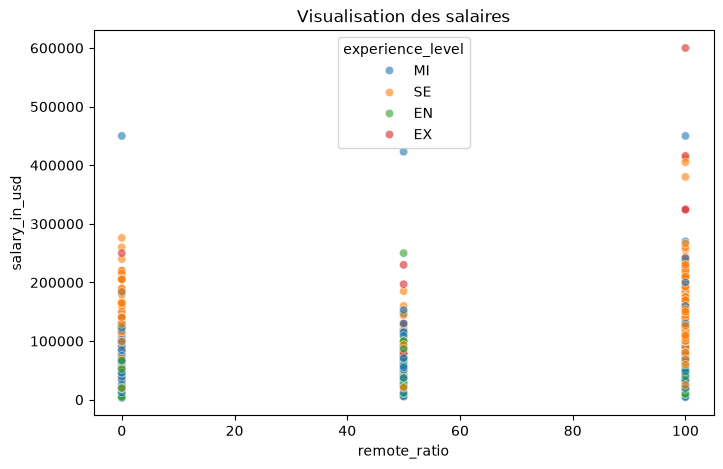

In [32]:
# v0 : Scatter simple
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=data,
    x="remote_ratio",
    y="salary_in_usd",
    hue="experience_level",
    alpha=0.6
)

plt.title("Visualisation des salaires")
plt.show()

**Interprétation :**

- Le graphique montre la relation entre le niveau de travail à distance (0 %, 50 %, 100 %) et le salaire en USD.
- Les salaires les plus élevés sont majoritairement observés dans les postes 100 % remote.
- Les postes hybrides (50 %) présentent des salaires plus concentrés et généralement intermédiaires.
- Les emplois en présentiel (0 %) montrent une grande dispersion des salaires, mais moins de valeurs très élevées.
- Les niveaux d’expérience élevés (Senior et Executive) sont associés aux salaires les plus importants, tandis que les niveaux débutants ont des salaires plus faibles.

**Conclusion :**

Le travail à distance complet et l’expérience professionnelle élevée sont des facteurs liés à des salaires plus élevés.

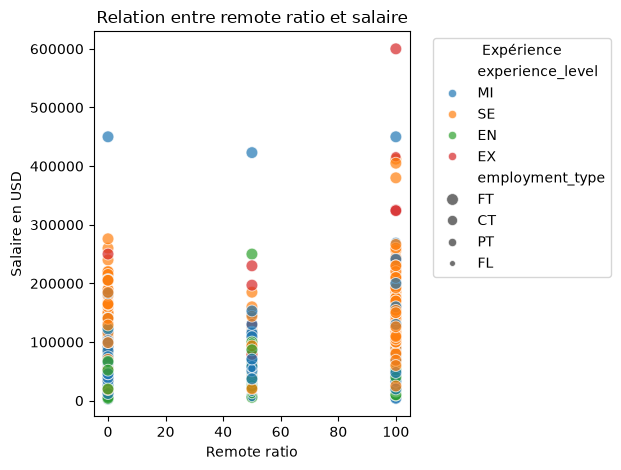

In [33]:
#version 1
sns.scatterplot(
    data=data,
    x="remote_ratio",
    y="salary_in_usd",
    hue="experience_level",
    size="employment_type",
    
    alpha=0.7
)

plt.title("Relation entre remote ratio et salaire", fontsize=12)
plt.xlabel("Remote ratio")
plt.ylabel("Salaire en USD")

plt.legend(title="Expérience", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

**Interprétation** :

-Le graphique montre la relation entre le remote ratio (0 %, 50 %, 100 %) et le salaire en USD.

-Les salaires les plus élevés sont observés principalement pour les postes 100 % remote, avec des valeurs pouvant dépasser 400 000 USD et même 600 000 USD.

-Les postes hybrides (50 %) présentent des salaires plus modérés et concentrés.

-Les postes en présentiel (0 %) ont des salaires variés, mais moins de valeurs très élevées.

-Les emplois à temps plein (FT) dominent parmi les salaires élevés.

-Les niveaux d’expérience élevés (Senior et Executive) sont associés aux plus hauts salaires.

**Conclusion :**

Le travail à distance total et l’expérience élevée sont des facteurs importants pour obtenir des salaires élevés

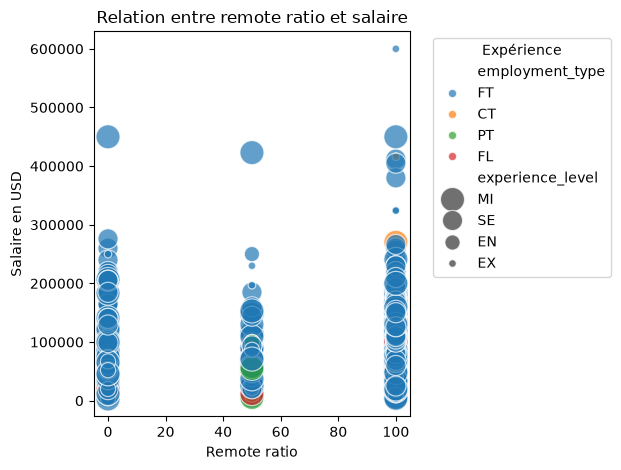

In [34]:
# version2 : plus lisible
sns.scatterplot(
    data=data,
    x="remote_ratio",
    y="salary_in_usd",
    size="experience_level",
    sizes=(30, 300),
    hue="employment_type",
    alpha=0.7
)

plt.title("Relation entre remote ratio et salaire", fontsize=12)
plt.xlabel("Remote ratio")
plt.ylabel("Salaire en USD")

plt.legend(title="Expérience", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

**Interprétation:**

-Le graphique montre la relation entre le niveau de travail à distance (remote ratio) et le salaire en USD.

-Les salaires les plus élevés apparaissent surtout dans les postes 100 % remote.

-Les postes hybrides (50 %) présentent des salaires plus concentrés et généralement intermédiaires.

-La majorité des points correspond à des emplois à temps plein (FT).

-Les niveaux d’expérience élevés (Senior et Executive) sont associés aux salaires les plus importants.

**Conclusion**

Globalement, les postes totalement à distance semblent offrir plus d’opportunités de salaires élevés, surtout pour les profils expérimentés et en emploi à temps plein.

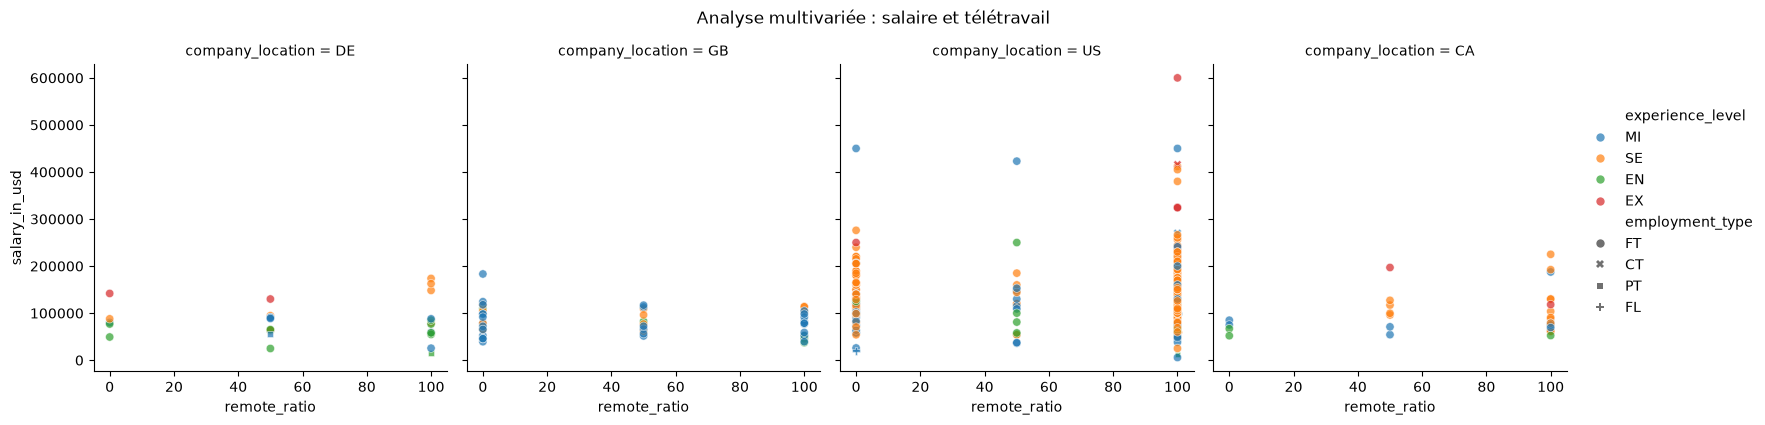

In [35]:
# Facettes par pays :
#----------------------

# On affiche les pays principaux pour avoir un résultat lisible
top_locations = data["company_location"].value_counts().head(4).index
data_filtered = data[data["company_location"].isin(top_locations)]
graph = sns.relplot(
    data=data_filtered,
    x="remote_ratio",
    y="salary_in_usd",
    hue="experience_level",
    style="employment_type",
    col="company_location",
    alpha=0.7,
    height=4
)

graph.fig.suptitle("Analyse multivariée : salaire et télétravail", y=1.05)

plt.show()

**Interprétation :**

-Le graphique montre la relation entre le salaire, le remote ratio et la localisation de l’entreprise (DE, GB, US, CA).

-Les salaires les plus élevés sont principalement observés aux États-Unis, surtout pour les postes 100 % remote.

-Les pays comme l’Allemagne (DE), le Royaume-Uni (GB) et le Canada (CA) présentent des salaires plus modérés et moins dispersés.

-Le travail totalement à distance (100 %) est souvent associé à des salaires plus élevés dans presque tous les pays.

-Les niveaux d’expérience élevés (Senior et Executive) correspondent aux salaires les plus importants.

-La majorité des postes bien rémunérés sont des emplois à temps plein (FT).

**Conclusion :**

Le salaire dépend fortement de la localisation de l’entreprise, mais aussi du niveau d’expérience et du travail à distance, avec un avantage clair pour les États-Unis et les postes remote.

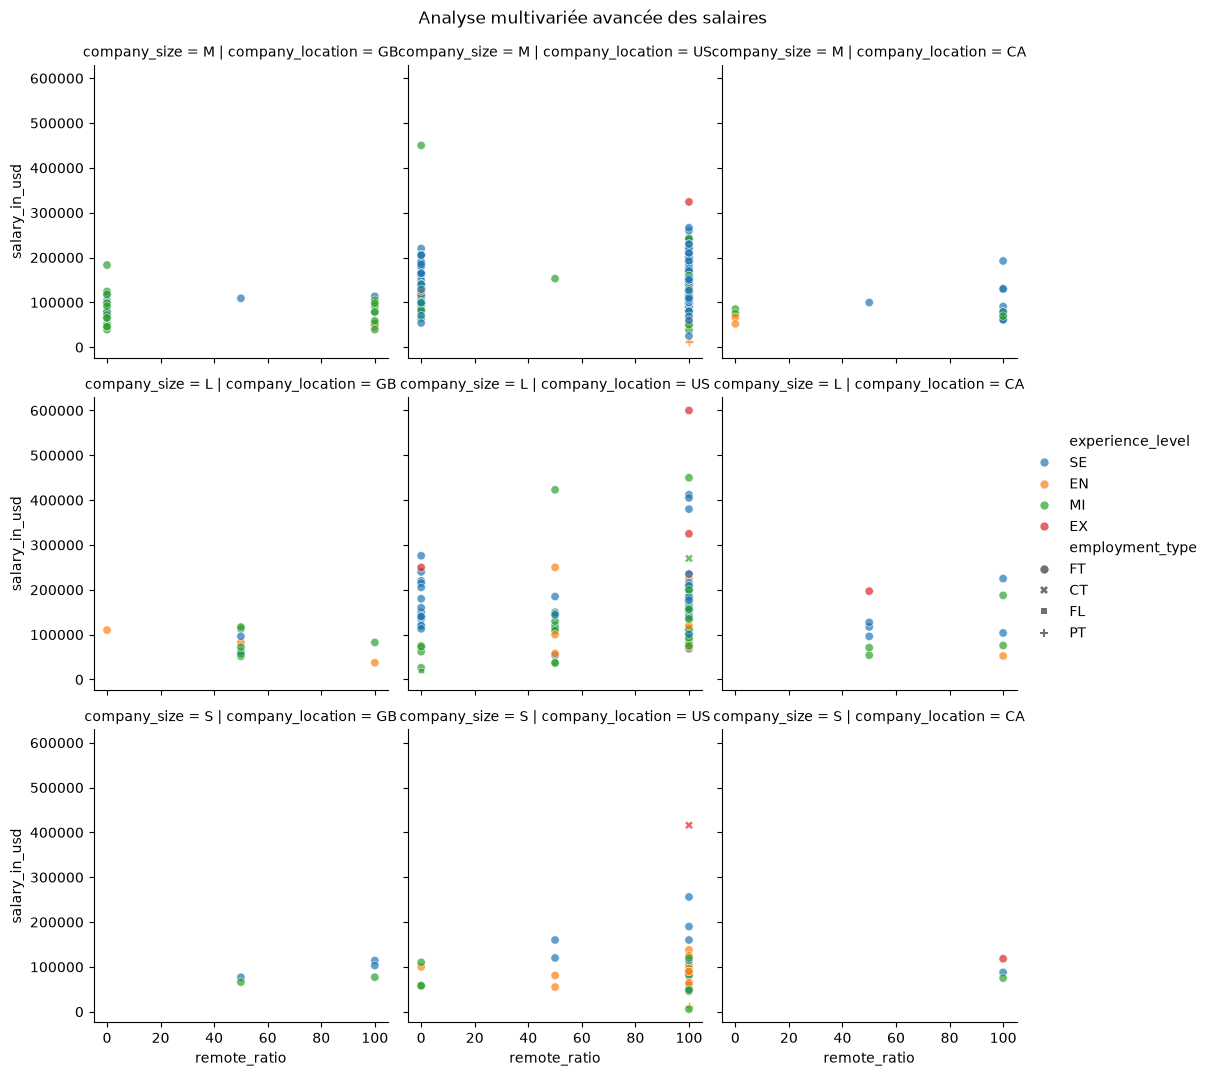

In [36]:
# Avec 6 variables :
#-------------------
# On affiche les pays principaux pour avoir un résultat lisible

top_locations = data["company_location"].value_counts().head(3).index
data_filtered = data[data["company_location"].isin(top_locations)]

graph = sns.relplot(
    data=data_filtered,
    x="remote_ratio",
    y="salary_in_usd",
    hue="experience_level",
    style="employment_type",
    col="company_location",
    row="company_size",
    alpha=0.7,
    height=3.5
)

graph.fig.suptitle("Analyse multivariée avancée des salaires", y=1.02)

plt.show()

**Interprétation:**

-Les salaires les plus élevés sont observés principalement aux États-Unis, surtout dans les entreprises moyennes (M) et grandes (L).

-Les postes 100 % remote présentent plusieurs salaires élevés, ce qui montre que le travail à distance peut offrir de meilleures opportunités salariales.

-Les niveaux d’expérience élevés (Senior et Executive) sont associés aux salaires les plus importants, tandis que les niveaux Entry et Mid ont des salaires plus faibles.

-La majorité des salaires élevés concerne des emplois à temps plein (FT).

-Les petites entreprises (S) et certaines localisations comme GB et CA montrent généralement des salaires plus modérés.

### 4.1.2 Pairplot

In [37]:
data_copie=data.copy()

In [38]:
data_copie=data_copie.drop('Unnamed: 0',axis=1)

In [39]:
data_copie=data_copie.drop('salary',axis=1)

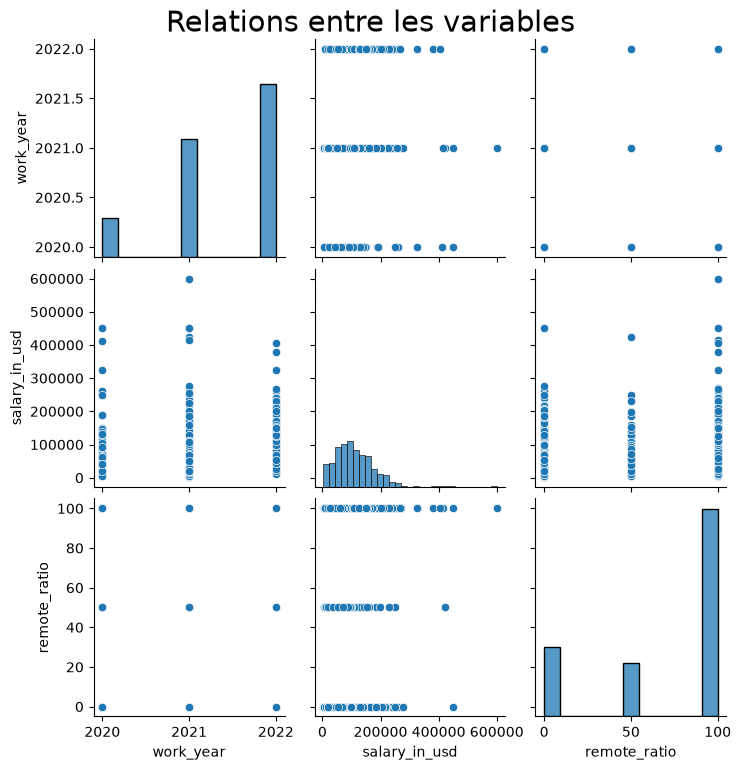

In [40]:
f = sns.pairplot(data_copie)

f.fig.suptitle("Relations entre les variables", y=1.02, fontsize=21)

plt.show()


**Interprétation :**

- Le graphique montre les relations entre l’année (work_year), le salaire en USD et le niveau de travail à distance (remote ratio).
- On observe une augmentation globale des salaires entre 2020 et 2022, avec plus de valeurs élevées en 2022.
- Les salaires sont très dispersés, allant de faibles valeurs à plus de 600 000 USD, ce qui indique une forte variabilité.
- Le remote ratio 100 % est le plus fréquent, ce qui montre que le travail à distance est devenu dominant.
- Les salaires élevés apparaissent dans tous les niveaux de remote, mais sont plus visibles avec le 100 % remote.

**Conclusion :**

Les salaires ont tendance à augmenter avec le temps, et le travail à distance est devenu majoritaire, avec une influence possible sur les salaires élevés.

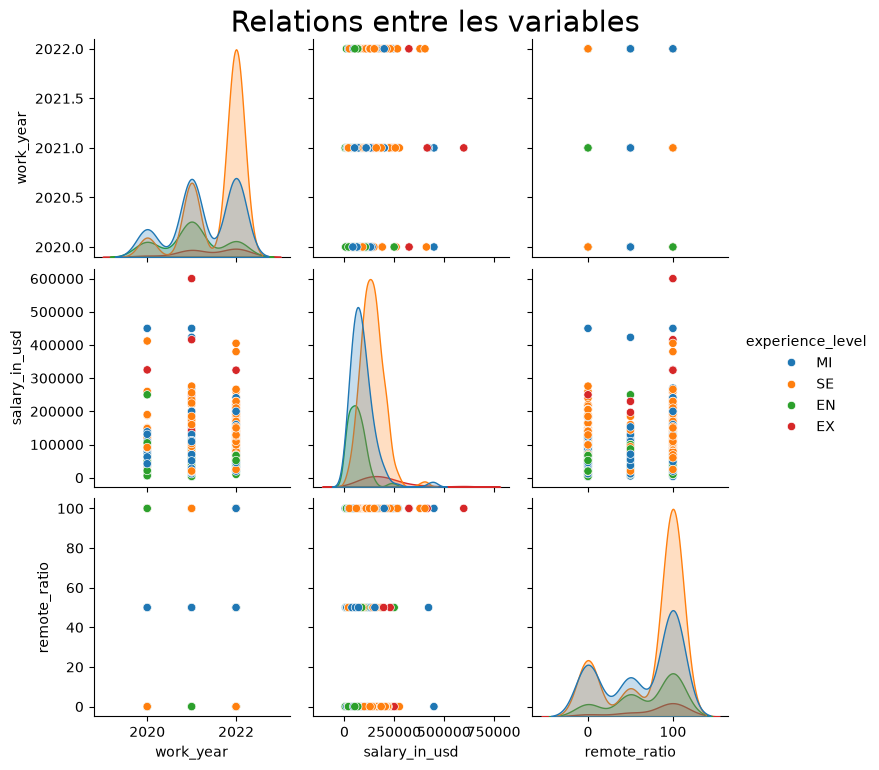

In [41]:
f = sns.pairplot(data_copie, hue="experience_level")

f.fig.suptitle("Relations entre les variables", y=1.02, fontsize=21)

plt.show()

**Interprétation :**

-Ce graphique montre les relations entre le salaire (salary_in_usd), l’année (work_year) et le niveau de travail à distance (remote_ratio) selon le niveau d’expérience.

-On observe que les salaires augmentent avec le niveau d’expérience : les profils Executive (EX) et Senior (SE) ont les salaires les plus élevés.

-Les salaires sont très dispersés, mais les valeurs les plus élevées apparaissent surtout après 2021 et 2022.

-Le remote ratio (0 %, 50 %, 100 %) n’a pas une relation très forte directe avec le salaire, mais les postes 100 % remote montrent plusieurs salaires élevés.

-Les niveaux Entry (EN) ont des salaires plus faibles et moins dispersés.

**Conclusion :**

Le niveau d’expérience est le facteur le plus déterminant du salaire, tandis que l’année et le travail à distance ont un effet secondaire mais visible.

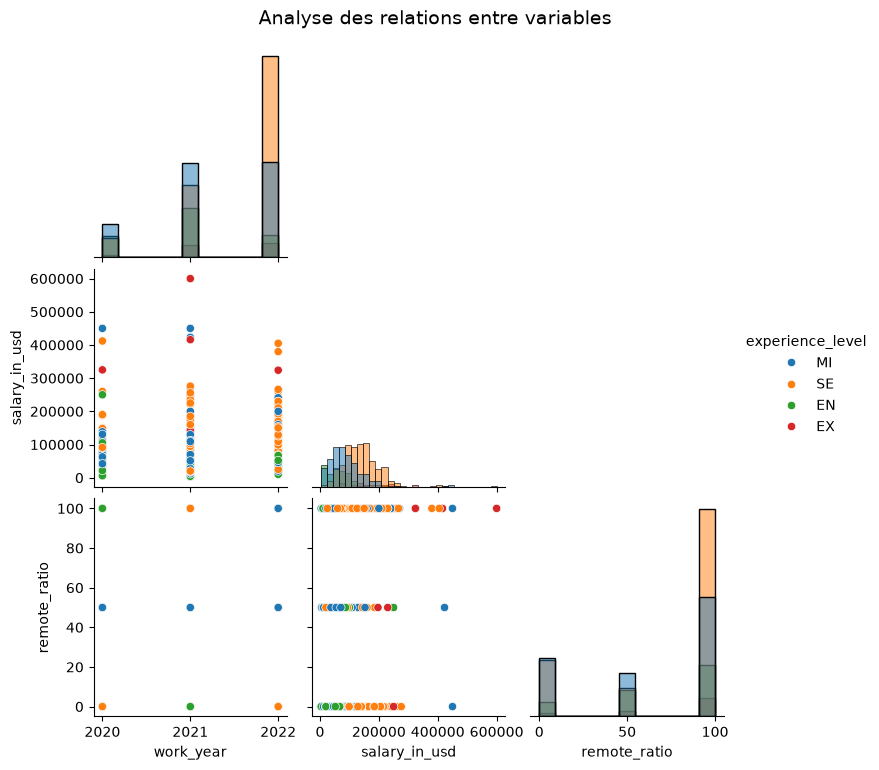

In [42]:
f = sns.pairplot(
    data_copie,
    hue="experience_level",
    diag_kind="hist",
    corner=True
)

f.fig.suptitle("Analyse des relations entre variables", y=1.02, fontsize=14)

plt.show()

- L’axe vertical (remote_ratio) prend principalement trois valeurs : 0 (présentiel), 50 (hybride) et 100 (full remote), ce qui explique les lignes horizontales de points.
- Sur la ligne 100 % remote, on observe plusieurs points avec des salaires très élevés, ce qui indique que les postes les mieux payés sont souvent entièrement à distance.
- La ligne 50 % (hybride) montre des salaires moins dispersés, concentrés dans une tranche moyenne.
- La ligne 0 % (présentiel) contient majoritairement des salaires plus faibles à intermédiaires, avec peu de valeurs extrêmes.
- es couleurs indiquent que les points avec salaires élevés correspondent surtout aux niveaux Senior et Executive, alors que les niveaux Junior/Mid sont plus bas.

**Conclusion :**

Les salaires les plus élevés se trouvent principalement dans les postes 100 % remote et occupés par des profils expérimentés, tandis que les postes hybrides ou en présentiel sont associés à des salaires plus modérés.

### 4.1.3 Décisions

Après cet analyse, on propose des décisions basées sur les facteurs qui influencent le plus le salaire: le remote, l’expérience, la taille de l’entreprise et la localisation.    

- Prioriser les postes remote pour accéder à des salaires plus élevés.
- Cibler les entreprises de grande taille, plus compétitives salarialement.
- Valoriser l’expérience professionnelle pour atteindre les niveaux de salaire élevés.
- S’orienter vers les marchés internationaux offrant de meilleures rémunérations.
- Favoriser les contrats temps plein, dominants dans les hauts salaires.

## 4.2 Analyser les dépendances entre variables

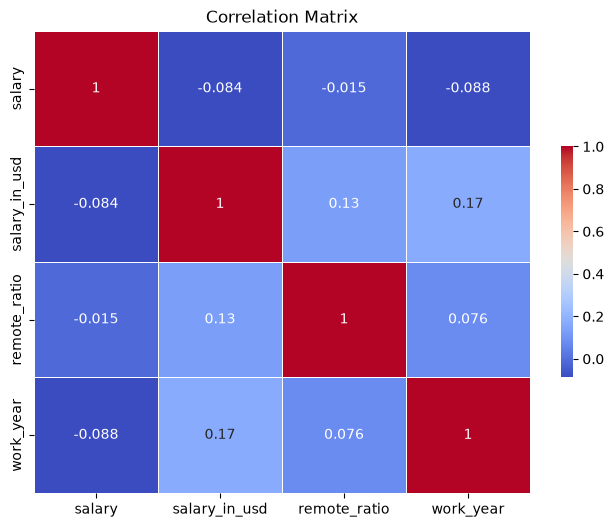

In [43]:
data1 = data[['salary', 'salary_in_usd', 'remote_ratio', 'work_year']]
corr = data1.corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap='coolwarm' , linewidths=0.5 , linecolor='white' , cbar_kws={"shrink": .5})
plt.title("Correlation Matrix")
plt.show()

### 4.2.1 intérprétation

Interprétation de la Correlation Matrix

Corrélations négatives (bleu foncé)
salary vs salary_in_usd = -0.084

Corrélation faible et négative — paradoxal à première vue !
Explication : salary est en devise locale (EUR, GBP, JPY…). Un salaire très élevé en Yen japonais peut être faible en USD → les deux colonnes ne mesurent pas la même chose.

salary vs work_year = -0.088

Très faible corrélation négative → la devise locale du salaire n'a quasiment aucun lien avec l'année.

salary vs remote_ratio = -0.015

Corrélation quasi nulle → le mode de travail n'influence pas le salaire en devise locale.


Corrélations positives (rouge/bleu clair)
salary_in_usd vs work_year = 0.17

Corrélation faible mais positive → les salaires en USD tendent à augmenter avec les années récentes (2020 → 2022). Le marché Data Science est en croissance.

salary_in_usd vs remote_ratio = 0.13

Légèrement positive → les postes full remote sont légèrement mieux rémunérés en USD.

remote_ratio vs work_year = 0.076

Très faible → le télétravail a légèrement augmenté avec les années (effet post-Covid).

### 4.2.2 Décision 

Décisions stratégiques à tirer
Les corrélations faibles ne sont pas un problème — elles révèlent que la rémunération est un phénomène multidimensionnel que ces 4 variables seules n'expliquent pas. Voici les orientations stratégiques clés :
1. Standardiser les comparaisons en USD — Le salaire brut local est un mauvais indicateur de compétitivité globale. Toute politique RH ou benchmark concurrentiel doit s'appuyer sur salary_in_usd.
2. Réviser les grilles salariales annuellement — La légère hausse de salary_in_usd par année (+0.17) reflète l'inflation et la tension du marché tech. Une révision annuelle est nécessaire pour rester compétitif.
3. Le remote est un levier de recrutement, pas de réduction de coûts — La corrélation positive entre remote et salary_in_usd suggère que les profils remote sont souvent plus qualifiés et mieux payés. Le remote attire les talents, il ne les dévalue pas.
4. Explorer d'autres variables explicatives — Étant donné que ces 4 variables s'expliquent peu mutuellement, il est essentiel d'intégrer dans l'analyse des variables comme le niveau d'expérience (entry/senior), le domaine (ML, data eng., analytics), et la région géographique — qui seront bien plus corrélées au salaire.

## 4.3 Comparer des groupes

### 4.3.1 Boxplot

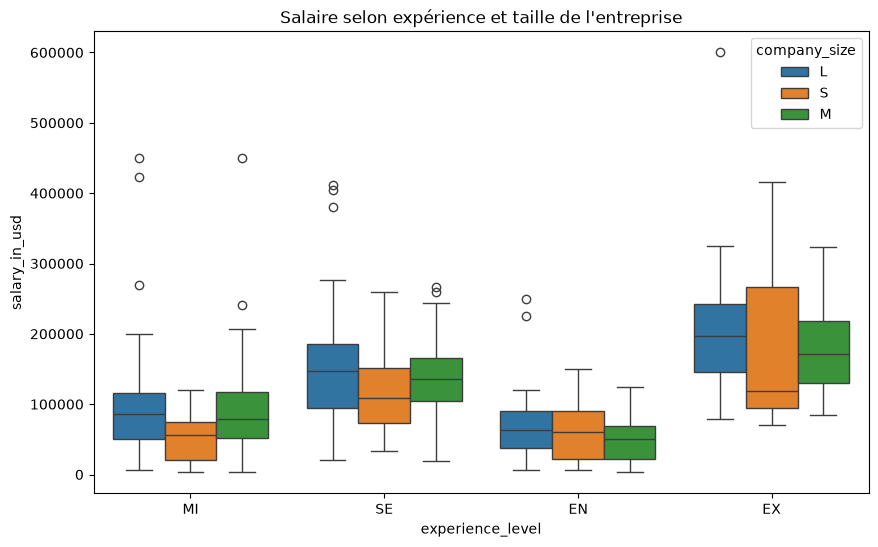

In [44]:
plt.figure(figsize=(10,6))
sns.boxplot(data=data, 
            x="experience_level",
            y="salary_in_usd",
            hue="company_size")
plt.title("Salaire selon expérience et taille de l'entreprise")
plt.show()

Le salaire augmente avec le niveau d’expérience (EN < MI < SE < EX). Pour chaque niveau, les grandes entreprises (L) offrent généralement les salaires les plus élevés, suivies des entreprises moyennes (M), puis des petites (S). La dispersion est plus importante pour les niveaux d’expérience élevés, notamment dans les grandes entreprises.

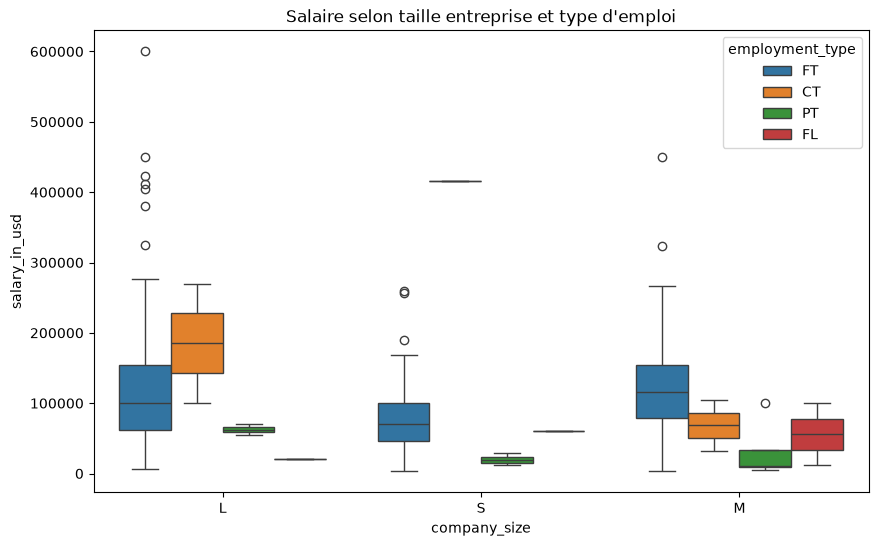

In [45]:
plt.figure(figsize=(10,6))
sns.boxplot(data=data, x="company_size",
            y="salary_in_usd",
            hue="employment_type")
plt.title("Salaire selon taille entreprise et type d'emploi")
plt.show()

Le salaire varie selon la taille de l’entreprise et le type d’emploi. Les emplois à temps plein (FT) offrent globalement les salaires les plus élevés, surtout dans les grandes entreprises (L). Les contrats (CT) présentent aussi des salaires élevés mais avec une forte variabilité. Les emplois à temps partiel (PT) et freelance (FL) ont généralement des salaires plus faibles, quel que soit la taille de l’entreprise.

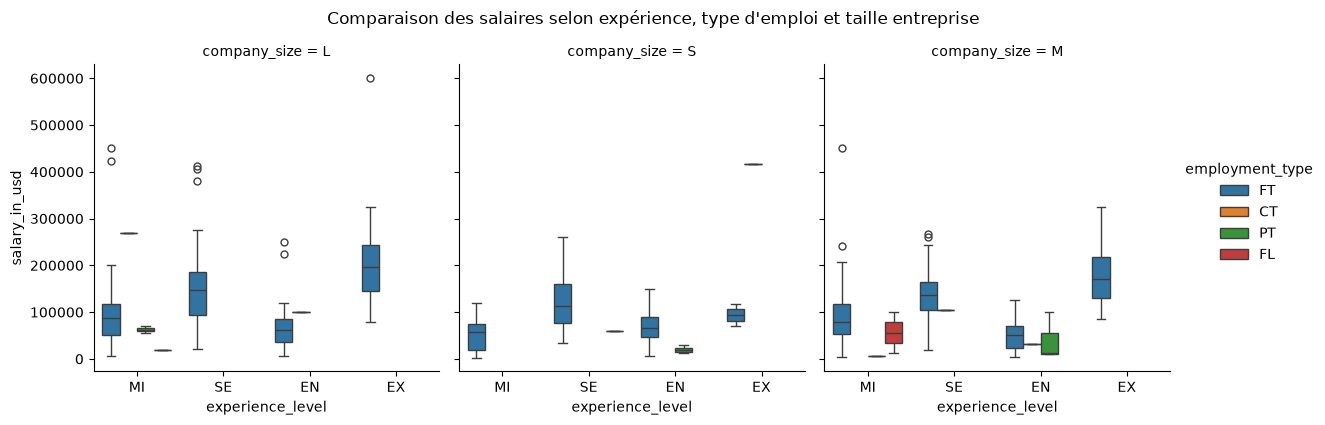

In [46]:
g = sns.catplot(
    data=data,
    x="experience_level",
    y="salary_in_usd",
    hue="employment_type",
    col="company_size",
    kind="box",
    height=4,
    aspect=1
)

g.fig.suptitle("Comparaison des salaires selon expérience, type d'emploi et taille entreprise", y=1.05)
plt.show()

Ce graphique analyse la distribution des salaires en combinant le niveau d'expérience, le type d'emploi et la taille de l'entreprise. Les grandes entreprises concentrent les salaires les plus élevés, notamment pour les profils executives (EX) et seniors (SE) en contrat à temps plein (FT). Les contrats (CT) sont réservés aux grandes et moyennes entreprises, tandis que les petites entreprises n'emploient que des profils juniors à seniors en temps plein ou temps partiel, avec des salaires modestes. Les freelances (FL) restent rares et limités aux petites structures

### 4.3.2 Violin plot

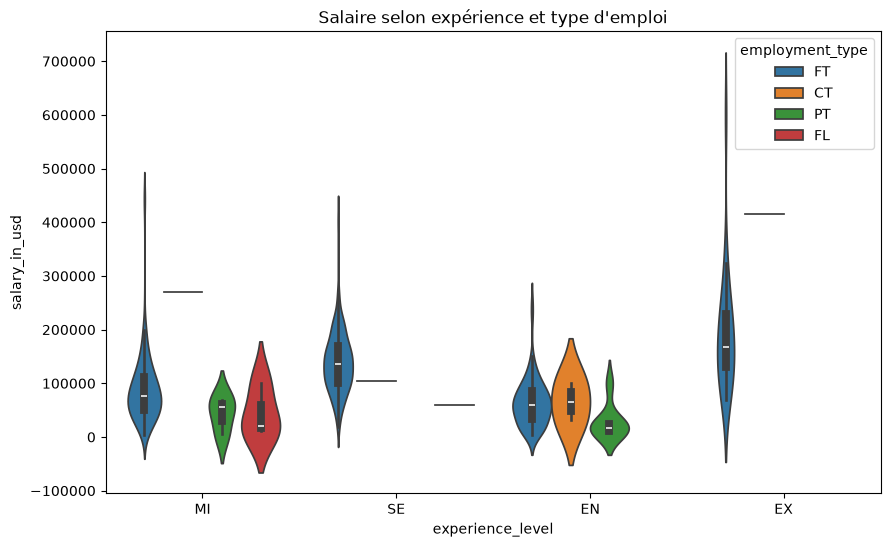

In [47]:
plt.figure(figsize=(10,6))
sns.violinplot(data=data,
               x="experience_level",
               y="salary_in_usd",
               hue="employment_type")
plt.title("Salaire selon expérience et type d'emploi")
plt.show()

Les temps pleins (FT) offrent les salaires les plus élevés et les plus dispersés, particulièrement pour les seniors et executives. Les contrats (CT) sont rares et limités aux profils MI et EX. Les temps partiels (PT) et freelances (FL) sont concentrés sur les bas salaires, principalement pour les juniors et mi-level.



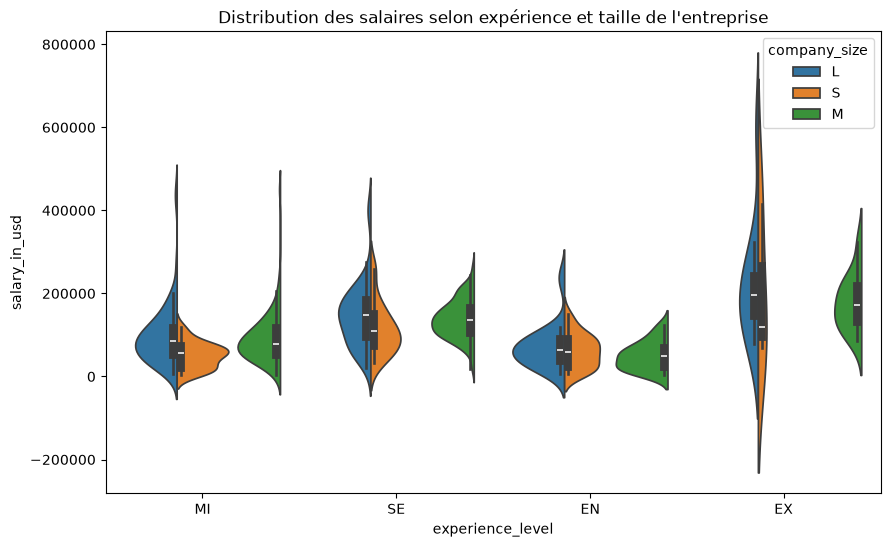

In [48]:
plt.figure(figsize=(10,6))
sns.violinplot(
    data=data,
    x="experience_level",
    y="salary_in_usd",
    hue="company_size",
    split=True
)
plt.title("Distribution des salaires selon expérience et taille de l'entreprise")
plt.show()

Les grandes entreprises (L) affichent une distribution étalée pour les seniors et executives, avec des salaires atteignant 600 000 USD. Les petites entreprises (S) ont des violons resserrés, concentrés entre 50 000 et 150 000 USD pour tous les niveaux. Les entreprises moyennes (M) occupent une position intermédiaire. Seules les grandes entreprises présentent des executives (EX) avec une forte variabilité salariale.



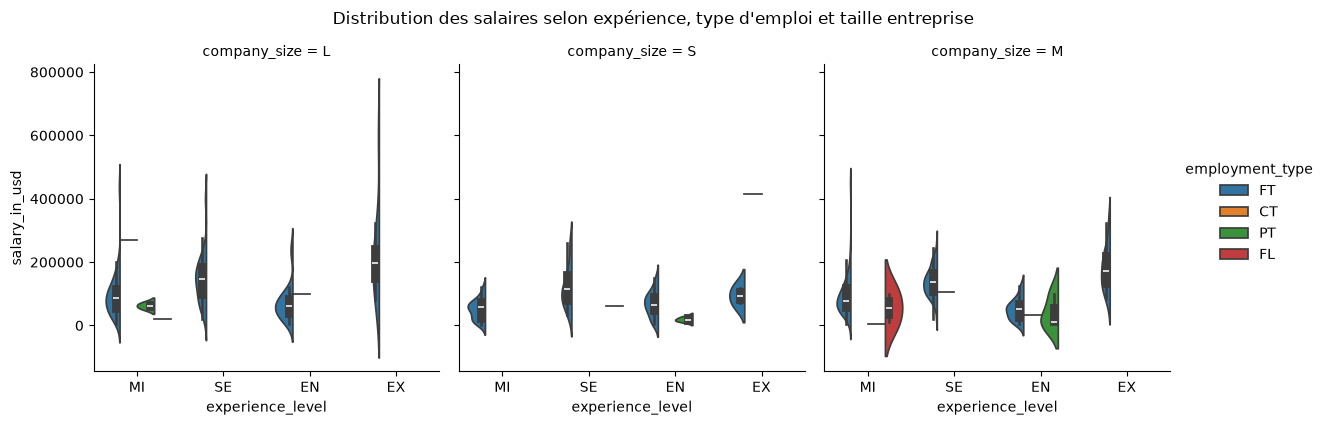

In [49]:
g = sns.catplot(
    data=data,
    x="experience_level",
    y="salary_in_usd",
    hue="employment_type",
    col="company_size",
    kind="violin",
    height=4,
    aspect=1,
    split=True
)

g.fig.suptitle("Distribution des salaires selon expérience, type d'emploi et taille entreprise", y=1.05)
plt.show()

Ce graphique confirme que les grandes entreprises concentrent les salaires les plus élevés, avec des profils executives (EX) et seniors (SE) en temps plein (FT) atteignant des niveaux très hauts. Les contrats (CT) apparaissent uniquement dans les grandes et moyennes entreprises, principalement pour les mi-level (MI). Les petites entreprises n’emploient que des temps pleins (FT) et temps partiels (PT) sur des profils juniors à seniors, avec des salaires faibles et resserrés. Les freelances (FL) sont rares et limités aux petites structures.

### 4.3.3 Décisions

- Les décisions doivent tenir compte de plusieurs facteurs combinés. 
- Les profils expérimentés doivent être orientés vers les grandes entreprises et les emplois à temps plein, où les salaires sont les plus élevés. 
- Le recrutement doit être adapté selon le niveau d’expérience : les profils juniors vers les petites entreprises et les profils intermédiaires vers les entreprises moyennes. 
- Les emplois à temps plein sont à privilégier pour assurer une meilleure stabilité et une rémunération plus élevée. 
- Les contrats à durée déterminée peuvent être utilisés pour des missions spécifiques avec une rémunération intermédiaire, tandis que les emplois à temps partiel et freelance doivent être limités aux situations nécessitant plus de flexibilité. 
- Enfin, les stratégies de recrutement doivent intégrer simultanément l’expérience, la taille de l’entreprise et le type d’emploi.

## 4.4 Analyse des profils multivariés (Parallel Coordinates)

Le diagramme de coordonnées parallèles est une méthode de visualisation multivariée qui permet de représenter plusieurs variables numériques simultanément, chaque observation étant tracée sous forme d’une ligne reliant les axes. Dans ce graphique, l’objectif est de comparer les profils des individus selon plusieurs variables (work_year, salary_in_usd, remote_ratio) en fonction du niveau d’expérience (experience_level). Cela permet d’identifier des tendances, notamment l’influence de l’expérience sur le salaire, ainsi que de visualiser les similarités ou différences entre les différents groupes.

### 4.4.1 Sans normalisation

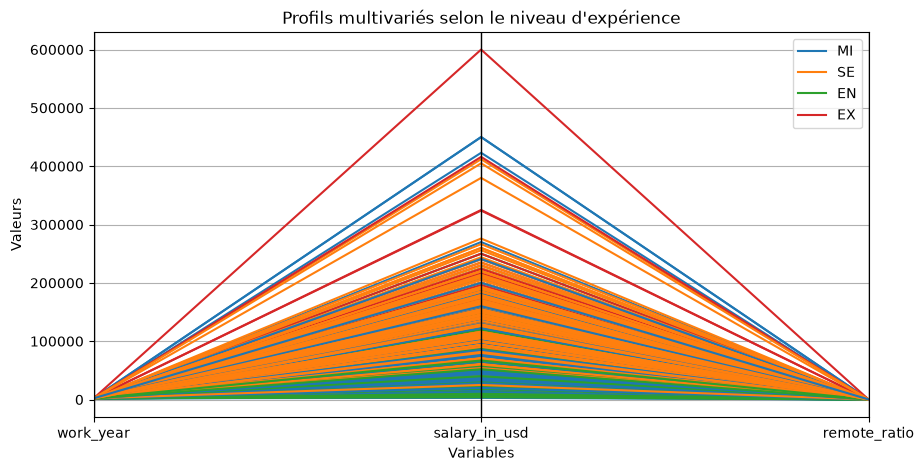

In [50]:
from pandas.plotting import parallel_coordinates
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

parallel_coordinates(
    data[["work_year","salary_in_usd","remote_ratio","experience_level"]],
    class_column="experience_level",
    color=["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"] 
)

plt.title("Profils multivariés selon le niveau d'expérience")
plt.xlabel("Variables")
plt.ylabel("Valeurs")

plt.show()

Le salaire augmente avec le niveau d’expérience, tandis que le télétravail et l’année ont peu d’impact visible. Cependant, l’absence de normalisation rend l’analyse moins précise.

### 4.4.2 Après normalisation

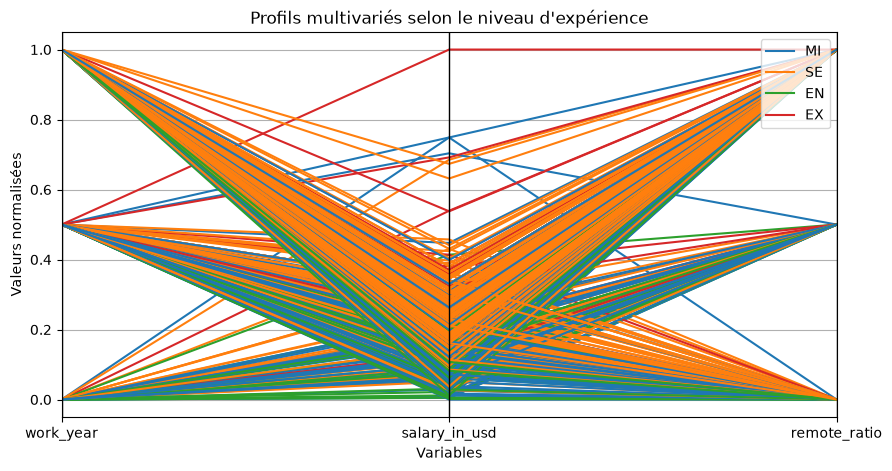

In [51]:
from sklearn.preprocessing import MinMaxScaler
from pandas.plotting import parallel_coordinates
import matplotlib.pyplot as plt

# normalisation
cols = ["work_year","salary_in_usd","remote_ratio"]

scaler = MinMaxScaler()
data_scaled = data.copy()
data_scaled[cols] = scaler.fit_transform(data[cols])

# plot
plt.figure(figsize=(10,5))

parallel_coordinates(
    data_scaled[cols + ["experience_level"]],
    class_column="experience_level",
    color=["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"] 
)

plt.title("Profils multivariés selon le niveau d'expérience")
plt.xlabel("Variables")
plt.ylabel("Valeurs normalisées")

plt.show()

Après normalisation, toutes les variables sont mises sur la même échelle, ce qui permet une comparaison plus pertinente. On observe que le salaire (salary_in_usd) reste globalement plus élevé pour les niveaux d’expérience supérieurs (EX et SE), ce qui confirme l’influence de l’expérience sur la rémunération. En revanche, le taux de télétravail (remote_ratio) est très dispersé et ne montre pas de relation claire avec l’expérience. De plus, la variable work_year varie peu et n’apparaît pas comme déterminante. Enfin, le chevauchement des lignes indique que certains profils présentent des caractéristiques similaires malgré leur différence de catégorie.

### 4.4.3 Echantillon

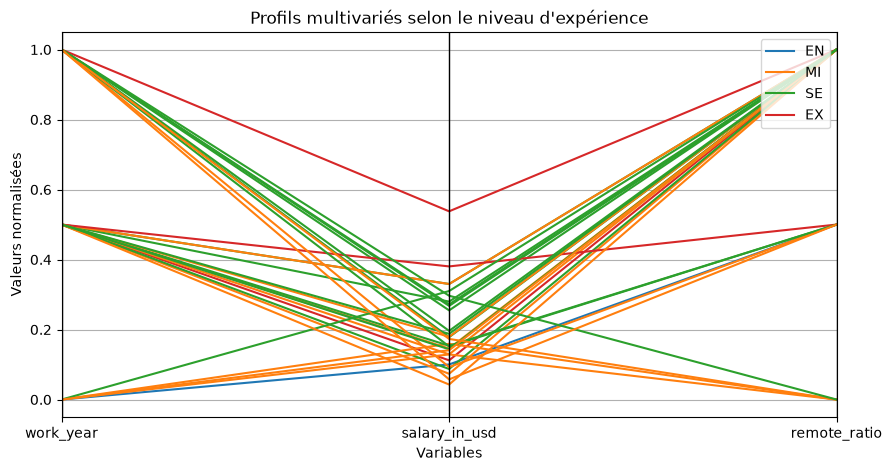

In [52]:
from sklearn.preprocessing import MinMaxScaler
from pandas.plotting import parallel_coordinates
import matplotlib.pyplot as plt

cols = ["work_year","salary_in_usd","remote_ratio"]

scaler = MinMaxScaler()
data_scaled = data.copy()
data_scaled[cols] = scaler.fit_transform(data[cols])

data_sample = data_scaled.sample(30, random_state=1)

# plot
plt.figure(figsize=(10,5))

parallel_coordinates(
    data_sample[cols + ["experience_level"]],
    class_column="experience_level",
    color=["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"] 
)

plt.title("Profils multivariés selon le niveau d'expérience")
plt.xlabel("Variables")
plt.ylabel("Valeurs normalisées")

plt.show()

Après normalisation et réduction de l’échantillon, le graphique devient plus lisible et permet une meilleure comparaison des variables. On observe que les niveaux d’expérience élevés (notamment EX et SE) ont généralement des valeurs plus importantes en termes de salaire, ce qui confirme que l’expérience influence positivement la rémunération. En revanche, le taux de télétravail (remote_ratio) reste très variable pour tous les profils, sans tendance claire selon l’expérience. La variable work_year montre peu de différence entre les individus. Enfin, même si certaines tendances apparaissent, le croisement des lignes indique que les profils ne sont pas totalement distincts et présentent des caractéristiques parfois similaires.

### Décisions

- Mettre en place des programmes de formation et de promotion interne pour faire évoluer les juniors vers des postes mieux rémunérés
- Augmenter les salaires ou proposer des avantages compétitifs pour attirer et retenir les profils seniors (SE, EX)
- La normalisation des données doit être appliquée pour des analyses fiables

## 4.5 Simplifier les données complexes

In [53]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [54]:
# Sélection des variables numériques
cols = ["salary_in_usd", "remote_ratio", "work_year"]
X = data[cols]

#Standardisation
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

### 4.5.1 ACP avec 2 composantes (2D)

Variance expliquée : [0.41880966 0.30894758]


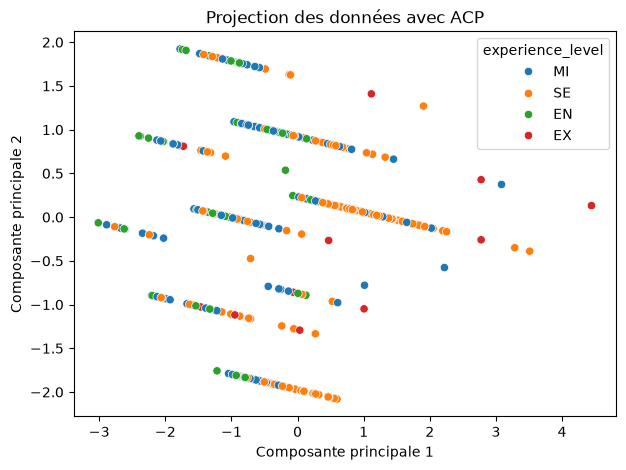


Contribution des variables :
     salary_in_usd  remote_ratio  work_year
PC1       0.643082      0.503151   0.577309
PC2      -0.114030      0.808377  -0.577515


In [55]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# ACP (2 composantes)
pca = PCA(n_components=2)
components = pca.fit_transform(X_scaled)

# DataFrame PCA
df_pca = pd.DataFrame(components, columns=["PC1","PC2"])
df_pca["experience_level"] = data["experience_level"]

# Variance expliquée
print("Variance expliquée :", pca.explained_variance_ratio_)

# Visualisation
plt.figure(figsize=(7,5))

sns.scatterplot(
    data=df_pca,
    x="PC1",
    y="PC2",
    hue="experience_level"
)

plt.title("Projection des données avec ACP")
plt.xlabel("Composante principale 1")
plt.ylabel("Composante principale 2")

plt.show()

# Contribution des variables
contributions_vars = pd.DataFrame(
    pca.components_,
    columns=cols,
    index=["PC1","PC2"]
)

print("\nContribution des variables :")
print(contributions_vars)

### 4.5.2 Visualisation avec 3 composantes (3D)

Variance expliquée : [0.41880966 0.30894758 0.27224275]


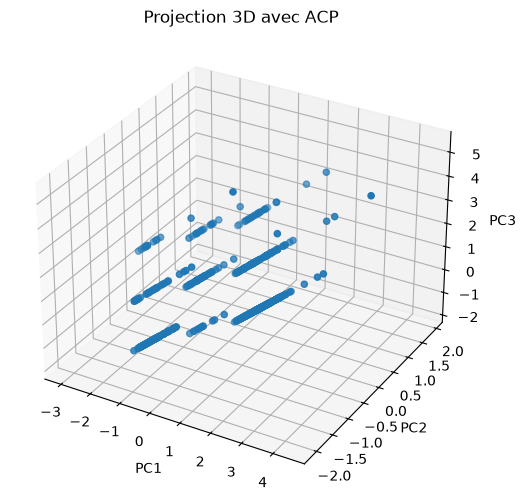


Contribution des variables :
     work_year  salary_in_usd  remote_ratio
PC1   0.643082       0.503151      0.577309
PC2  -0.114030       0.808377     -0.577515
PC3   0.757260      -0.305559     -0.577226


In [56]:
from sklearn.decomposition import PCA

# ACP (3 composantes)
pca = PCA(3)
pca.fit(X_scaled)

# Variance expliquée
print("Variance expliquée :", pca.explained_variance_ratio_)

X_pca = pca.fit_transform(X_scaled)

# Plot 3D 
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(X_pca[:,0],X_pca[:,1],X_pca[:,2])

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.set_title("Projection 3D avec ACP")

plt.show()

# Contribution des variables
contributions_vars = pd.DataFrame(
    pca.components_,
    columns=["work_year", "salary_in_usd", "remote_ratio"],
    index=["PC1","PC2","PC3"]
)

print("\nContribution des variables :")
print(contributions_vars)

### 4.5.3 Interprétations

#### Interprétation de l'ACP

##### PCA 2D (2 composantes)

###### Variance expliquée
- PC1 : 41.88%
- PC2 : 30.89%
- Total : 72.78%

Cela signifie qu'on perd environ 27% de l'information en passant à 2 dimensions.

###### Observations
- Présence de bandes diagonales parallèles, ce qui indique que certaines variables sont corrélées.
- Une dispersion des points selon PC1.
- Les niveaux d'expérience (Mid level, Senior, Entry, Executive) sont mélangés.

---

##### PCA avec 3 composantes (2D projection)

###### Variance expliquée
- PC1 : 41.88%
- PC2 : 30.89%
- PC3 : 27.22%
- Total : 99.99%

Cela signifie qu’en 3 dimensions, on conserve presque toute l’information initiale.

###### Interprétation
- PC3 joue un rôle important pour distinguer des profils qui semblaient similaires avec seulement PC1 et PC2.

---

###### PCA 3D

###### Observations
- La représentation 3D est meilleure que la 2D.
- Présence de bandes parallèles.
- Les données suivent des relations linéaires.


###### Valeurs atypiques
- Présence de points isolés.
- Certains points sont éloignés du groupe principal.

---

##### Décision

L’ACP permet une bonne réduction de dimension et une visualisation globale des données.  
Cependant, elle ne permet pas de séparer clairement les niveaux d’expérience.  
Cela suggère que les variables actuelles ne sont pas suffisantes pour une tâche de classification.

# 5. Visualisation des données temporelles et géo-spatiales

remarque : 
pip install plotly,pycoutry,geopandas,scipy,graphiz,geodatasets

## 6. Visualisation Temporelle 

In [57]:
from statsmodels.nonparametric.smoothers_lowess import lowess
from scipy.interpolate import make_interp_spline

### 6.1 Suivre l'évolution d'une variable dans le temps

Évolution du salaire moyen par année

#### Courbe simple

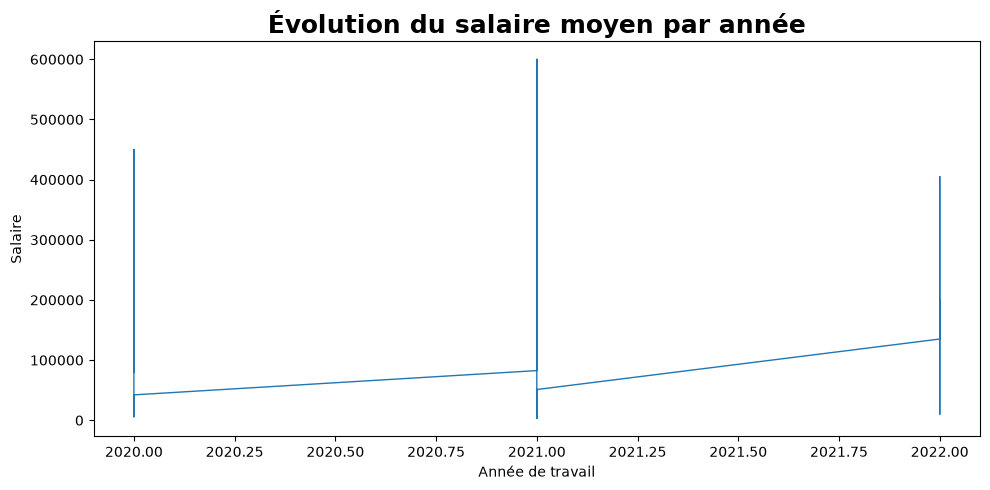

In [58]:
plt.figure(figsize=(10,5))

plt.plot(data["work_year"], data["salary_in_usd"], linewidth=1)

plt.title("Évolution du salaire moyen par année", fontsize=18, weight="bold")

plt.xlabel("Année de travail")
plt.ylabel("Salaire")

plt.tight_layout()
plt.show()

Le graphique montre l’évolution du salaire moyen entre 2020 et 2022.

On observe une augmentation globale des salaires.
Entre 2020 et 2021, l’augmentation est modérée.
Entre 2021 et 2022, la croissance devient plus importante.
La présence de valeurs très élevées (outliers) indique que certains salaires élevés influencent la moyenne.

  Cette évolution suggère une augmentation de la demande en compétences et une valorisation progressive des profils.

#### Graphique en aires

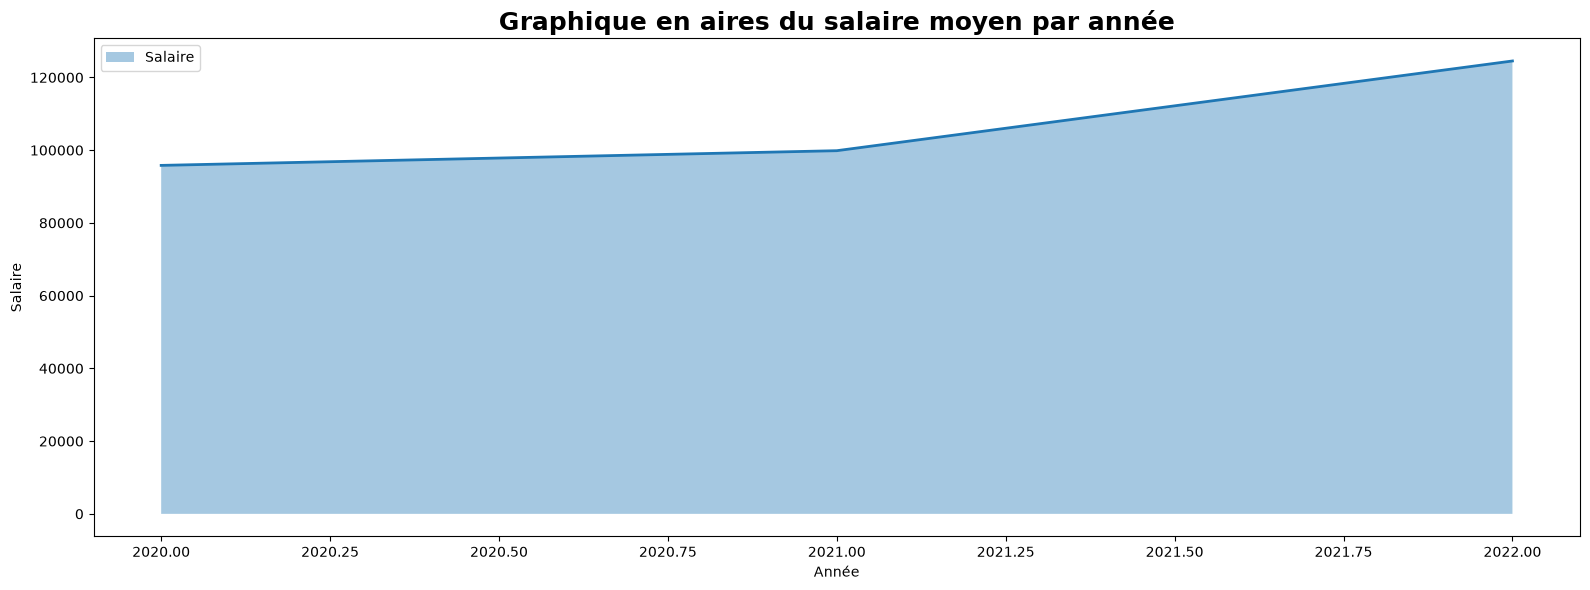

In [59]:
salary_per_year = data.groupby("work_year")["salary_in_usd"].mean()

plt.figure(figsize=(16, 6))

plt.fill_between(salary_per_year.index, salary_per_year.values, alpha=0.4, label="Salaire")

plt.plot(salary_per_year.index, salary_per_year.values, linewidth=2)

plt.title("Graphique en aires du salaire moyen par année", fontsize=18, weight="bold")

plt.xlabel("Année")
plt.ylabel("Salaire")

plt.legend()

plt.tight_layout()
plt.show()

Le graphique en aires met en évidence l’évolution du salaire moyen au fil des années.

La surface augmente de manière continue , cela confirme une croissance stable.
La montée est plus rapide après 2021, ce qui traduit une accélération des salaires.

Ce type de graphique insiste sur le volume global et la tendance générale, plutôt que sur les variations ponctuelles.

L’analyse temporelle des salaires (2020–2022) met en évidence une tendance haussière continue du salaire moyen. Cette augmentation est progressive entre 2020 et 2021, puis s’accélère nettement entre 2021 et 2022, ce qui traduit une forte dynamique du marché de l’emploi, notamment dans les métiers liés à la data.

Cependant, la présence de valeurs extrêmes (salaires très élevés) indique une forte hétérogénéité dans les rémunérations. Cela signifie que la moyenne peut être influencée par quelques salaires atypiques, et ne reflète pas toujours la réalité globale.

En résumé, le marché est :

- en croissance
- en accélération récente
- inégalement réparti (dispersion importante des salaires)

#### Décisions:

D’après cette analyse, plusieurs décisions peuvent être prises:

La hausse des salaires, surtout en 2022, montre qu’il faut ajuster les rémunérations pour rester compétitif.
À cause des fortes variations, il ne faut pas se baser uniquement sur la moyenne, mais utiliser des indicateurs plus fiables.
il est important de mettre à jour régulièrement les analyses pour suivre l’évolution du marché et adapter les stratégies. 


### 6.2 Comparer plusieurs séries temporelles

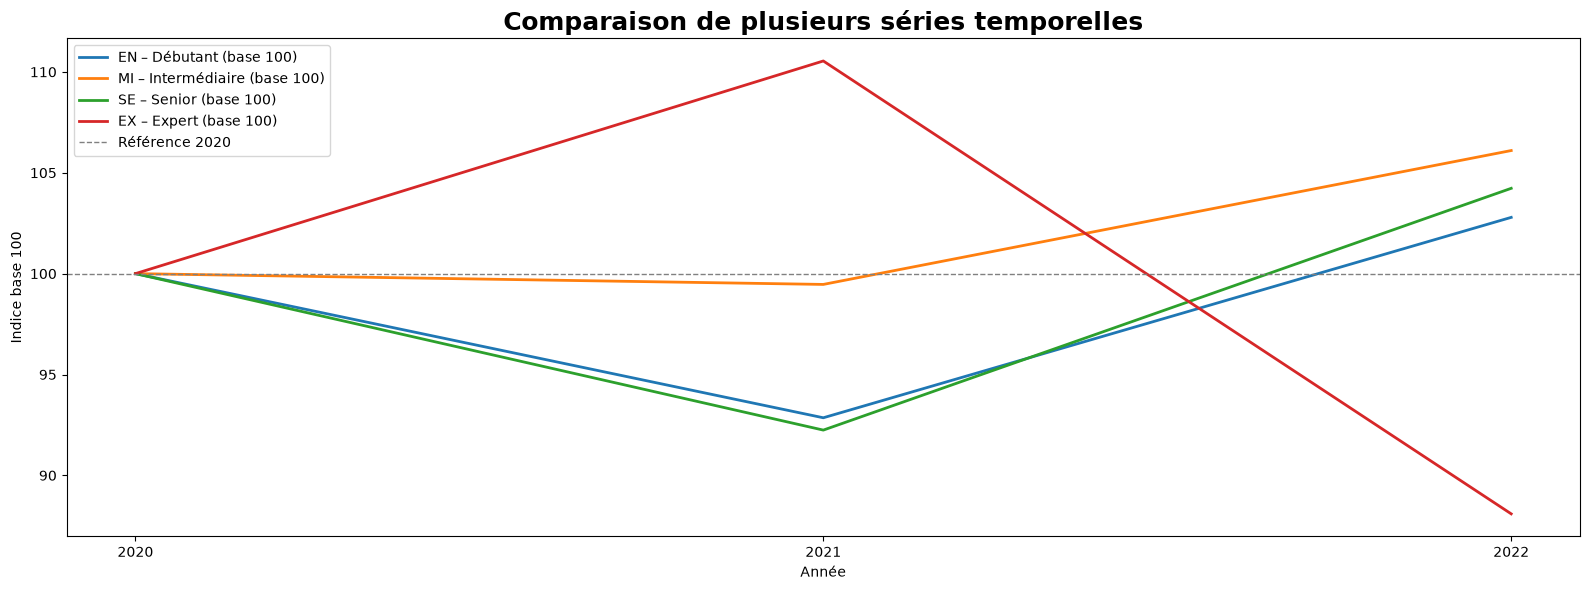

In [60]:
# Mise en base 100
multi_df = data[["work_year", "salary_in_usd", "experience_level"]].copy()

# ── Correction 1 : calculer la moyenne par année ET par niveau ──
multi_df = (multi_df.groupby(["work_year", "experience_level"])["salary_in_usd"]
                    .mean()
                    .reset_index())

# ── Correction 2 : pivoter pour avoir une colonne par niveau ────
multi_df = multi_df.pivot(index="work_year", columns="experience_level",
                          values="salary_in_usd").reset_index()
multi_df.columns.name = None

# Mise en base 100 (même logique que le prof)
base_values = multi_df[["EN", "MI", "SE", "EX"]].iloc[0]
multi_df[["EN", "MI", "SE", "EX"]] = multi_df[["EN", "MI", "SE", "EX"]].div(base_values).mul(100)

plt.figure(figsize=(16, 6))

# ── Correction 3 : tracer une courbe par niveau ─────────────────
plt.plot(multi_df["work_year"], multi_df["EN"], label="EN – Débutant (base 100)",        linewidth=2)
plt.plot(multi_df["work_year"], multi_df["MI"], label="MI – Intermédiaire (base 100)",   linewidth=2)
plt.plot(multi_df["work_year"], multi_df["SE"], label="SE – Senior (base 100)",           linewidth=2)
plt.plot(multi_df["work_year"], multi_df["EX"], label="EX – Expert (base 100)",           linewidth=2)

plt.axhline(y=100, color="gray", linestyle="--", linewidth=1, label="Référence 2020")

plt.title("Comparaison de plusieurs séries temporelles", fontsize=18, weight="bold")
plt.xlabel("Année")
plt.ylabel("Indice base 100")
plt.xticks(multi_df["work_year"])
plt.legend()
plt.tight_layout()
plt.show()

**intérprétation :** 

les salaires des débutants ont augmenté plus rapidement que ceux des seniors et experts, ce qui peut indiquer une forte demande pour les profils juniors dans le domaine de la data science.
et que les entreprises sont prêtes à offrir des salaires compétitifs pour attirer les talents débutants.
#décision : les débutants ont vu une croissance plus rapide de leurs salaires, ce qui peut être un signe positif pour les personnes entrant dans le domaine de la data science.
Cependant, il est important de noter que les seniors et experts continuent d'avoir des salaires élevés, même si leur taux de croissance est plus lent.

### 6.3 Mettre en évidence une tendance générale

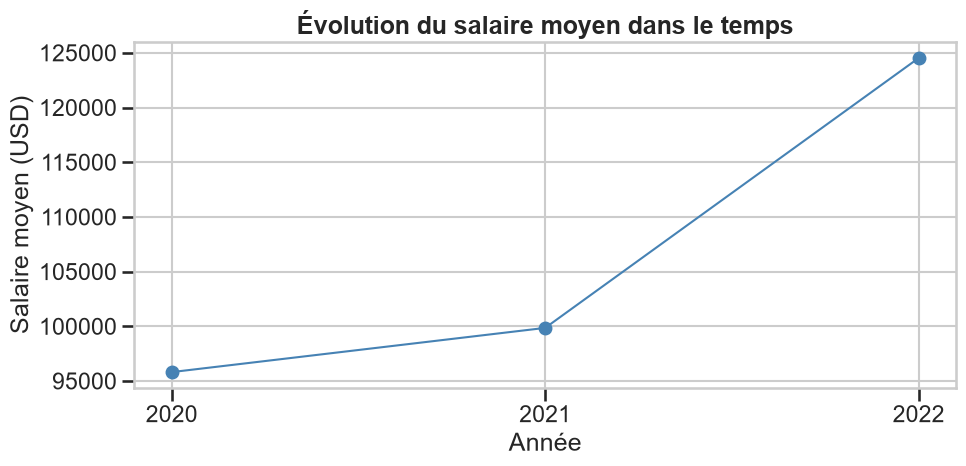

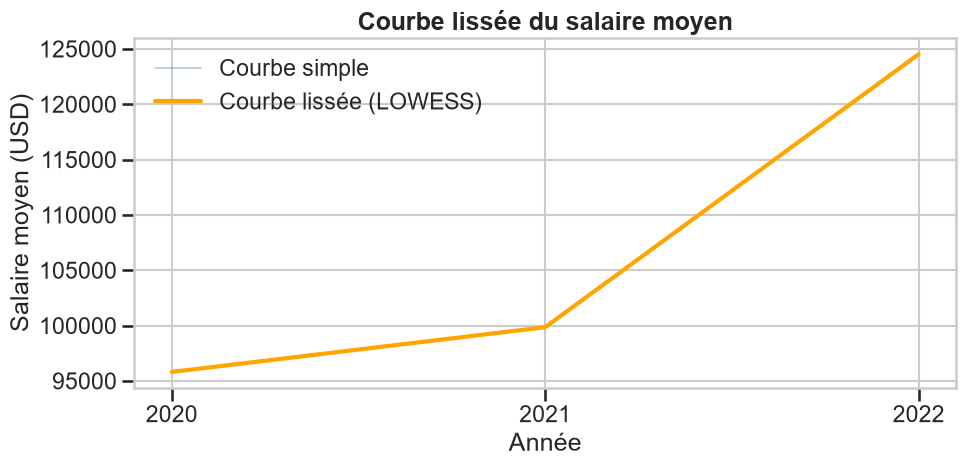

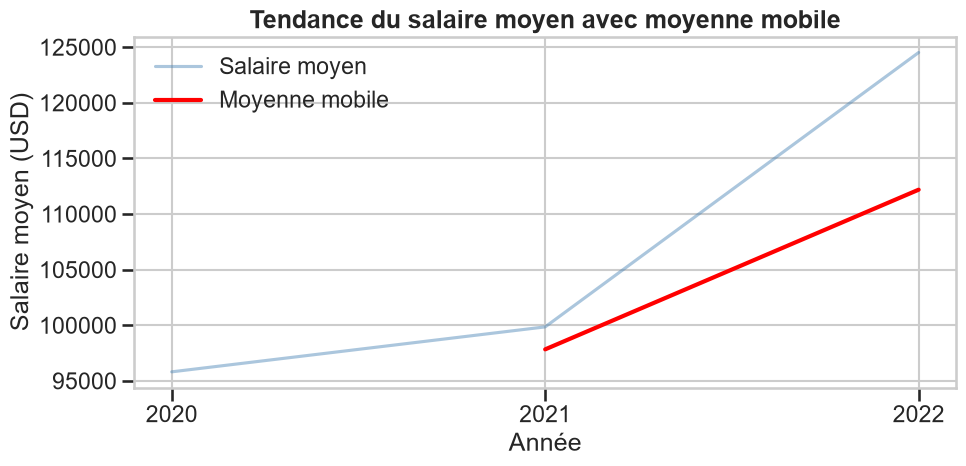

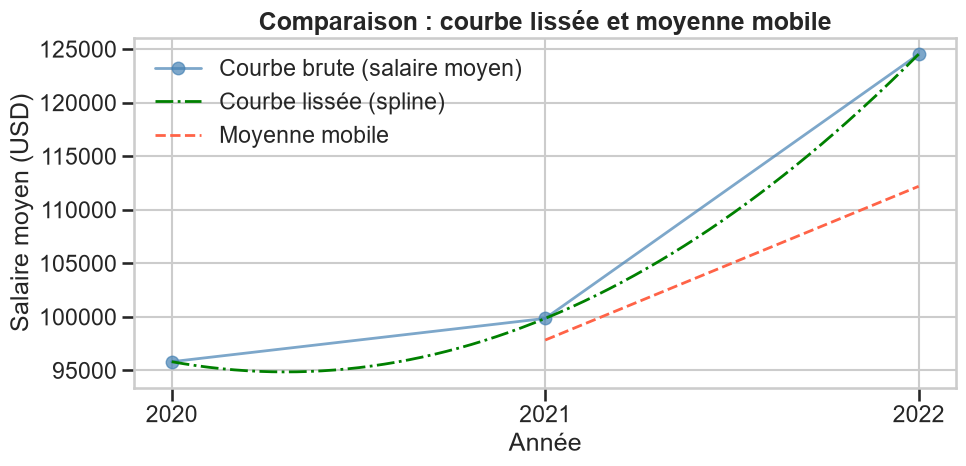

In [61]:
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_context("talk")

# ----- Préparation des données -----
salary_par_annee = data.groupby("work_year")["salary_in_usd"].mean().reset_index()
salary_par_annee.columns = ["work_year", "salary_moyen"]

# Moyenne mobile
salary_par_annee["rolling_mean"] = salary_par_annee["salary_moyen"].rolling(window=2).mean()

# Courbe lissée LOWESS
x_lowess = np.arange(len(salary_par_annee))
y_lisse = lowess(salary_par_annee["salary_moyen"], x_lowess, frac=0.8, return_sorted=False)

# Courbe lissée Spline
x = salary_par_annee["work_year"].values
y = salary_par_annee["salary_moyen"].values
x_smooth = np.linspace(x.min(), x.max(), 300)
spline = make_interp_spline(x, y, k=2)
y_smooth = spline(x_smooth)

# ----- Graphique 1 : Courbe simple -----
plt.figure(figsize=(10, 5))
plt.plot(salary_par_annee["work_year"], salary_par_annee["salary_moyen"],
         marker="o", linewidth=1.5, color="steelblue", label="Courbe simple")
plt.title("Évolution du salaire moyen dans le temps", fontsize=18, weight="bold")
plt.xlabel("Année")
plt.ylabel("Salaire moyen (USD)")
plt.xticks(salary_par_annee["work_year"].astype(int))
plt.tight_layout()
plt.show()

# ----- Graphique 2 : Courbe lissée -----
plt.figure(figsize=(10, 5))
plt.plot(salary_par_annee["work_year"], salary_par_annee["salary_moyen"],
         label="Courbe simple", alpha=0.35, linewidth=1.5, color="steelblue")
plt.plot(salary_par_annee["work_year"], y_lisse,
         label="Courbe lissée (LOWESS)", linewidth=3, color="orange")
plt.title("Courbe lissée du salaire moyen", fontsize=18, weight="bold")
plt.xlabel("Année")
plt.ylabel("Salaire moyen (USD)")
plt.xticks(salary_par_annee["work_year"].astype(int))
plt.legend()
plt.tight_layout()
plt.show()

# ----- Graphique 3 : Moyenne mobile -----
plt.figure(figsize=(10, 5))
plt.plot(salary_par_annee["work_year"], salary_par_annee["salary_moyen"],
         alpha=0.45, label="Salaire moyen", color="steelblue")
plt.plot(salary_par_annee["work_year"], salary_par_annee["rolling_mean"],
         color="red", linewidth=3, label="Moyenne mobile")
plt.title("Tendance du salaire moyen avec moyenne mobile", fontsize=18, weight="bold")
plt.xlabel("Année")
plt.ylabel("Salaire moyen (USD)")
plt.xticks(salary_par_annee["work_year"].astype(int))
plt.legend()
plt.tight_layout()
plt.show()

# ----- Graphique 4 : Comparaison finale -----
fig, ax = plt.subplots(figsize=(10, 5))

# Courbe brute
ax.plot(salary_par_annee["work_year"], salary_par_annee["salary_moyen"],
        marker="o", linewidth=2, color="steelblue",
        label="Courbe brute (salaire moyen)", alpha=0.7)

# Courbe lissée Spline
ax.plot(x_smooth, y_smooth,
        linewidth=2, color="green", linestyle="-.",
        label="Courbe lissée (spline)")

# Moyenne mobile
ax.plot(salary_par_annee["work_year"], salary_par_annee["rolling_mean"],
        linestyle="--", linewidth=2, color="tomato",
        label="Moyenne mobile")

ax.set_title("Comparaison : courbe lissée et moyenne mobile", fontsize=18, fontweight="bold")
ax.set_xlabel("Année")
ax.set_ylabel("Salaire moyen (USD)")
ax.set_xticks(salary_par_annee["work_year"])
ax.set_xticklabels(salary_par_annee["work_year"].astype(int))
ax.legend()
plt.tight_layout()
plt.show()

**Remarque :**

 "Pour le graphique de comparaison finale, nous avons utilisé la courbe lissée Spline à la place de LOWESS, car avec seulement 3 points de données (2020, 2021, 2022), LOWESS suit exactement la courbe brute et ne montre pas de différence visible. La Spline permet de mieux distinguer les trois courbes et rend le graphique plus lisible.

**Interprétation :**

Courbe brute : le salaire moyen réel passe de 95 000 USD en 2020 à 125 000 USD en 2022, avec une accélération forte entre 2021 et 2022    
Courbe lissée : suit presque exactement la courbe brute, ce qui confirme qu'il n'y a pas de fluctuations — la tendance est régulière et stable  
Moyenne mobile : toujours en dessous des deux autres courbes car elle retarde légèrement, mais confirme sans ambiguïté la tendance haussière générale   

Les 3 courbes racontent la même histoire : les salaires en Data Science augmentent continuellement et fortement.

**Décision :**

La tendance haussière confirmée par les trois courbes indique que le marché de la Data Science est en pleine croissance. Les entreprises doivent donc anticiper cette évolution en révisant leurs grilles salariales à la hausse pour attirer et fidéliser leurs talents, avant que les coûts de recrutement deviennent encore plus élevés dans les années à venir.

### 6.4 Détecter une saisonnalité ou des cycles

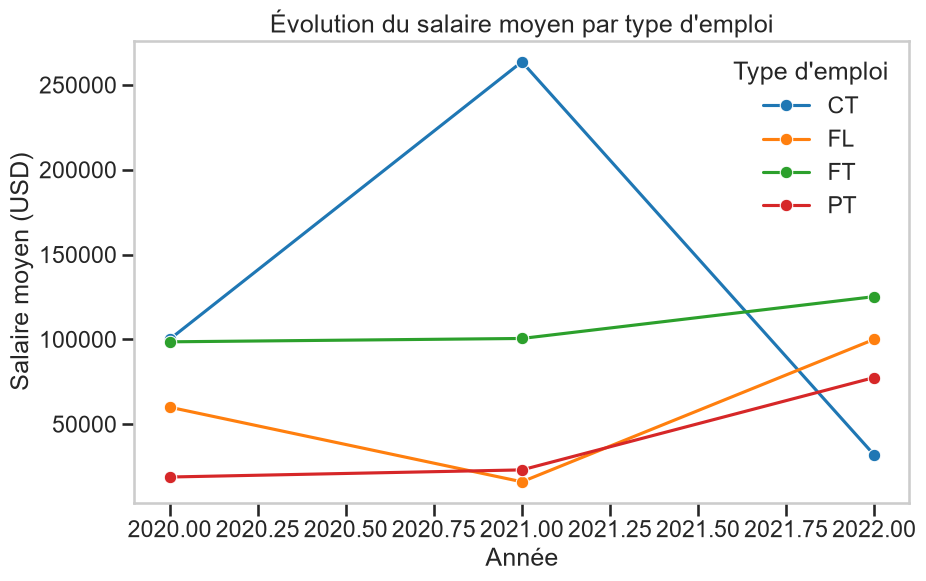

In [62]:
# Moyenne par année et type d'emploi
df_line = data.groupby(["work_year", "employment_type"])["salary_in_usd"].mean().reset_index()

plt.figure(figsize=(10,6))

sns.lineplot(
    data=df_line,
    x="work_year",
    y="salary_in_usd",
    hue="employment_type",
    marker="o"
)

plt.title("Évolution du salaire moyen par type d'emploi")
plt.xlabel("Année")
plt.ylabel("Salaire moyen (USD)")
plt.legend(title="Type d'emploi")
plt.grid()

plt.show()

**Observations :**

- Le salaire moyen évolue différemment selon le type d’emploi.
- On observe une forte variation pour certains types :
- - Le type emploi en contrat temporaire connaît un pic important en 2021 puis une baisse en 2022.
- - Le type emploi à temps plein reste relativement stable avec une légère augmentation.
- Les types emploi à temps partiel et travailleur indépendant montrent des niveaux de salaires plus faibles mais en progression en 2022.
- Il n’y a pas de tendance régulière (pas de saisonnalité claire).

**Conclusion :**

Les salaires évoluent de manière irrégulière selon le type d’emploi, sans cycle stable.

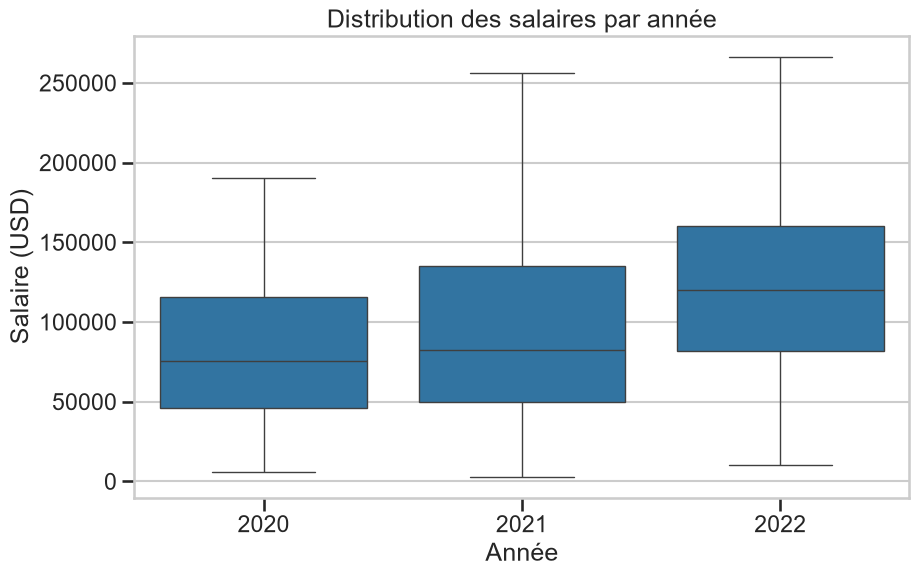

In [63]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=data,
    x="work_year",
    y="salary_in_usd",
    showfliers=False   # enlève les outliers (plus propre visuellement)
)

plt.title("Distribution des salaires par année")
plt.xlabel("Année")
plt.ylabel("Salaire (USD)")

plt.show()

**Observations :**

- La médiane des salaires augmente progressivement de 2020 à 2022.
- La dispersion des salaires devient plus importante au fil des années :
- En 2022, les salaires sont plus étalés (écart plus grand).
- La présence de valeurs élevées indique des salaires très importants pour certains profils.

**Conclusion :**

Le marché des salaires devient plus hétérogène avec une tendance globale à la hausse.

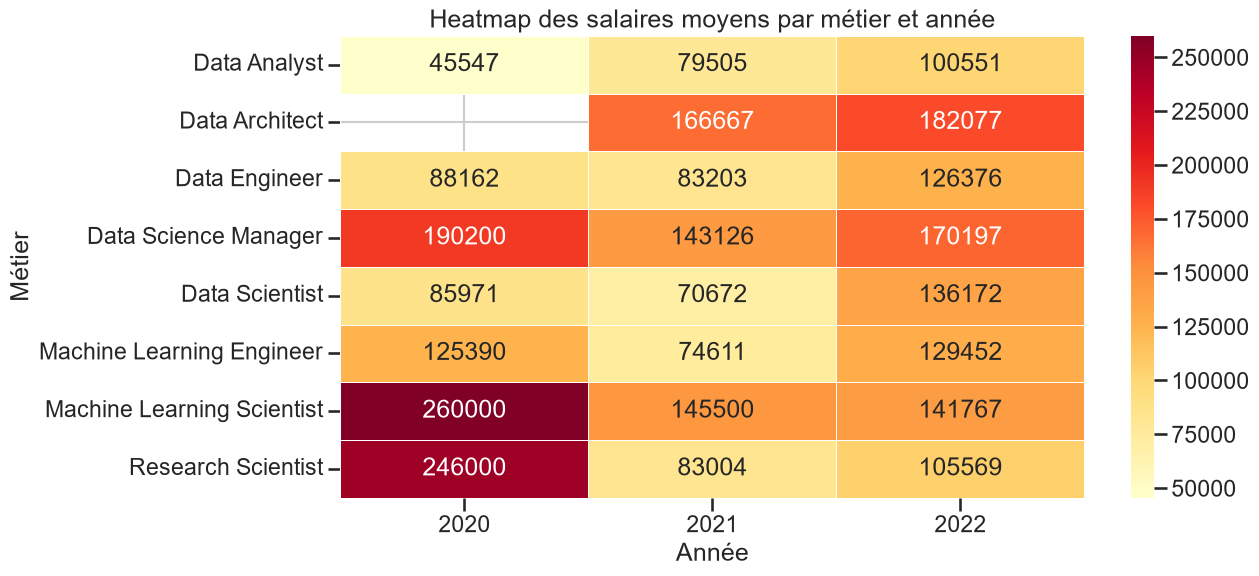

In [64]:
# Top 8 métiers (plus lisible que 10)
top_jobs = data["job_title"].value_counts().head(8).index

df_heat = data[data["job_title"].isin(top_jobs)]

pivot = df_heat.pivot_table(
    index="job_title",
    columns="work_year",
    values="salary_in_usd",
    aggfunc="mean"
)

plt.figure(figsize=(12,6))

sns.heatmap(
    pivot,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Heatmap des salaires moyens par métier et année")
plt.xlabel("Année")
plt.ylabel("Métier")

plt.show()

**Observations :**

- La médiane des salaires augmente progressivement de 2020 à 2022.
- La dispersion des salaires devient plus importante au fil des années :
- En 2022, les salaires sont plus étalés (écart plus grand).
- La présence de valeurs élevées indique des salaires très importants pour certains profils.

### 6.5 Repérer des anomalies

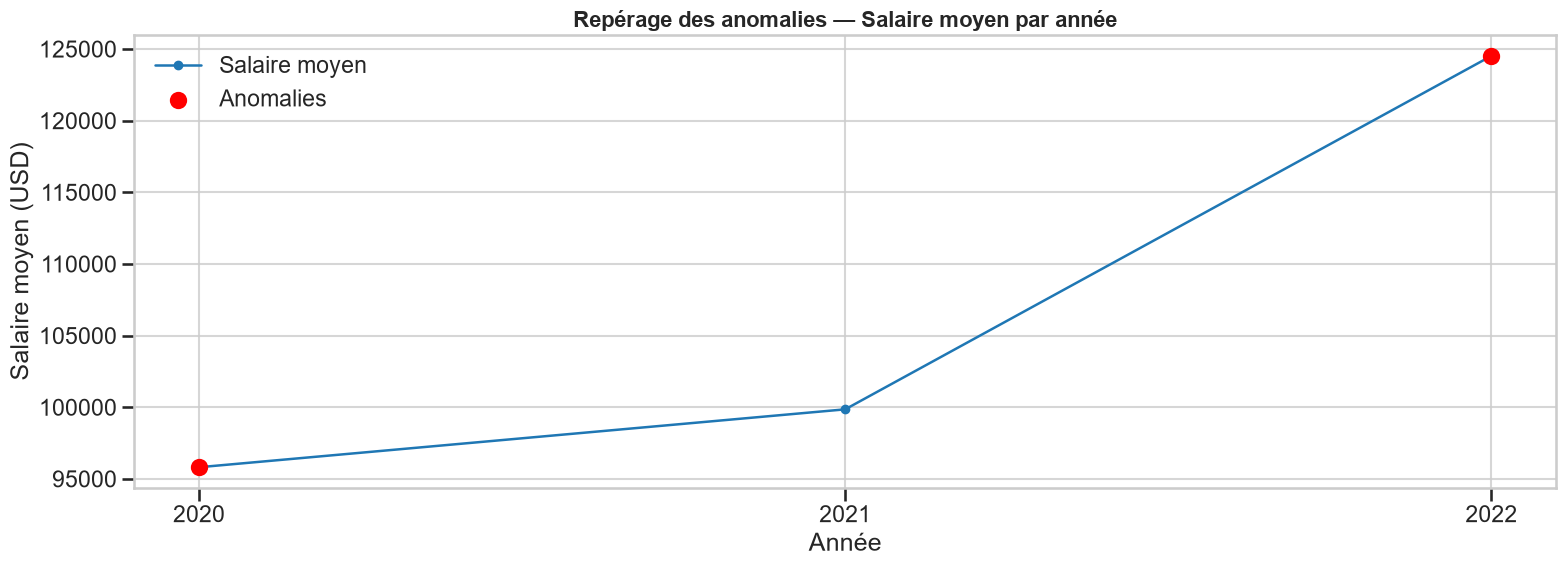

In [65]:
# Moyenne du salaire par année
df_avg = data.groupby("work_year")["salary_in_usd"].mean().reset_index()
df_avg["work_year"] = df_avg["work_year"].astype(int)

# Moyenne et écart-type
moyenne = df_avg["salary_in_usd"].mean()
ecart_type = df_avg["salary_in_usd"].std()


seuil_sup = moyenne + 0.5 * ecart_type
seuil_inf = moyenne - 0.5 * ecart_type

anomalies = df_avg[
    (df_avg["salary_in_usd"] > seuil_sup) | 
    (df_avg["salary_in_usd"] < seuil_inf)
]

# Tracé
plt.figure(figsize=(16, 6))
plt.plot(df_avg["work_year"], df_avg["salary_in_usd"],
         label="Salaire moyen", linewidth=1.8, marker="o", markersize=6)
plt.scatter(anomalies["work_year"], anomalies["salary_in_usd"],
            label="Anomalies", s=120, color="red", marker="o", zorder=5)


plt.xticks(df_avg["work_year"])

plt.title("Repérage des anomalies — Salaire moyen par année", fontsize=16, weight="bold")
plt.xlabel("Année")
plt.ylabel("Salaire moyen (USD)")
plt.legend()
plt.grid(True, alpha=0.8)
plt.tight_layout()
plt.show()

**inerprétation :** 

les années 2020 et 2022 présentent des anomalies, avec des salaires moyens plus élevés que la moyenne générale. Cela peut être dû à des facteurs tels que la pandémie de COVID-19,
qui a entraîné une augmentation de la demande pour les professionnels de la data science, ou à des changements dans les politiques salariales des entreprises.

### 6.6 Analyser la fréquence et la réparation dez événement dans le temps

#### **Histogramme temporel**

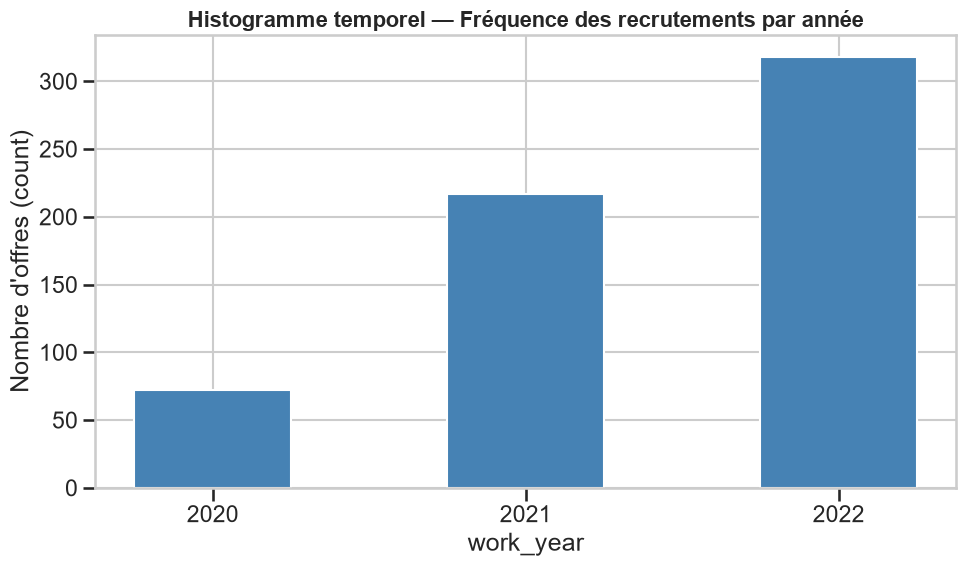

In [66]:
counts_par_annee = data["work_year"].value_counts().sort_index()

plt.figure(figsize=(10, 6))
plt.bar(counts_par_annee.index, counts_par_annee.values, color="steelblue", edgecolor="white", width=0.5)
plt.title("Histogramme temporel — Fréquence des recrutements par année",fontsize=16, weight="bold")
plt.xlabel("work_year")
plt.ylabel("Nombre d'offres (count)")
plt.xticks(counts_par_annee.index)
plt.tight_layout()
plt.show()

**Interprétation**
Le nombre d'offres dans les métiers de la data a connu une croissance continue et forte sur les trois années. Entre 2020 et 2021, les offres ont presque triplé, et entre 2021 et 2022, elles ont encore augmenté. Cette tendance reflète l'explosion de la demande en data science, notamment après la période COVID qui a accéléré la transformation numérique des entreprises.
**Décision**
Les recruteurs et entreprises doivent anticiper une demande croissante en profils data. Pour les candidats, c'est un marché de plus en plus favorable. Pour les établissements de formation, il faut augmenter les capacités en filières Big Data et IA pour répondre à ce besoin.

#### **Diagramme en barres par période**

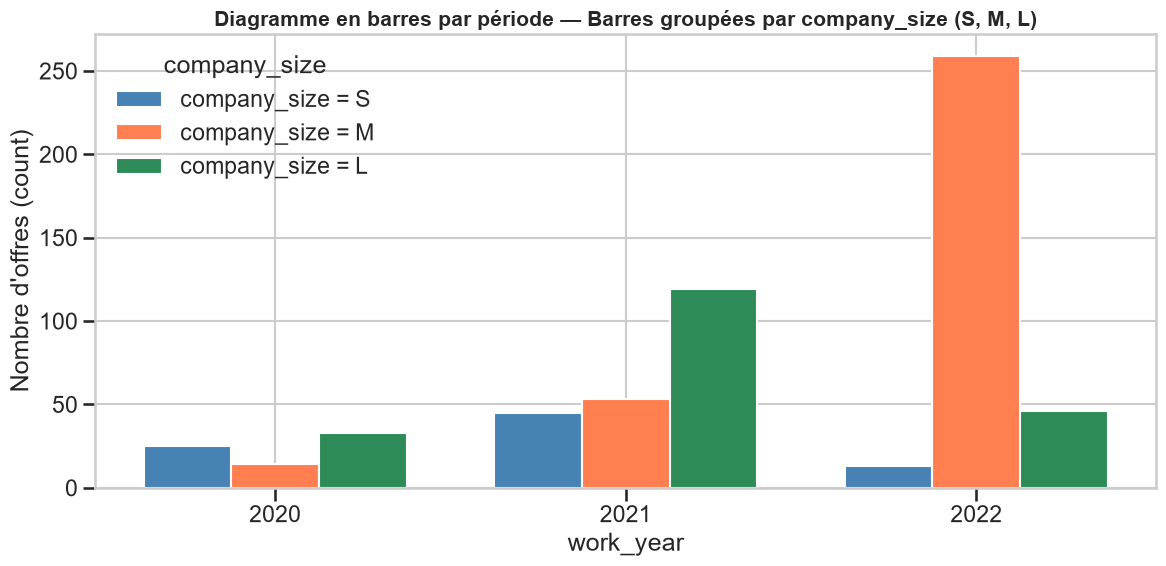

In [67]:
grouped = (
    data.groupby(["work_year", "company_size"])
    .size()
    .reset_index(name="count")
)

sizes   = ["S", "M", "L"]
couleurs_size = {"S": "steelblue", "M": "coral", "L": "seagreen"}
x       = np.arange(len(grouped["work_year"].unique()))
width   = 0.25

fig, ax = plt.subplots(figsize=(12, 6))

for i, size in enumerate(sizes):
    data1 = grouped[grouped["company_size"] == size].set_index("work_year")
    counts = [data1.loc[a, "count"] if a in data1.index else 0 for a in grouped["work_year"].unique()]
    ax.bar(x + i * width, counts, width, label=f"company_size = {size}", color=couleurs_size[size], edgecolor="white")

ax.set_title("Diagramme en barres par période — Barres groupées par company_size (S, M, L)", fontsize=15, weight="bold")
ax.set_xlabel("work_year")
ax.set_ylabel("Nombre d'offres (count)")
ax.set_xticks(x + width)
ax.set_xticklabels(grouped["work_year"].unique())
ax.legend(title="company_size")
plt.tight_layout()
plt.show()

**Interprétation**
- **2020** : les grandes entreprises (L) dominent légèrement, avec une répartition assez équilibrée entre les trois tailles.
- **2021** : forte hausse généralisée, mais ce sont surtout les grandes entreprises (L = 119) qui recrutent massivement, elles captent plus de la moitié des offres.
- **2022** : renversement spectaculaire, les entreprises de taille moyenne (M) explosent à 259 offres, dépassant largement les grandes (46) et les petites (13). Cela indique une démocratisation du recrutement data vers des entreprises en pleine croissance.

**Décision**
Le marché de la data n'est plus réservé aux grands groupes. En 2022, les entreprises moyennes deviennent le principal recruteur. Les candidats ont intérêt à ne pas se limiter aux grandes entreprises dans leur recherche d'emploi. Pour les investisseurs et décideurs, ce signal indique que les PME intègrent massivement la data dans leur stratégie, ce qui représente une opportunité de marché importante (outils, conseil, formation).

## 7. Visualisation Geospatiale 

In [68]:
import geopandas as gpd
import geodatasets
from shapely.geometry import LineString
from graphviz import Digraph
import pycountry

### 7.1 Localiser des objets ou événements dans l'espace

In [69]:
from geopy.geocoders import Nominatim
# Nominatim est un service de géocodage :
# il permet de transformer un nom de lieu en coordonnées géographiques

from geopy.extra.rate_limiter import RateLimiter
# RateLimiter permet de ralentir les requêtes envoyées au service
# pour éviter d'en envoyer trop rapidement


#Création du géocodeur
# On crée un objet géocodeur
# user_agent est juste un identifiant du script
geolocator = Nominatim(user_agent="tp_geospatial")


#Ajout d'un délai
# On utilise la fonction geocode avec un délai de 1 seconde
# entre deux requêtes pour éviter de surcharger le service
geocode = RateLimiter(geolocator.geocode, min_delay_seconds=1)


#Fonction de géocodage
def get_location(company_location):
    # Cette fonction reçoit en entrée le nom d'une company_location
    
    location = geocode(company_location)
    # On envoie le nom de la company_location au service de géocodage
    # Le résultat est stocké dans la variable location
    
    if location is not None:
        # Si la company_location est trouvée, on retourne :
        # latitude et longitude
        return pd.Series([location.latitude, location.longitude])
    else:
        # Si la company_location n'est pas trouvée, on retourne des valeurs vides
        return pd.Series([None, None])

#Ajout des colonnes
data[["latitude", "longitude"]] = data["company_location"].apply(get_location)

In [70]:
gdf = gpd.GeoDataFrame(
    data,
    geometry=gpd.points_from_xy(data["longitude"], data["latitude"]),
    crs="EPSG:4326"
)

In [71]:
print(gdf)

     Unnamed: 0  work_year experience_level employment_type  \
0             0       2020               MI              FT   
1             1       2020               SE              FT   
2             2       2020               SE              FT   
3             3       2020               MI              FT   
4             4       2020               SE              FT   
..          ...        ...              ...             ...   
602         602       2022               SE              FT   
603         603       2022               SE              FT   
604         604       2022               SE              FT   
605         605       2022               SE              FT   
606         606       2022               MI              FT   

                      job_title  salary salary_currency  salary_in_usd  \
0                Data Scientist   70000             EUR          79833   
1    Machine Learning Scientist  260000             USD         260000   
2             Big Dat

In [ ]:
world = gpd.read_file(geodatasets.get_path("naturalearth.land"))

# Agrégation par pays
country_salary = (
    gdf.groupby("company_location")
    .agg(
        avg_salary=("salary_in_usd", "mean"),
        latitude=("latitude", "first"),
        longitude=("longitude", "first")
    )
    .reset_index()
    .dropna(subset=["latitude", "longitude"])
    .reset_index(drop=True)
)

fig, ax = plt.subplots(1, 1, figsize=(15, 8))

world.plot(ax=ax, color="whitesmoke", edgecolor="lightgray", linewidth=0.4)

scatter = ax.scatter(
    country_salary["longitude"],
    country_salary["latitude"],
    c=country_salary["avg_salary"],
    s=40,
    cmap="RdYlGn",
    alpha=0.8
)

for i in range(len(country_salary)):
    ax.text(
        country_salary.loc[i, "longitude"] + 2,
        country_salary.loc[i, "latitude"] + 1,
        country_salary.loc[i, "company_location"],
        fontsize=9
    )

cbar = plt.colorbar(scatter, ax=ax, shrink=0.5)
cbar.set_label("Salaire moyen (USD)")

ax.set_title("Carte de points — Localisation des entreprises par salaire moyen",
             fontsize=16, fontweight="bold")
ax.set_axis_off()
plt.tight_layout()
plt.show()

La carte montre la répartition géographique des salaires moyens à l’échelle mondiale. On observe de fortes disparités entre les pays. Les salaires les plus élevés se concentrent dans les pays développés, notamment en Amérique du Nord et en Océanie. À l’inverse, les salaires sont plus faibles dans les pays en développement, comme en Afrique et en Amérique du Sud. L’Europe présente des niveaux intermédiaires et relativement homogènes. Ces écarts s’expliquent par le niveau de développement économique, le coût de la vie et la demande en compétences.

### 7.2 Comparer les valeurs entre plusieurs zones géographiques 


Company_Location VS salary_in_usd

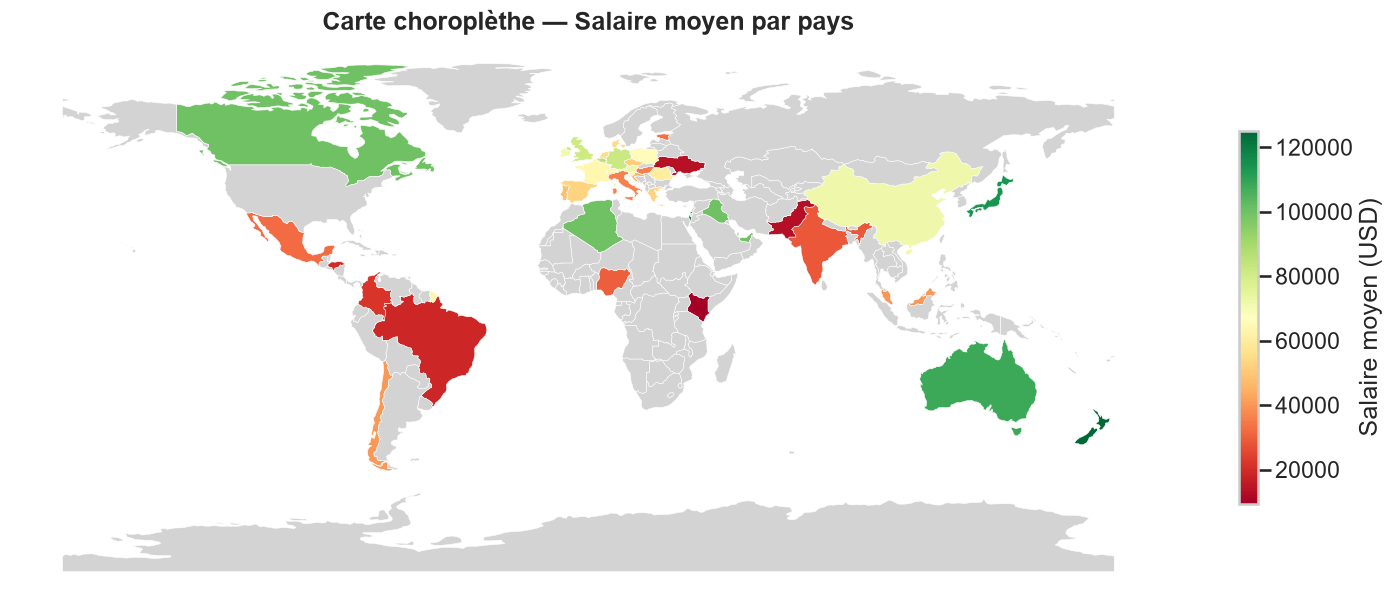

In [73]:
# ----- Préparation des données -----
salary_par_pays = data.groupby("company_location")["salary_in_usd"].mean().reset_index()
salary_par_pays.columns = ["company_location", "salary_moyen"]

# Conversion ISO-2 vers nom de pays
def iso2_to_name(code):
    try:
        return pycountry.countries.get(alpha_2=code).name
    except:
        return None

salary_par_pays["pays"] = salary_par_pays["company_location"].apply(iso2_to_name)

# ----- Version 1 : geopandas + matplotlib -----
url = "https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip"
world = gpd.read_file(url)

world_merged = world.merge(salary_par_pays, left_on="ADMIN", right_on="pays", how="left")

fig, ax = plt.subplots(1, 1, figsize=(15, 8))

world_merged.plot(
    column="salary_moyen",
    ax=ax,
    cmap="RdYlGn",
    legend=True,
    legend_kwds={
        "label": "Salaire moyen (USD)",
        "orientation": "vertical",
        "shrink": 0.5
    },
    missing_kwds={
        "color": "lightgrey",
        "label": "Pas de données"
    },
    edgecolor="white",
    linewidth=0.4
)

ax.set_title("Carte choroplèthe — Salaire moyen par pays", fontsize=18, fontweight="bold")
ax.set_axis_off()
plt.tight_layout()
plt.show()

# ----- Version 2 : Plotly -----
import plotly.express as px

fig = px.choropleth(
    salary_par_pays,
    locations="pays",
    locationmode="country names",
    color="salary_moyen",
    color_continuous_scale="RdYlGn",
    hover_name="pays",
    hover_data={"salary_moyen": True},
    labels={"salary_moyen": "Salaire moyen (USD)"},
    title="Carte choroplèthe — Salaire moyen par pays",
    width=1200,
    height=600
)

fig.show()

**Interprétation :**

"La carte choroplèthe révèle des disparités salariales importantes entre les pays. Les USA, Canada et Russie dominent avec des salaires supérieurs à 120 000 USD (vert foncé), suivis par l'Australie entre 80 000 et 120 000 USD (vert clair). La Chine et l'Europe se situent dans la moyenne mondiale entre 60 000 et 80 000 USD (jaune). L'Amérique du Sud et l'Inde affichent les salaires les plus faibles inférieurs à 40 000 USD (rouge). Les pays en gris n'ont pas de données disponibles." 

**Décision :**

Face aux fortes disparités salariales observées entre les pays, les entreprises des pays à faibles salaires comme le Brésil et l'Inde doivent revoir leur politique de rémunération pour retenir leurs talents en Data Science, qui sont fortement attirés par les opportunités offertes aux États-Unis, au Canada et en Russie. Les gouvernements de ces pays doivent également investir dans des politiques d'attractivité pour éviter la fuite des cerveaux. Pour les professionnels en Data Science, cibler les entreprises nord-américaines reste la meilleure stratégie pour maximiser leur salaire."

### 7.3 Représenter l'intensité dun phénomène en chaque lieu 

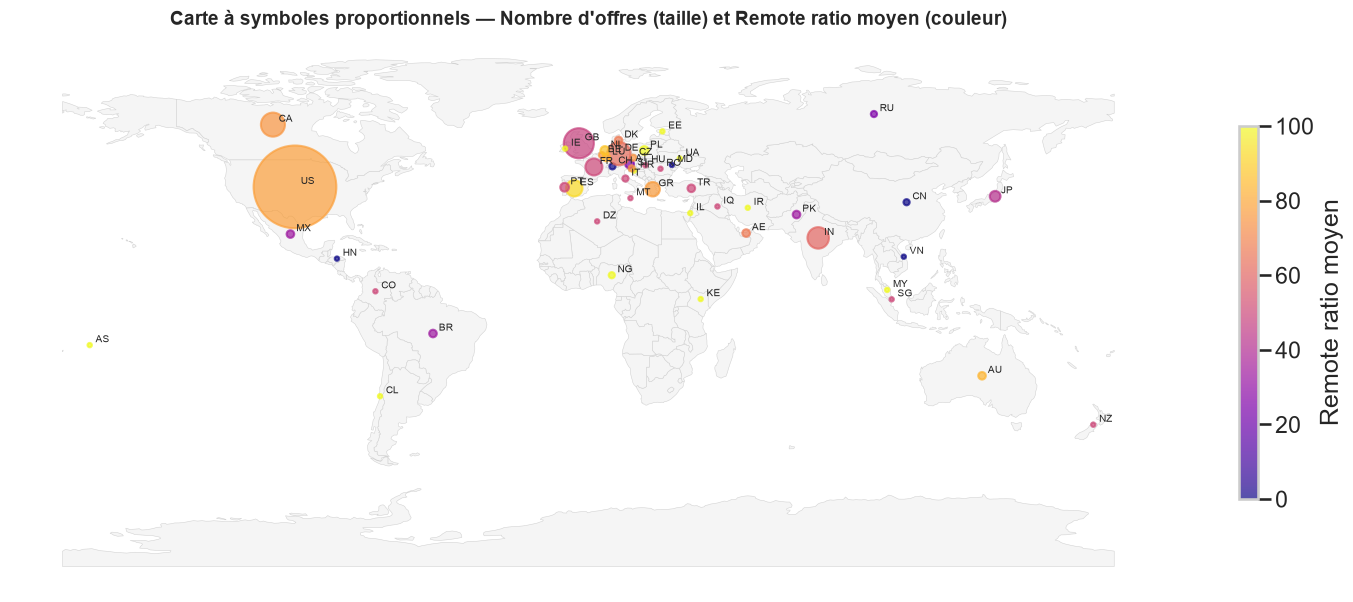

In [74]:
# ── Agrégation par pays ────────────────────────────────────────────
country_remote = (
    data.groupby("company_location")
    .agg(
        count=("company_location", "size"),
        remote_ratio_mean=("remote_ratio", "mean"),
        latitude=("latitude", "first"),
        longitude=("longitude", "first")
    )
    .reset_index()
    .dropna(subset=["latitude", "longitude"])
    .reset_index(drop=True)
)

# ── Carte à symboles proportionnels ───────────────────────────────
fig, ax = plt.subplots(1, 1, figsize=(15, 8))

world.plot(
    ax=ax,
    color="whitesmoke",
    edgecolor="lightgray",
    linewidth=0.4
)

scatter = ax.scatter(
    country_remote["longitude"],
    country_remote["latitude"],
    c=country_remote["remote_ratio_mean"],   # couleur = remote_ratio moyen
    s=country_remote["count"] * 10,          # taille = nombre d'offres
    cmap="plasma",
    alpha=0.7,
    zorder=5
)

# Noms des pays
for i in range(len(country_remote)):
    ax.text(
        country_remote.loc[i, "longitude"] + 2,
        country_remote.loc[i, "latitude"] + 1,
        country_remote.loc[i, "company_location"],
        fontsize=7,
        zorder=6
    )

cbar = plt.colorbar(scatter, ax=ax, shrink=0.5)
cbar.set_label("Remote ratio moyen")

ax.set_title(
    "Carte à symboles proportionnels — Nombre d'offres (taille) et Remote ratio moyen (couleur)",
    fontsize=14, fontweight="bold"
)
ax.set_axis_off()
plt.tight_layout()
plt.show()

- Les États-Unis dominent largement avec la plus forte intensité (plus grand cercle)
- L’Europe présente une forte concentration de pays avec des intensités moyennes
- Certains pays comme le Canada, l’Inde ou le Japon montrent des niveaux significatifs mais inférieurs aux États-Unis
- Plusieurs pays ont une faible intensité (petits cercles), indiquant une activité ou présence limitée
- Le type de travail varie fortement selon les pays, sans distribution uniforme
- Certaines régions combinent forte intensité et un taux élevé de travail à distance, ce qui peut indiquer une adoption importante de ce type de travail.
- Globalement,il existe une inégalité géographique importante dans la répartition du phénomène étudié

### 7.4 Détecter des concentrations ou zones denses

In [75]:
df_pays = data["employee_residence"].value_counts().reset_index()
df_pays.columns = ["iso2", "count"]

print("\nDonnées par pays :")
print(df_pays.head())


Données par pays :
  iso2  count
0   US    332
1   GB     44
2   IN     30
3   CA     29
4   DE     25


In [76]:
url = "https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip"
world = gpd.read_file(url)

print("\nColonnes disponibles dans le fond de carte :")
print(world.columns)


Colonnes disponibles dans le fond de carte :
Index(['featurecla', 'scalerank', 'LABELRANK', 'SOVEREIGNT', 'SOV_A3',
       'ADM0_DIF', 'LEVEL', 'TYPE', 'TLC', 'ADMIN',
       ...
       'FCLASS_TR', 'FCLASS_ID', 'FCLASS_PL', 'FCLASS_GR', 'FCLASS_IT',
       'FCLASS_NL', 'FCLASS_SE', 'FCLASS_BD', 'FCLASS_UA', 'geometry'],
      dtype='str', length=169)


In [77]:
world_merged = world.merge(df_pays, left_on="ISO_A2", right_on="iso2", how="left")

print("\nDonnées fusionnées :")
print(world_merged[["ADMIN", "count"]].head())


Données fusionnées :
                         ADMIN  count
0                         Fiji    NaN
1  United Republic of Tanzania    NaN
2               Western Sahara    NaN
3                       Canada   29.0
4     United States of America  332.0


In [78]:
world_merged["count"] = world_merged["count"].fillna(0)

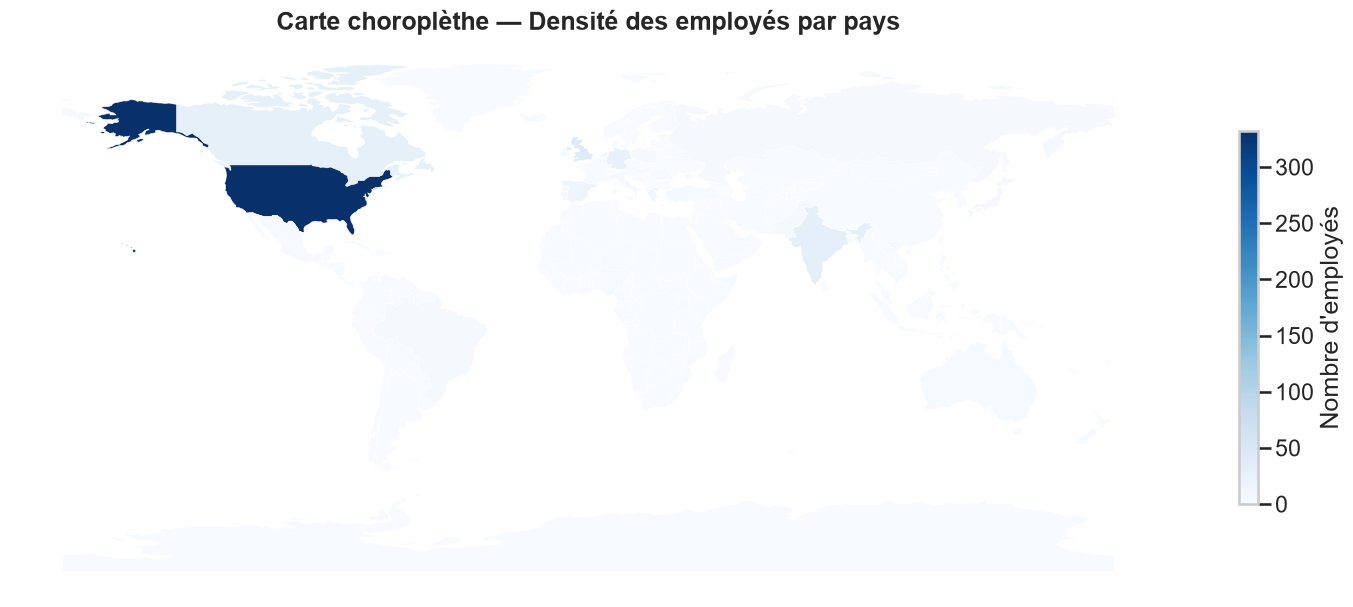

In [79]:
fig, ax = plt.subplots(1, 1, figsize=(15, 8))

world_merged.plot(
    column="count",
    ax=ax,
    cmap="Blues",  # adapté (densité)
    legend=True,
    legend_kwds={
        "label": "Nombre d'employés",
        "orientation": "vertical",
        "shrink": 0.5
    },
    missing_kwds={
        "color": "lightgrey",
        "label": "Pas de données"
    },
    edgecolor="white",
    linewidth=0.4
)

ax.set_title("Carte choroplèthe — Densité des employés par pays", 
             fontsize=18, fontweight="bold")

ax.set_axis_off()
plt.tight_layout()
plt.show()

**intérprétation :** 

d'après la carte choroplèthe, on observe que les États-Unis ont la plus forte concentration d'employés dans le domaine de la data science, suivis par des pays comme le Royaume-Uni, l'Allemagne et l'Inde. 
Cette répartition peut être liée à la taille des marchés technologiques, à la présence d'entreprises innovantes et à l'investissement dans les technologies de l'information dans ces pays. En revanche, certains pays d'Afrique et d'Amérique du Sud montrent une faible densité d'employés,
ce qui peut indiquer des opportunités de croissance dans ces régions.
#Décision : les entreprises et les professionnels de la data science pourraient envisager d'explorer les marchés émergents dans les régions sous-représentées, tout en continuant à renforcer leur présence dans les pays déjà bien établis.

### 7.5 Montrer des déplacements entre pays

**Carte de Flux**

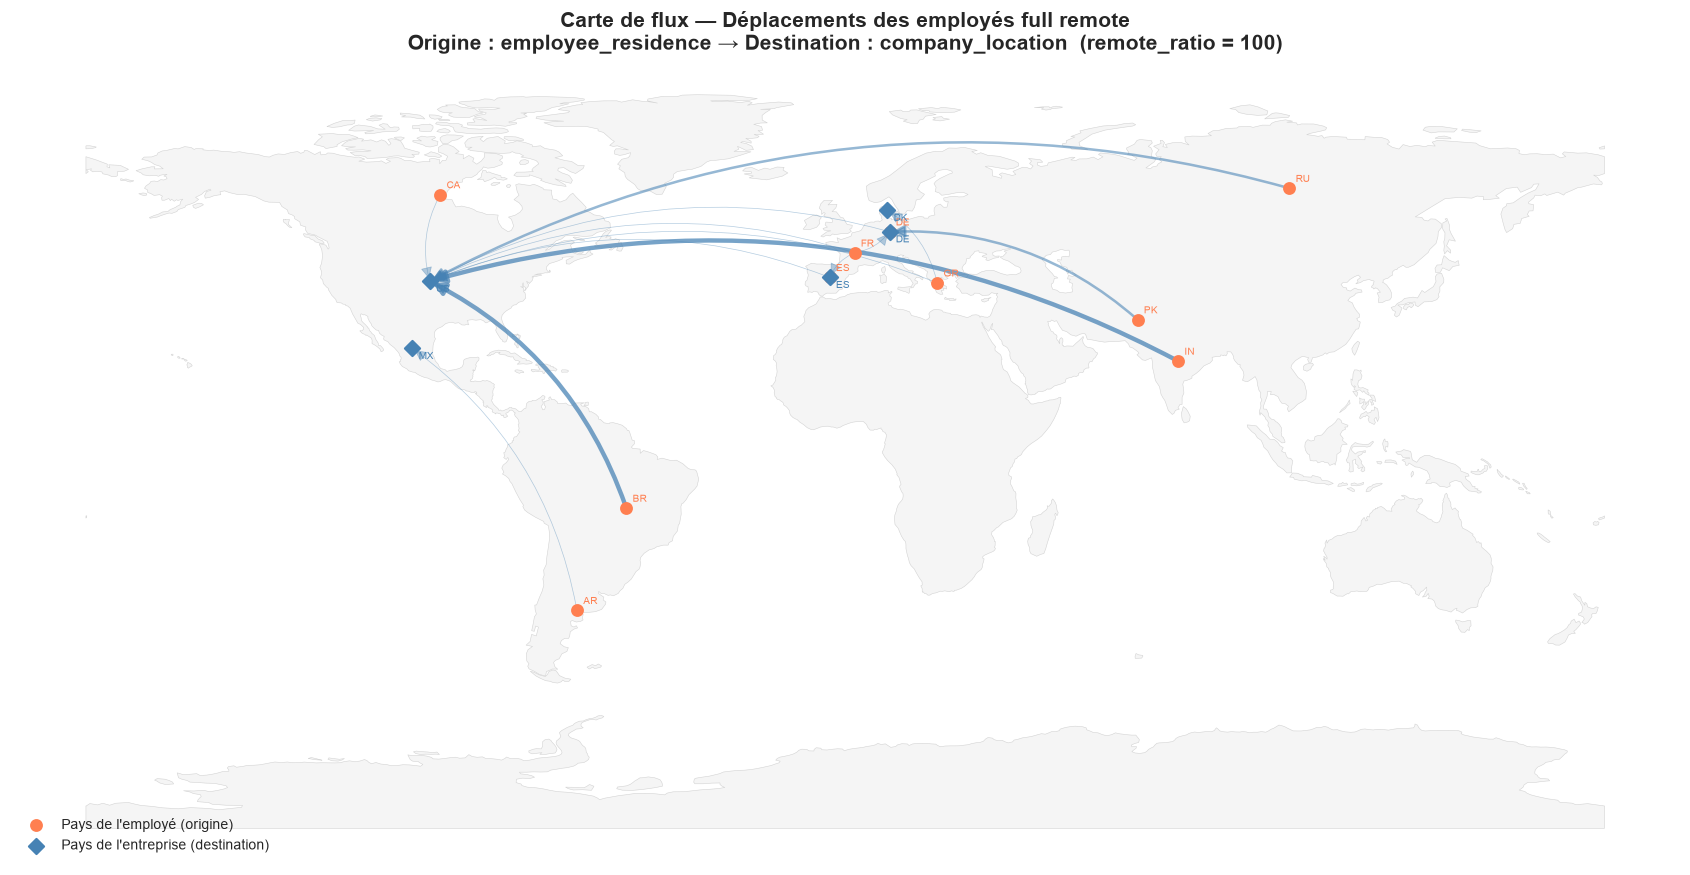


Top 15 des flux (remote_ratio = 100) :
employee_residence company_location  intensite
                BR               US          3
                IN               US          3
                PK               DE          2
                RU               US          2
                AR               MX          1
                CA               US          1
                DE               US          1
                ES               US          1
                FR               DE          1
                FR               ES          1
                FR               US          1
                GR               DK          1
                GR               US          1


In [80]:
# ── Filtrage : uniquement les employés full remote (remote_ratio = 100) ─────
df_flux = data[data["remote_ratio"] == 100].copy()

# ── Comptage des flux (employee_residence → company_location) ──────────────
flux = (
    df_flux.groupby(["employee_residence", "company_location"])
    .size()
    .reset_index(name="intensite")
)

# Garder uniquement les flux entre pays différents
flux = flux[flux["employee_residence"] != flux["company_location"]]

# Garder les 15 flux les plus importants pour la lisibilité
flux = flux.nlargest(15, "intensite").reset_index(drop=True)

# ── Coordonnées des pays (centroïdes approximatifs) ────────────────────────
country_coords = {
    "US": (-98.5,  39.5),  "GB": (-3.0,  54.0),  "CA": (-96.0, 60.0),
    "IN": (78.9,   20.6),  "DE": (10.5,  51.2),  "FR": ( 2.2,  46.2),
    "AU": (133.8, -25.3),  "ES": (-3.7,  40.4),  "NL": ( 5.3,  52.1),
    "BR": (-51.9, -14.2),  "PL": (19.1,  51.9),  "PT": (-8.2,  39.4),
    "NG": ( 8.7,   9.1),   "MX": (-102.6, 23.6), "JP": (138.3, 36.2),
    "RU": (105.3, 61.5),   "PK": (69.3,  30.4),  "CO": (-74.3,  4.6),
    "GR": (21.8,  39.1),   "AR": (-63.6, -38.4), "IT": (12.6,  41.9),
    "SE": (18.6,  60.1),   "SG": (103.8,  1.4),  "HU": (19.5,  47.2),
    "AT": (14.5,  47.5),   "IE": (-8.2,  53.4),  "DK": (10.0,  56.3),
    "HR": (15.2,  45.1),   "UA": (31.2,  48.4),  "RO": (24.9,  45.9),
    "CZ": (15.5,  49.8),   "BE": ( 4.5,  50.5),  "CH": ( 8.2,  46.8),
    "TR": (35.2,  38.9),   "LT": (23.9,  55.2),  "TH": (100.9, 15.9),
    "EG": (30.8,  26.8),   "ZA": (25.1, -29.0),  "PH": (122.9, 12.9),
}

# ── Ajout des coordonnées ──────────────────────────────────────────────────
flux["lon_orig"] = flux["employee_residence"].map(lambda c: country_coords.get(c, (None,None))[0])
flux["lat_orig"] = flux["employee_residence"].map(lambda c: country_coords.get(c, (None,None))[1])
flux["lon_dest"] = flux["company_location"].map(lambda c: country_coords.get(c, (None,None))[0])
flux["lat_dest"] = flux["company_location"].map(lambda c: country_coords.get(c, (None,None))[1])

flux = flux.dropna()

# ── Fond de carte ──────────────────────────────────────────────────────────
world = gpd.read_file(geodatasets.get_path("naturalearth.land"))

# ── Carte de flux ──────────────────────────────────────────────────────────
fig, ax = plt.subplots(1, 1, figsize=(18, 9))

world.plot(ax=ax, color="whitesmoke", edgecolor="lightgray", linewidth=0.4)

# Normalisation de l'épaisseur des arcs selon l'intensité
intensite_max = flux["intensite"].max()
intensite_min = flux["intensite"].min()

for _, row in flux.iterrows():
    # Épaisseur proportionnelle à l'intensité
    lw = 0.5 + 4 * (row["intensite"] - intensite_min) / (intensite_max - intensite_min + 1)
    alpha = 0.4 + 0.5 * (row["intensite"] - intensite_min) / (intensite_max - intensite_min + 1)

    ax.annotate(
        "",
        xy    =(row["lon_dest"], row["lat_dest"]),
        xytext=(row["lon_orig"], row["lat_orig"]),
        arrowprops=dict(
            arrowstyle="-|>",
            color="steelblue",
            lw=lw,
            alpha=alpha,
            connectionstyle="arc3,rad=0.2"   # arc courbé
        )
    )

# Points d'origine (employee_residence)
origins = flux[["employee_residence", "lon_orig", "lat_orig"]].drop_duplicates()
ax.scatter(origins["lon_orig"], origins["lat_orig"],
           color="coral", s=60, zorder=5, label="Pays de l'employé (origine)")

# Points de destination (company_location)
dests = flux[["company_location", "lon_dest", "lat_dest"]].drop_duplicates()
ax.scatter(dests["lon_dest"], dests["lat_dest"],
           color="steelblue", s=60, zorder=5, marker="D", label="Pays de l'entreprise (destination)")

# Étiquettes des pays
for _, row in origins.iterrows():
    ax.text(row["lon_orig"] + 1.5, row["lat_orig"] + 1.5,
            row["employee_residence"], fontsize=7, color="coral")

for _, row in dests.iterrows():
    ax.text(row["lon_dest"] + 1.5, row["lat_dest"] - 2.5,
            row["company_location"], fontsize=7, color="steelblue")

ax.set_title(
    "Carte de flux — Déplacements des employés full remote\n"
    "Origine : employee_residence → Destination : company_location  (remote_ratio = 100)",
    fontsize=15, fontweight="bold"
)
ax.legend(loc="lower left", fontsize=10)
ax.set_axis_off()
plt.tight_layout()
plt.show()

# ── Tableau récapitulatif des flux ─────────────────────────────────────────
print("\nTop 15 des flux (remote_ratio = 100) :")
print(flux[["employee_residence", "company_location", "intensite"]].to_string(index=False))

**Interprétation**
- Les États-Unis (US) sont le centre de gravité absolu.
- Presque tous les arcs convergent vers US — c'est la principale destination des employés full remote.
- Les entreprises américaines recrutent massivement à l'international sans exiger de présence physique.
- Les pays d'origine sont très diversifiés géographiquement, On retrouve des employés venant de :
Europe : CA (Canada), ES (Espagne), FR (France), DE (Allemagne)
Amérique Latine : BR (Brésil), MX (Mexique), AR (Argentine)
Asie : IN (Inde), PK (Pakistan), RU (Russie)

- Les flux les plus épais partent de CA, IN et BR vers US.
- L'épaisseur des arcs indique que le Canada, l'Inde et le Brésil sont les plus grands fournisseurs de talents data en full remote pour les entreprises américaines.
- Les destinations non-US sont rares , DE (Allemagne) et GB apparaissent comme destinations secondaires, mais avec des flux beaucoup plus faibles — l'Europe recrute peu en full remote cross-border comparé aux USA.
**Décisions**

- Les entreprises souhaitant recruter des profils data devraient privilégier une politique full remote pour accéder à un vivier de talents mondial, notamment en ciblant des pays comme l'Inde, le Brésil et le Canada qui représentent les plus grands bassins de candidats disponibles.

- Pour les candidats en data science, il est stratégique de postuler directement auprès des entreprises américaines et allemandes, car elles concentrent la majorité des offres accessibles à distance, offrant ainsi de meilleures opportunités de carrière sans contrainte géographique.

# 8. Visualisation Geotemporelle

## 8.1 Carte pour une date

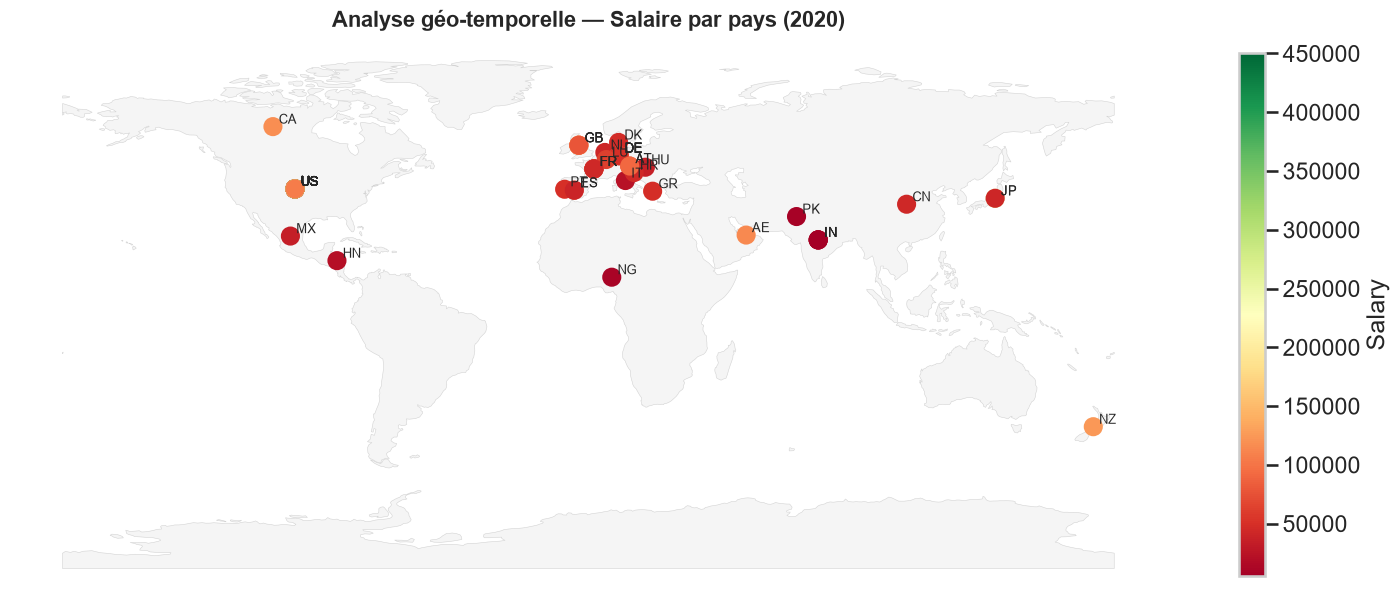

In [81]:
# Filtrer une année
df_year = data[data["work_year"] == 2020]

# Conversion en GeoDataFrame
gdf_year = gpd.GeoDataFrame(
    df_year,
    geometry=gpd.points_from_xy(df_year["longitude"], df_year["latitude"]),
    crs="EPSG:4326"
)

# Fond de carte
world = gpd.read_file(geodatasets.get_path("naturalearth.land"))

# Plot
fig, ax = plt.subplots(1, 1, figsize=(15, 8))

world.plot(ax=ax, color="whitesmoke", edgecolor="lightgray", linewidth=0.4)

scatter = ax.scatter(
    gdf_year["longitude"],
    gdf_year["latitude"],
    c=gdf_year["salary_in_usd"],
    s=150,
    cmap="RdYlGn"
)

for i in range(len(gdf_year)):
    ax.text(
        gdf_year.iloc[i]["longitude"] + 2,
        gdf_year.iloc[i]["latitude"] + 1,
        gdf_year.iloc[i]["company_location"],
        fontsize=9
    )

cbar = plt.colorbar(scatter, ax=ax, shrink=0.7)
cbar.set_label("Salary")

ax.set_title("Analyse géo-temporelle — Salaire par pays (2020)", fontsize=16, fontweight="bold")
ax.set_axis_off()
plt.tight_layout()
plt.show()

## 8.2 Comparer plusieurs années

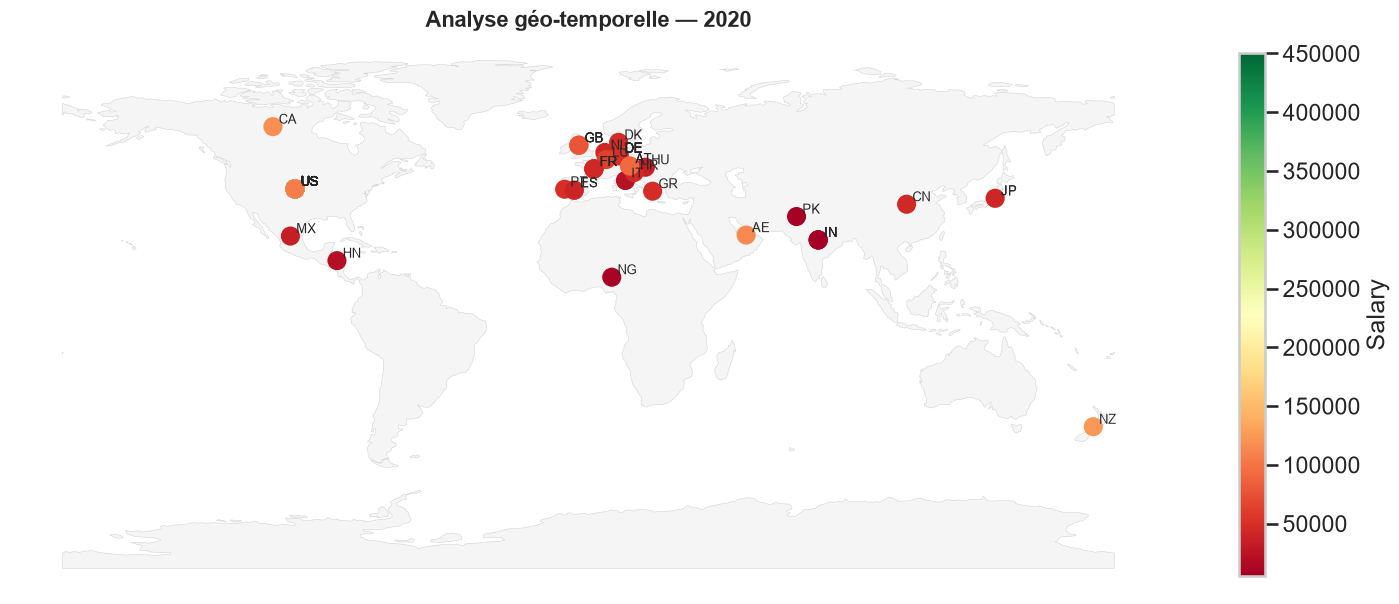

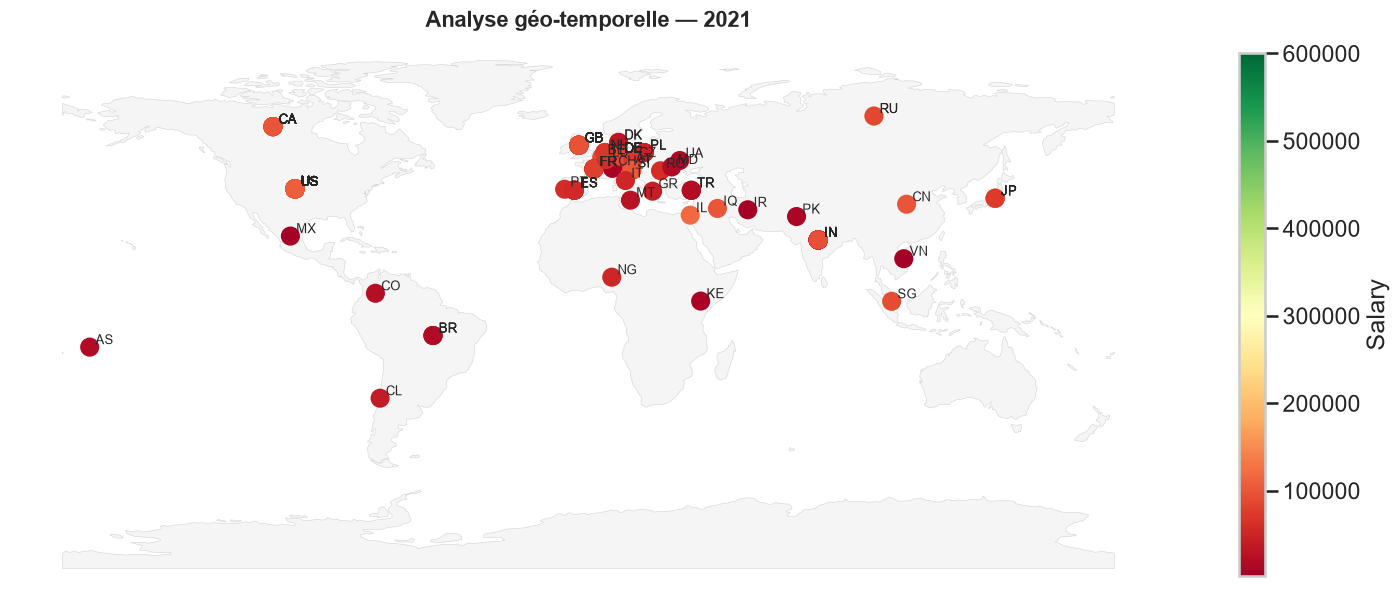

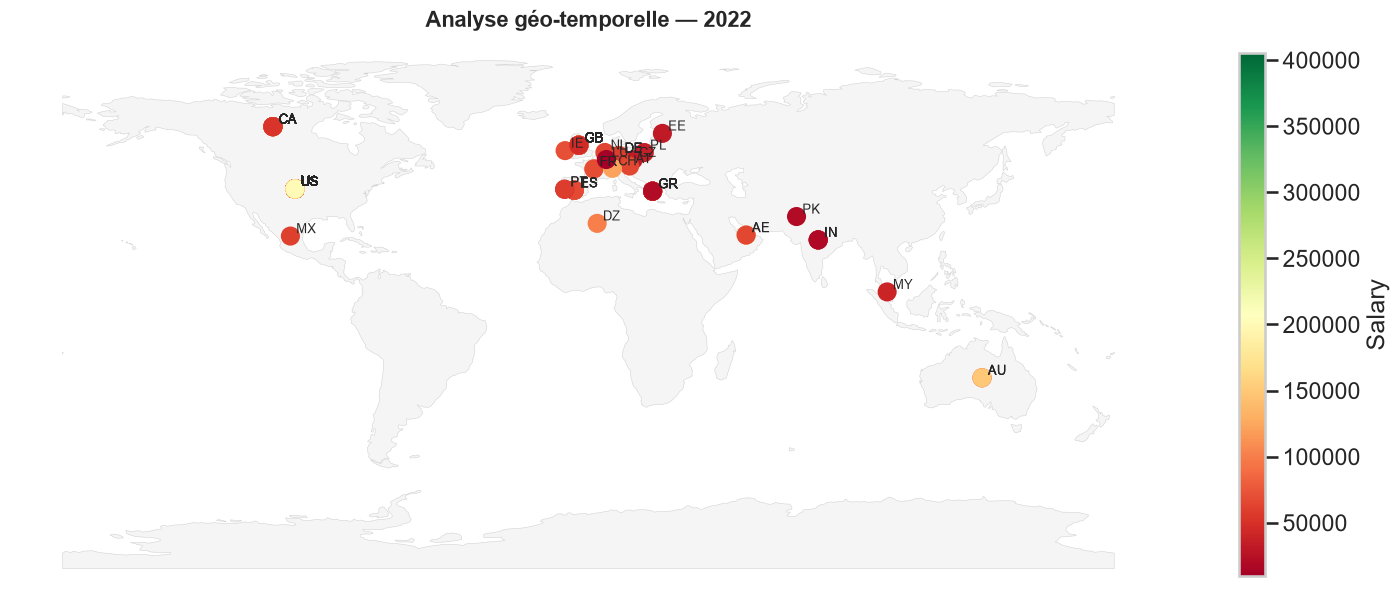

In [82]:
years = data["work_year"].sort_values().unique()

for y in years:
    df_temp = data[data["work_year"] == y]

    gdf_temp = gpd.GeoDataFrame(
        df_temp,
        geometry=gpd.points_from_xy(df_temp["longitude"], df_temp["latitude"]),
        crs="EPSG:4326"
    )

    fig, ax = plt.subplots(1, 1, figsize=(15, 8))

    world.plot(ax=ax, color="whitesmoke", edgecolor="lightgray", linewidth=0.4)

    scatter = ax.scatter(
        gdf_temp["longitude"],
        gdf_temp["latitude"],
        c=gdf_temp["salary_in_usd"],
        s=150,
        cmap="RdYlGn"
    )

    for i in range(len(gdf_temp)):
        ax.text(
            gdf_temp.iloc[i]["longitude"] + 2,
            gdf_temp.iloc[i]["latitude"] + 1,
            gdf_temp.iloc[i]["company_location"],
            fontsize=9
        )

    cbar = plt.colorbar(scatter, ax=ax, shrink=0.7)
    cbar.set_label("Salary")

    ax.set_title(f"Analyse géo-temporelle — {y}", fontsize=16, fontweight="bold")
    ax.set_axis_off()
    plt.tight_layout()
    plt.show()



L’analyse géo-temporelle entre 2020, 2021 et 2022 met en évidence des évolutions différentes selon les pays. Les États-Unis maintiennent globalement les niveaux de salaires les plus élevés sur toute la période, avec une légère variation mais une position dominante constante. La France montre une progression notable entre 2020 et 2022, traduisant une croissance continue du marché. L’Espagne présente une évolution plus instable, avec une baisse en 2021 suivie d’une reprise en 2022. En revanche, le Japon affiche une diminution marquée entre 2020 et 2021 et n’apparaît plus en 2022, ce qui peut indiquer un manque de données ou une baisse d’activité. Globalement, cette comparaison révèle une tendance à la hausse dans certains pays, tandis que d’autres connaissent des fluctuations ou un recul, soulignant des dynamiques de marché différentes selon les régions.


Il est recommandé de prioriser les investissements et le recrutement aux États-Unis et en France, car ces pays présentent des niveaux de salaires élevés et/ou en croissance, indiquant un marché dynamique et attractif. En revanche, une approche prudente doit être adoptée pour des pays comme l’Espagne et le Japon, où l’on observe des fluctuations ou une baisse des salaires, ce qui peut refléter une instabilité du marché. Cette stratégie permet d’optimiser les ressources en ciblant les zones à fort potentiel tout en limitant les risques.

## 8.3 Courbes temporelles pour un pays

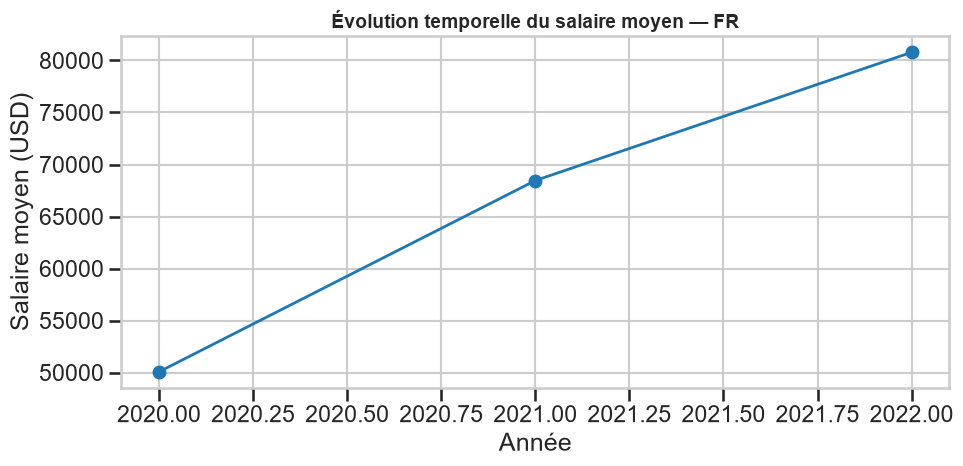

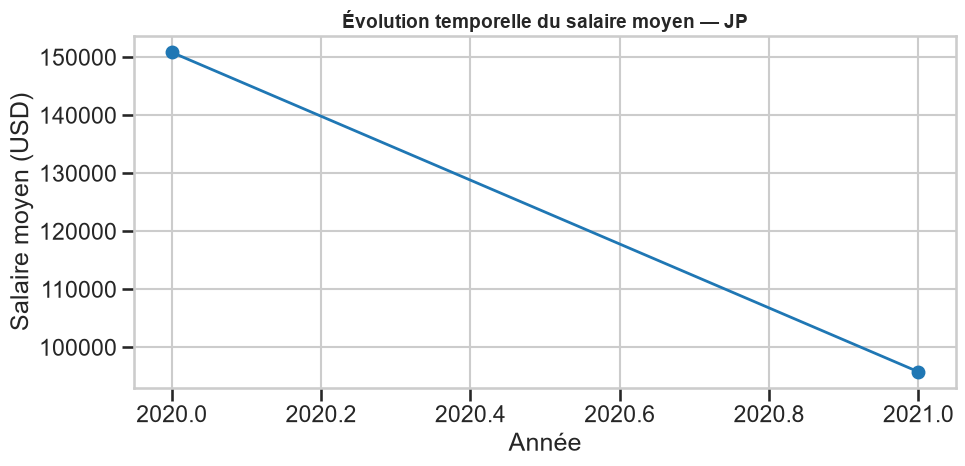

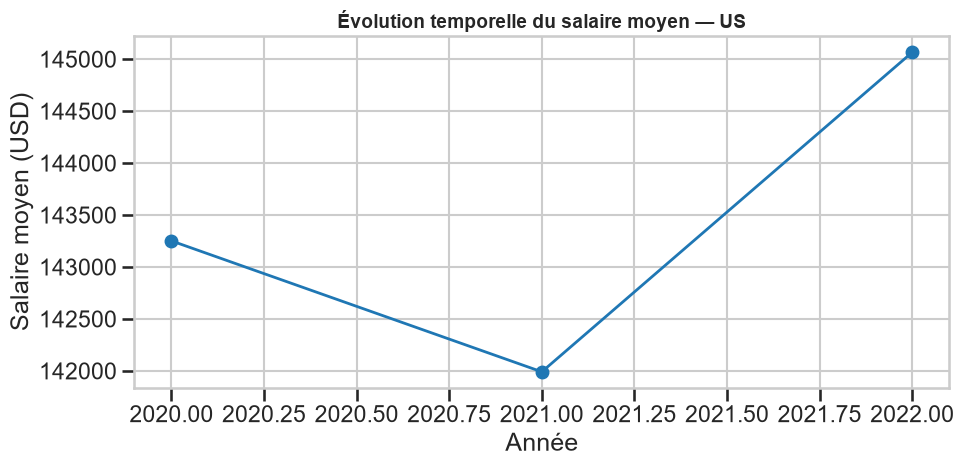

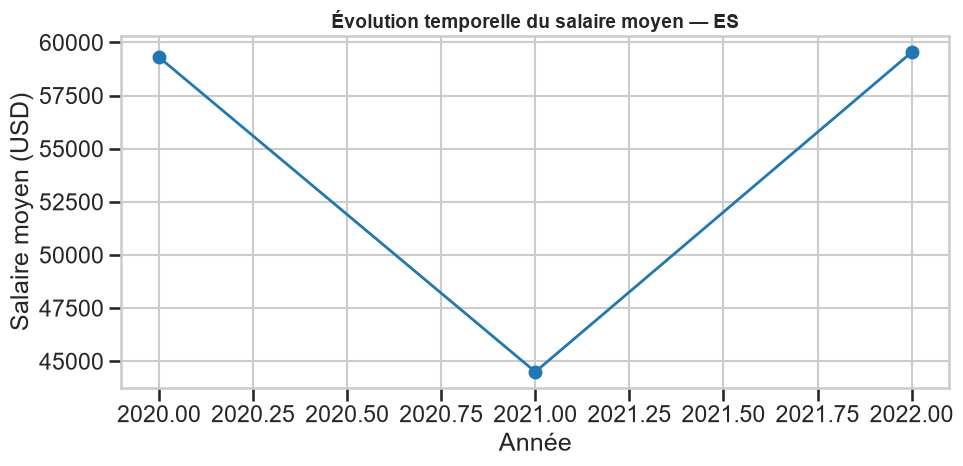

In [83]:
pays_list = ["FR", "JP", "US", "ES"]

for pays in pays_list :
    df_pays = data[data["company_location"] == pays]

    # Moyenne par année
    df_grouped = df_pays.groupby("work_year")["salary_in_usd"].mean().reset_index()

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(df_grouped["work_year"], df_grouped["salary_in_usd"], marker="o", linewidth=2)

    ax.set_title(f"Évolution temporelle du salaire moyen — {pays}", fontsize=14, fontweight="bold")
    ax.set_xlabel("Année")
    ax.set_ylabel("Salaire moyen (USD)")
    plt.tight_layout()
    plt.show()

**🇫🇷 France (FR)**

On observe une augmentation continue du salaire moyen en France entre 2020 et 2022. Le salaire passe d’environ 50 000 USD en 2020 à plus de 80 000 USD en 2022, avec une progression régulière chaque année. Cette évolution montre une amélioration stable du marché de l’emploi dans le domaine étudié, probablement liée à une demande croissante pour les compétences en data.

**🇯🇵 Japon (JP)**

Contrairement aux autres pays, le Japon présente une diminution notable du salaire moyen entre 2020 et 2021, passant d’environ 150 000 USD à moins de 100 000 USD. Cette baisse peut indiquer une réduction de la demande, un changement dans la structure des postes, ou une variation dans les profils recrutés. L’absence de données pour 2022 limite cependant l’analyse complète.

**🇺🇸 États-Unis (US)**

Les États-Unis montrent une légère fluctuation suivie d’une hausse. Après une petite baisse entre 2020 et 2021, le salaire moyen augmente pour atteindre environ 145 000 USD en 2022. Cela traduit un marché globalement stable avec une tendance à la hausse, confirmant la position dominante des États-Unis dans les métiers de la data.

**🇪🇸 Espagne (ES)**

L’Espagne présente une évolution en forme de “V”. Le salaire moyen diminue entre 2020 et 2021 (jusqu’à environ 45 000 USD), puis remonte en 2022 pour atteindre presque son niveau initial (près de 60 000 USD). Cette variation peut refléter une instabilité temporaire du marché, suivie d’une reprise.

Cette analyse géotemporelle permet d’identifier les marchés les plus attractifs. Les États-Unis et la France apparaissent comme des zones à fort potentiel, tandis que d’autres pays nécessitent une approche plus prudente.